In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. ĐỌC TẤT CẢ FILE CSV 30 PHÚT

In [2]:
# Đường dẫn đến thư mục chứa data 30p
data_path = Path('Upgit/data/Tan Hung_30p/224')

# Tìm tất cả file CSV
all_files = list(data_path.rglob('*.csv'))
print(f"Tìm thấy {len(all_files)} file CSV")

# Đọc tất cả file
print("\nĐang đọc dữ liệu...")
dfs = []

for idx, file in enumerate(all_files):
    try:
        df = pd.read_csv(file)
        df['source_file'] = file.name
        df['year'] = file.parent.name
        dfs.append(df)
        
        if (idx + 1) % 10 == 0:
            print(f"  Đã đọc {idx + 1}/{len(all_files)} files...")
    except Exception as e:
        print(f"  Lỗi đọc {file.name}: {e}")

# Gộp tất cả dataframes
df_all = pd.concat(dfs, ignore_index=True)
print(f"\nĐã gộp xong! Tổng số records: {len(df_all):,}")

Tìm thấy 71 file CSV

Đang đọc dữ liệu...
  Đã đọc 10/71 files...
  Đã đọc 20/71 files...
  Đã đọc 30/71 files...
  Đã đọc 40/71 files...
  Đã đọc 50/71 files...
  Đã đọc 60/71 files...
  Đã đọc 70/71 files...

Đã gộp xong! Tổng số records: 712,736


In [3]:
# Parse datetime và sắp xếp
df_all['TIME'] = pd.to_datetime(df_all['TIME'])
df_all = df_all.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

print(f"Khoảng thời gian: {df_all['TIME'].min()} đến {df_all['TIME'].max()}")
print(f"Số điểm đo: {df_all['MaDiemDo'].nunique()}")
print(f"Các điểm đo: {sorted(df_all['MaDiemDo'].unique())}")

Khoảng thời gian: 2020-02-09 00:00:00 đến 2025-12-31 23:35:51
Số điểm đo: 7
Các điểm đo: [np.int64(4127), np.int64(4295), np.int64(4447), np.int64(4587), np.int64(4999), np.int64(8667), np.int64(9402)]


In [4]:
df_all.isna().sum()

MBA                0
MAMBA              0
MaDiemDo           0
TenDiemDo          0
TIME               0
UA             13387
UB             13387
UC             13384
IA               530
IB               780
IC               815
CosF             923
P_kW            1096
Q_kVAr           979
source_file        0
year               0
dtype: int64

In [5]:
## XỬ LÝ THEO NGUYÊN TẮC VẬT LÝ

print("=" * 80)
print("XỬ LÝ THEO NGUYÊN TẮC VẬT LÝ")
print("=" * 80)

# ============================================================================
# 1. XỬ LÝ CosF NGOÀI [-1, 1]
# ============================================================================
print("\n" + "=" * 80)
print("1. XỬ LÝ CosF NGOÀI [-1, 1]")
print("=" * 80)

# Kiểm tra CosF vi phạm
cosf_invalid = ((df_all['CosF'] < -1) | (df_all['CosF'] > 1)).sum()
print(f"\nSố records có CosF ngoài [-1, 1]: {cosf_invalid:,}")

if cosf_invalid > 0:
    # Thống kê chi tiết
    invalid_data = df_all[(df_all['CosF'] < -1) | (df_all['CosF'] > 1)]
    print(f"\nThống kê CosF vi phạm:")
    print(f"  Min: {invalid_data['CosF'].min():.4f}")
    print(f"  Max: {invalid_data['CosF'].max():.4f}")
    print(f"  Mean: {invalid_data['CosF'].mean():.4f}")
    
    # Phân bố theo trạm
    print(f"\nPhân bố theo trạm:")
    for station_id in sorted(df_all['MaDiemDo'].unique()):
        station_invalid = invalid_data[invalid_data['MaDiemDo'] == station_id]
        if len(station_invalid) > 0:
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {len(station_invalid):,} records")
    
    # Clip CosF về [-1, 1]
    df_all['CosF'] = df_all['CosF'].clip(-1, 1)
    
    print(f"\n✅ Đã clip {cosf_invalid:,} giá trị CosF về khoảng [-1, 1]")
else:
    print(f"\n✅ Tất cả CosF đều trong khoảng [-1, 1]")

# ============================================================================
# 2. KIỂM TRA MÂU THUẪN I=0 NHƯNG P>0
# ============================================================================
print("\n" + "=" * 80)
print("2. KIỂM TRA MÂU THUẪN I=0 NHƯNG P>0")
print("=" * 80)

# Kiểm tra mâu thuẫn: Tất cả 3 pha I=0 nhưng P>0
contradiction = (
    (df_all['IA'] == 0) & 
    (df_all['IB'] == 0) & 
    (df_all['IC'] == 0) & 
    (df_all['P_kW'] > 0)
).sum()

print(f"\nSố records có I=0 (cả 3 pha) nhưng P>0: {contradiction:,}")

if contradiction > 0:
    # Thống kê chi tiết
    contra_data = df_all[
        (df_all['IA'] == 0) & 
        (df_all['IB'] == 0) & 
        (df_all['IC'] == 0) & 
        (df_all['P_kW'] > 0)
    ]
    
    print(f"\nThống kê P trong các trường hợp mâu thuẫn:")
    print(f"  Min P: {contra_data['P_kW'].min():.2f} kW")
    print(f"  Max P: {contra_data['P_kW'].max():.2f} kW")
    print(f"  Mean P: {contra_data['P_kW'].mean():.2f} kW")
    
    # Phân bố theo trạm
    print(f"\nPhân bố theo trạm:")
    for station_id in sorted(df_all['MaDiemDo'].unique()):
        station_contra = contra_data[contra_data['MaDiemDo'] == station_id]
        if len(station_contra) > 0:
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {len(station_contra):,} records")
    
    # Hiển thị 10 ví dụ
    print(f"\n10 ví dụ đầu tiên:")
    print(contra_data[['TIME', 'MaDiemDo', 'TenDiemDo', 'IA', 'IB', 'IC', 'P_kW']].head(10))
    
    # Set P = 0 khi I = 0 (cả 3 pha)
    mask = (df_all['IA'] == 0) & (df_all['IB'] == 0) & (df_all['IC'] == 0) & (df_all['P_kW'] > 0)
    df_all.loc[mask, 'P_kW'] = 0
    
    print(f"\n✅ Đã set P = 0 cho {contradiction:,} records mâu thuẫn")
else:
    print(f"\n✅ Không có mâu thuẫn I=0 nhưng P>0")

# ============================================================================
# THỐNG KÊ SAU XỬ LÝ
# ============================================================================
print("\n" + "=" * 80)
print("THỐNG KÊ SAU XỬ LÝ")
print("=" * 80)

print(f"\nCosF:")
print(f"  Min: {df_all['CosF'].min():.4f}")
print(f"  Max: {df_all['CosF'].max():.4f}")
print(f"  Mean: {df_all['CosF'].mean():.4f}")

print(f"\nP_kW:")
print(f"  Min: {df_all['P_kW'].min():.2f} kW")
print(f"  Max: {df_all['P_kW'].max():.2f} kW")
print(f"  Mean: {df_all['P_kW'].mean():.2f} kW")

print("\n" + "=" * 80)
print("✅ Hoàn thành xử lý theo nguyên tắc vật lý!")
print("=" * 80)


XỬ LÝ THEO NGUYÊN TẮC VẬT LÝ

1. XỬ LÝ CosF NGOÀI [-1, 1]

Số records có CosF ngoài [-1, 1]: 81

Thống kê CosF vi phạm:
  Min: 1.1067
  Max: 97.0000
  Mean: 27.2463

Phân bố theo trạm:
  474 Tân Hưng (Mã 4295): 7 records
  476 Tân Hưng (Mã 4447): 3 records
  478 Tân Hưng (Mã 4587): 1 records
  TD2 Tân Hưng (Mã 4999): 20 records
  480 Tân Hưng (Mã 8667): 49 records
  T402 Tân Hưng (Mã 9402): 1 records

✅ Đã clip 81 giá trị CosF về khoảng [-1, 1]

2. KIỂM TRA MÂU THUẪN I=0 NHƯNG P>0

Số records có I=0 (cả 3 pha) nhưng P>0: 234

Thống kê P trong các trường hợp mâu thuẫn:
  Min P: 0.00 kW
  Max P: 1.12 kW
  Mean P: 0.28 kW

Phân bố theo trạm:
  472 Tân Hưng (Mã 4127): 17 records
  474 Tân Hưng (Mã 4295): 24 records
  476 Tân Hưng (Mã 4447): 109 records
  478 Tân Hưng (Mã 4587): 47 records
  TD2 Tân Hưng (Mã 4999): 23 records
  480 Tân Hưng (Mã 8667): 14 records

10 ví dụ đầu tiên:
                     TIME  MaDiemDo     TenDiemDo   IA   IB   IC     P_kW
11009 2020-10-12 13:00:04      4127 

In [6]:
## TÍNH P THEO CÔNG THỨC VÀ THỐNG KÊ ĐỘ LỆCH

print("=" * 80)
print("TÍNH P THEO CÔNG THỨC: P = (UA×IA + UB×IB + UC×IC) × CosF / 1000000")
print("=" * 80)

# Kiểm tra điều kiện có đầy đủ U, I, CosF
df_all['has_U'] = df_all[['UA', 'UB', 'UC']].notna().all(axis=1)
df_all['has_I'] = df_all[['IA', 'IB', 'IC']].notna().all(axis=1)
df_all['has_CosF'] = df_all['CosF'].notna()
df_all['has_UICosF'] = df_all['has_U'] & df_all['has_I'] & df_all['has_CosF']
df_all['has_P_original'] = df_all['P_kW'].notna()

print(f"Tổng số records: {len(df_all):,}")
print(f"Có đầy đủ U, I, CosF: {df_all['has_UICosF'].sum():,}")
print(f"Có P gốc: {df_all['has_P_original'].sum():,}")
print(f"Có đầy đủ U, I, CosF VÀ có P gốc: {(df_all['has_UICosF'] & df_all['has_P_original']).sum():,}")
print(f"Có đầy đủ U, I, CosF NHƯNG KHÔNG có P gốc: {(df_all['has_UICosF'] & ~df_all['has_P_original']).sum():,}")

# Tính P theo công thức cho các dòng có đầy đủ U, I, CosF
def calculate_P(row):
    """Tính P = (UA×IA + UB×IB + UC×IC) × CosF / 1000000"""
    if row['has_UICosF']:
        sum_UI = row['UA'] * row['IA'] + row['UB'] * row['IB'] + row['UC'] * row['IC']
        P_calc = sum_UI * row['CosF'] / 1000000
        return P_calc
    else:
        return np.nan

df_all['P_calculated'] = df_all.apply(calculate_P, axis=1)

print(f"\nĐã tính P cho: {df_all['P_calculated'].notna().sum():,} records")

# Tính độ lệch cho các dòng có cả P gốc và P tính toán
df_all['P_diff'] = np.nan
mask_both = df_all['has_UICosF'] & df_all['has_P_original']
df_all.loc[mask_both, 'P_diff'] = abs(df_all.loc[mask_both, 'P_calculated'] - df_all.loc[mask_both, 'P_kW'])

print(f"Số records có thể so sánh (có cả P gốc và P tính): {mask_both.sum():,}")

# Thống kê độ lệch (sắp xếp giảm dần)
print("\n" + "=" * 80)
print("THỐNG KÊ ĐỘ LỆCH (|P_calculated - P_original|) - CHIỀU GIẢM DẦN:")
print("=" * 80)

if mask_both.sum() > 0:
    df_compare = df_all[mask_both].copy()
    df_compare_sorted = df_compare.sort_values('P_diff', ascending=False)
    
    print(f"\nThống kê độ lệch:")
    print(f"  Min:    {df_compare['P_diff'].min():.4f} kW")
    print(f"  Max:    {df_compare['P_diff'].max():.4f} kW")
    print(f"  Mean:   {df_compare['P_diff'].mean():.4f} kW")
    print(f"  Median: {df_compare['P_diff'].median():.4f} kW")
    print(f"  Std:    {df_compare['P_diff'].std():.4f} kW")
    
    # Phân bố độ lệch (LOẠI TRỪ - từ lớn xuống nhỏ)
    print("\nPhân bố độ lệch (LOẠI TRỪ - mỗi mẫu chỉ thuộc 1 nhóm):")

    count_ge_5 = (df_compare['P_diff'] >= 5.0).sum()
    count_4_to_5 = ((df_compare['P_diff'] >= 4.0) & (df_compare['P_diff'] < 5.0)).sum()
    count_3_to_4 = ((df_compare['P_diff'] >= 3.0) & (df_compare['P_diff'] < 4.0)).sum()
    count_2_to_3 = ((df_compare['P_diff'] >= 2.0) & (df_compare['P_diff'] < 3.0)).sum()
    count_1_to_2 = ((df_compare['P_diff'] >= 1.0) & (df_compare['P_diff'] < 2.0)).sum()
    count_05_to_1 = ((df_compare['P_diff'] >= 0.5) & (df_compare['P_diff'] < 1.0)).sum()
    count_01_to_05 = ((df_compare['P_diff'] >= 0.1) & (df_compare['P_diff'] < 0.5)).sum()
    count_lt_01 = (df_compare['P_diff'] < 0.1).sum()

    total = len(df_compare)

    print(f"  >= 5.0 kW:        {count_ge_5:,} records ({count_ge_5 / total * 100:.2f}%)")
    print(f"  [4.0, 5.0) kW:    {count_4_to_5:,} records ({count_4_to_5 / total * 100:.2f}%)")
    print(f"  [3.0, 4.0) kW:    {count_3_to_4:,} records ({count_3_to_4 / total * 100:.2f}%)")
    print(f"  [2.0, 3.0) kW:    {count_2_to_3:,} records ({count_2_to_3 / total * 100:.2f}%)")
    print(f"  [1.0, 2.0) kW:    {count_1_to_2:,} records ({count_1_to_2 / total * 100:.2f}%)")
    print(f"  [0.5, 1.0) kW:    {count_05_to_1:,} records ({count_05_to_1 / total * 100:.2f}%)")
    print(f"  [0.1, 0.5) kW:    {count_01_to_05:,} records ({count_01_to_05 / total * 100:.2f}%)")
    print(f"  < 0.1 kW:         {count_lt_01:,} records ({count_lt_01 / total * 100:.2f}%)")
    print(f"  Tổng:             {total:,} records")

    
    # 20 trường hợp lệch NHIỀU NHẤT
    print("\n" + "=" * 80)
    print("20 TRƯỜNG HỢP LỆCH NHIỀU NHẤT:")
    print("=" * 80)
    
    for idx, row in enumerate(df_compare_sorted.head(20).itertuples(), 1):
        print(f"\n{idx}. {row.TenDiemDo} - {row.TIME}")
        print(f"   P_gốc:  {row.P_kW:.4f} kW")
        print(f"   P_tính: {row.P_calculated:.4f} kW")
        print(f"   Lệch:   {row.P_diff:.4f} kW ({row.P_diff / row.P_kW * 100:.2f}%)")
        print(f"   UA={row.UA:.2f}V, UB={row.UB:.2f}V, UC={row.UC:.2f}V")
        print(f"   IA={row.IA:.2f}A, IB={row.IB:.2f}A, IC={row.IC:.2f}A")
        print(f"   CosF={row.CosF:.4f}")

else:
    print("\n⚠️ Không có records nào để so sánh!")

# Thống kê các dòng có U, I, CosF nhưng KHÔNG có P gốc
print("\n" + "=" * 80)
print("THỐNG KÊ CÁC DÒNG CÓ U, I, CosF NHƯNG KHÔNG CÓ P GỐC:")
print("=" * 80)

mask_no_P = df_all['has_UICosF'] & ~df_all['has_P_original']
print(f"Số records: {mask_no_P.sum():,}")

if mask_no_P.sum() > 0:
    df_no_P = df_all[mask_no_P].copy()
    
    print(f"\nThống kê P_calculated cho các dòng này:")
    print(f"  Min:    {df_no_P['P_calculated'].min():.4f} kW")
    print(f"  Max:    {df_no_P['P_calculated'].max():.4f} kW")
    print(f"  Mean:   {df_no_P['P_calculated'].mean():.4f} kW")
    print(f"  Median: {df_no_P['P_calculated'].median():.4f} kW")
    
    # Phân bố theo trạm
    print("\nPhân bố theo trạm:")
    for station_id in sorted(df_no_P['MaDiemDo'].unique()):
        station_data = df_no_P[df_no_P['MaDiemDo'] == station_id]
        station_name = station_data['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {len(station_data):,} records")
    
    # 10 ví dụ
    print("\n10 ví dụ:")
    for idx, row in enumerate(df_no_P.head(10).itertuples(), 1):
        print(f"\n{idx}. {row.TenDiemDo} - {row.TIME}")
        print(f"   P_tính: {row.P_calculated:.4f} kW")
        print(f"   UA={row.UA:.2f}V, UB={row.UB:.2f}V, UC={row.UC:.2f}V")
        print(f"   IA={row.IA:.2f}A, IB={row.IB:.2f}A, IC={row.IC:.2f}A")
        print(f"   CosF={row.CosF:.4f}")

# Xóa các cột tạm
df_all = df_all.drop(columns=['has_U', 'has_I', 'has_CosF', 'has_UICosF', 'has_P_original'])

print("\n✅ Đã hoàn thành tính P và thống kê độ lệch!")
print("   - P_calculated: P tính theo công thức")
print("   - P_diff: Độ lệch |P_calculated - P_kW|")


TÍNH P THEO CÔNG THỨC: P = (UA×IA + UB×IB + UC×IC) × CosF / 1000000
Tổng số records: 712,736
Có đầy đủ U, I, CosF: 699,319
Có P gốc: 711,640
Có đầy đủ U, I, CosF VÀ có P gốc: 699,319
Có đầy đủ U, I, CosF NHƯNG KHÔNG có P gốc: 0

Đã tính P cho: 699,319 records
Số records có thể so sánh (có cả P gốc và P tính): 699,319

THỐNG KÊ ĐỘ LỆCH (|P_calculated - P_original|) - CHIỀU GIẢM DẦN:

Thống kê độ lệch:
  Min:    0.0000 kW
  Max:    81.5765 kW
  Mean:   0.3010 kW
  Median: 0.0171 kW
  Std:    1.3938 kW

Phân bố độ lệch (LOẠI TRỪ - mỗi mẫu chỉ thuộc 1 nhóm):
  >= 5.0 kW:        13,854 records (1.98%)
  [4.0, 5.0) kW:    4,289 records (0.61%)
  [3.0, 4.0) kW:    5,485 records (0.78%)
  [2.0, 3.0) kW:    5,503 records (0.79%)
  [1.0, 2.0) kW:    5,259 records (0.75%)
  [0.5, 1.0) kW:    4,991 records (0.71%)
  [0.1, 0.5) kW:    70,209 records (10.04%)
  < 0.1 kW:         589,729 records (84.33%)
  Tổng:             699,319 records

20 TRƯỜNG HỢP LỆCH NHIỀU NHẤT:

1. 472 Tân Hưng - 2020-06-08

KIỂM TRA MẪU CÓ PHÚT NGOÀI MỐC 00 VÀ 30

Tổng số mẫu trong df_all: 712,736
Số mẫu có phút trong [15-29.9] hoặc [45-59.9]: 946

⚠️ CẢNH BÁO: Tìm thấy 946 mẫu có phút không đúng mốc 00 hoặc 30!

Phân bố theo phút:
minute
15    42
16    21
17    38
18    37
19    41
20    19
21    33
22    26
23    27
24    22
25    44
26    59
27    44
28    41
29    37
45    37
46    30
47    27
48    32
49    22
50    28
51    19
52    15
53    18
54    19
55    26
56    23
57    31
58    39
59    49
Name: count, dtype: int64

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 81 mẫu
  474 Tân Hưng (Mã: 4295): 111 mẫu
  476 Tân Hưng (Mã: 4447): 135 mẫu
  478 Tân Hưng (Mã: 4587): 167 mẫu
  TD2 Tân Hưng (Mã: 4999): 108 mẫu
  480 Tân Hưng (Mã: 8667): 170 mẫu
  T402 Tân Hưng (Mã: 9402): 174 mẫu

10 mẫu đầu tiên có phút không hợp lệ:
                     TIME  MaDiemDo     TenDiemDo     P_kW  minute
12098 2020-11-04 06:59:34      4127  472 Tân Hưng  4.57762      59
12105 2020-11-04 09:59:33      4127  472 Tân Hư

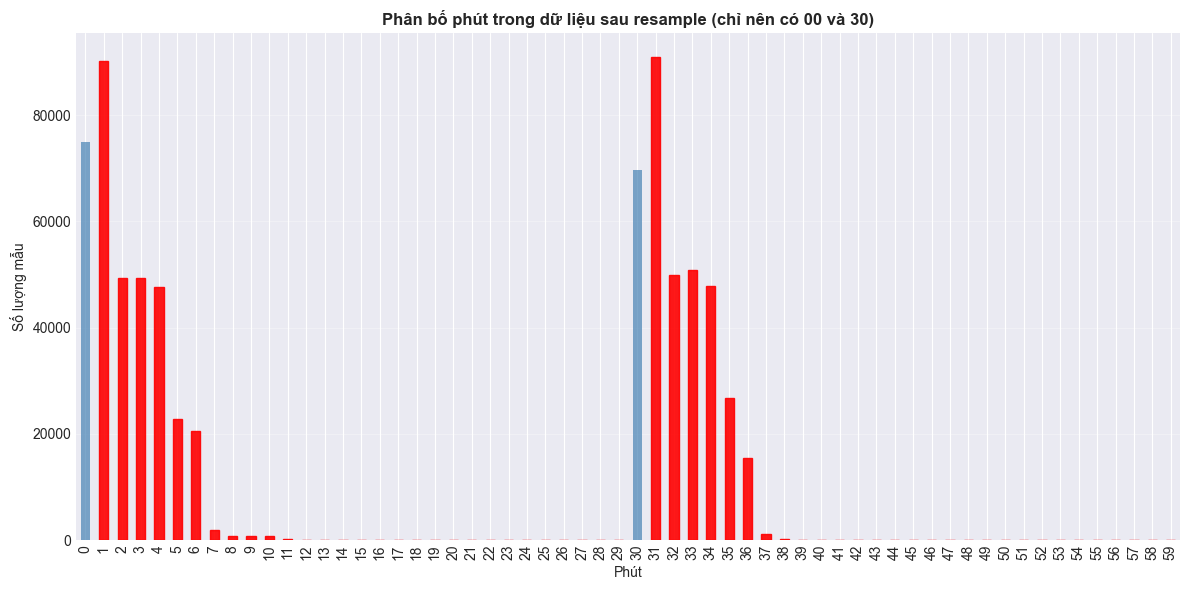

In [7]:
## KIỂM TRA MẪU CÓ PHÚT TRONG KHOẢNG 15-29.9 VÀ 45-59.9

print("=" * 80)
print("KIỂM TRA MẪU CÓ PHÚT NGOÀI MỐC 00 VÀ 30")
print("=" * 80)

# Lấy phút từ timestamp
df_all['minute'] = df_all['TIME'].dt.minute

# Tìm các mẫu có phút trong khoảng 15-29 hoặc 45-59
invalid_minutes = df_all[
    ((df_all['minute'] >= 15) & (df_all['minute'] < 30)) |
    ((df_all['minute'] >= 45) & (df_all['minute'] < 60))
]

print(f"\nTổng số mẫu trong df_all: {len(df_all):,}")
print(f"Số mẫu có phút trong [15-29.9] hoặc [45-59.9]: {len(invalid_minutes):,}")

if len(invalid_minutes) > 0:
    print(f"\n⚠️ CẢNH BÁO: Tìm thấy {len(invalid_minutes):,} mẫu có phút không đúng mốc 00 hoặc 30!")
    
    # Thống kê theo phút
    print("\nPhân bố theo phút:")
    minute_counts = invalid_minutes['minute'].value_counts().sort_index()
    print(minute_counts)
    
    # Thống kê theo trạm
    print("\nPhân bố theo trạm:")
    station_counts = invalid_minutes.groupby('MaDiemDo').size()
    for station_id, count in station_counts.items():
        station_name = invalid_minutes[invalid_minutes['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} mẫu")
    
    # Hiển thị 10 mẫu đầu tiên
    print("\n10 mẫu đầu tiên có phút không hợp lệ:")
    print(invalid_minutes[['TIME', 'MaDiemDo', 'TenDiemDo', 'P_kW', 'minute']].head(10))
    
else:
    print("\n✅ HOÀN HẢO: Tất cả mẫu đều có phút = 00 hoặc 30!")
    print("   Resample đã hoạt động chính xác.")

# Kiểm tra phân bố phút hợp lệ
print("\n" + "=" * 80)
print("PHÂN BỐ PHÚT HỢP LỆ (CHỈ NÊN CÓ 00 VÀ 30)")
print("=" * 80)
minute_distribution = df_all['minute'].value_counts().sort_index()
print(minute_distribution)

# Vẽ biểu đồ phân bố phút
fig, ax = plt.subplots(figsize=(12, 6))
minute_distribution.plot(kind='bar', ax=ax, color='steelblue', alpha=0.7)
ax.set_xlabel('Phút')
ax.set_ylabel('Số lượng mẫu')
ax.set_title('Phân bố phút trong dữ liệu sau resample (chỉ nên có 00 và 30)', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Đánh dấu vùng không hợp lệ
for i, (minute, count) in enumerate(minute_distribution.items()):
    if minute not in [0, 30]:
        ax.get_children()[i].set_color('red')
        ax.get_children()[i].set_alpha(0.9)

plt.tight_layout()
plt.show()


# Xóa cột minute tạm thời
df_all = df_all.drop(columns=['minute'])


In [8]:
## KIỂM TRA GIỜ CÓ NHIỀU HƠN 2 MẪU (DATA RAW)

print("=" * 80)
print("KIỂM TRA GIỜ CÓ NHIỀU HƠN 2 MẪU DATA")
print("=" * 80)

# Tạo cột giờ tạm thời (không thay đổi df_all)
df_temp = df_all.copy()
df_temp['hour'] = df_temp['TIME'].dt.floor('h')

# Đếm số mẫu trong mỗi giờ cho từng trạm
hour_counts = df_temp.groupby(['MaDiemDo', 'hour']).size().reset_index(name='count')

# Lọc các giờ có > 2 mẫu
duplicate_hours = hour_counts[hour_counts['count'] > 2]

print(f"\nTổng số giờ kiểm tra: {len(hour_counts):,}")
print(f"Số giờ có > 2 mẫu: {len(duplicate_hours):,}")

if len(duplicate_hours) > 0:
    print(f"\n⚠️ CẢNH BÁO: Tìm thấy {len(duplicate_hours):,} giờ có nhiều hơn 2 mẫu!")
    
    # Thống kê theo trạm
    print("\nPhân bố theo trạm:")
    station_dup_counts = duplicate_hours.groupby('MaDiemDo').size()
    for station_id, count in station_dup_counts.items():
        station_name = df_temp[df_temp['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} giờ bị trùng")
    
    # Thống kê số mẫu trùng
    print("\nPhân bố số mẫu trùng:")
    count_distribution = duplicate_hours['count'].value_counts().sort_index()
    for num_samples, freq in count_distribution.items():
        print(f"  {num_samples} mẫu/giờ: {freq:,} giờ")
    
    # Xem chi tiết 5 ví dụ đầu tiên
    print("\n" + "=" * 80)
    print("CHI TIẾT 5000 VÍ DỤ ĐẦU TIÊN")
    print("=" * 80)
    
    for i in range(min(5000, len(duplicate_hours))):
        example = duplicate_hours.iloc[i]
        station_name = df_temp[df_temp['MaDiemDo'] == example['MaDiemDo']]['TenDiemDo'].iloc[0]
        
        print(f"\n{i+1}. Giờ: {example['hour']} - {station_name} - {example['count']} mẫu")
        
        example_data = df_temp[(df_temp['MaDiemDo'] == example['MaDiemDo']) & 
                               (df_temp['hour'] == example['hour'])]
        
        # In chi tiết từng mẫu
        for idx, row in example_data.iterrows():
            time_str = row['TIME'].strftime('%Y-%m-%d %H:%M:%S')
            minute = row['TIME'].minute
            second = row['TIME'].second
            print(f"   - {time_str} (phút {minute:02d}, giây {second:02d}) → P_kW = {row['P_kW']:.2f}")
    
else:
    print("\n✅ HOÀN HẢO: Tất cả các giờ đều có tối đa 2 mẫu (00 và 30 phút)!")




KIỂM TRA GIỜ CÓ NHIỀU HƠN 2 MẪU DATA

Tổng số giờ kiểm tra: 359,591
Số giờ có > 2 mẫu: 189

⚠️ CẢNH BÁO: Tìm thấy 189 giờ có nhiều hơn 2 mẫu!

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 13 giờ bị trùng
  474 Tân Hưng (Mã: 4295): 24 giờ bị trùng
  476 Tân Hưng (Mã: 4447): 37 giờ bị trùng
  478 Tân Hưng (Mã: 4587): 38 giờ bị trùng
  TD2 Tân Hưng (Mã: 4999): 10 giờ bị trùng
  480 Tân Hưng (Mã: 8667): 32 giờ bị trùng
  T402 Tân Hưng (Mã: 9402): 35 giờ bị trùng

Phân bố số mẫu trùng:
  3 mẫu/giờ: 184 giờ
  4 mẫu/giờ: 5 giờ

CHI TIẾT 5000 VÍ DỤ ĐẦU TIÊN

1. Giờ: 2020-11-04 06:00:00 - 472 Tân Hưng - 3 mẫu
   - 2020-11-04 06:00:04 (phút 00, giây 04) → P_kW = 4.49
   - 2020-11-04 06:30:05 (phút 30, giây 05) → P_kW = 4.61
   - 2020-11-04 06:59:34 (phút 59, giây 34) → P_kW = 4.58

2. Giờ: 2020-11-04 09:00:00 - 472 Tân Hưng - 3 mẫu
   - 2020-11-04 09:00:04 (phút 00, giây 04) → P_kW = 3.47
   - 2020-11-04 09:30:03 (phút 30, giây 03) → P_kW = 3.62
   - 2020-11-04 09:59:33 (phút 59, giây 33) → P_k

In [9]:
## XỬ LÝ GIỜ CÓ > 2 MẪU: CHỈ GIỮ 2 MẪU GẦN 00 VÀ 30 NHẤT

print("=" * 80)
print("XỬ LÝ GIỜ CÓ > 2 MẪU: CHỈ GIỮ 2 MẪU GẦN MỐC 00 VÀ 30 NHẤT")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Tính khoảng cách đến mốc 00 và 30
def distance_to_nearest_mark(minute, second):
    """Tính khoảng cách (phút) đến mốc 00 hoặc 30 gần nhất"""
    # Khoảng cách đến 00:00
    dist_to_00 = minute + second / 60.0
    
    # Khoảng cách đến 30:00
    if minute < 30:
        dist_to_30 = abs(30 - minute - second / 60.0)
    else:
        dist_to_30 = minute - 30 + second / 60.0
    
    # Trả về mốc gần nhất và khoảng cách
    if dist_to_00 < dist_to_30:
        return 0, dist_to_00  # Gần mốc 00
    else:
        return 30, dist_to_30  # Gần mốc 30

df_all['nearest_mark'], df_all['distance'] = zip(*df_all.apply(
    lambda row: distance_to_nearest_mark(row['minute'], row['second']), axis=1
))

# Tìm các giờ có > 2 mẫu
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
duplicate_hours = hour_counts[hour_counts > 2]

print(f"Số giờ có > 2 mẫu: {len(duplicate_hours)}")

# Xử lý từng giờ bị trùng
rows_to_keep = []

for (station_id, hour_val), count in duplicate_hours.items():
    hour_data = df_all[(df_all['MaDiemDo'] == station_id) & (df_all['hour'] == hour_val)]
    
    # Lấy mẫu gần mốc 00 nhất
    samples_near_00 = hour_data[hour_data['nearest_mark'] == 0]
    if len(samples_near_00) > 0:
        best_00 = samples_near_00.nsmallest(1, 'distance').index[0]
        rows_to_keep.append(best_00)
    
    # Lấy mẫu gần mốc 30 nhất
    samples_near_30 = hour_data[hour_data['nearest_mark'] == 30]
    if len(samples_near_30) > 0:
        best_30 = samples_near_30.nsmallest(1, 'distance').index[0]
        rows_to_keep.append(best_30)

# Tạo mask: giữ tất cả giờ không bị trùng + giờ trùng đã chọn
normal_hours_mask = ~df_all.set_index(['MaDiemDo', 'hour']).index.isin(duplicate_hours.index)
normal_hours_indices = df_all[normal_hours_mask].index

all_keep_indices = list(normal_hours_indices) + rows_to_keep

# Lọc DataFrame
df_cleaned = df_all.loc[all_keep_indices].copy()
df_cleaned = df_cleaned.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

# Xóa các cột tạm
df_cleaned = df_cleaned.drop(columns=['hour', 'minute', 'second', 'nearest_mark', 'distance'])
df_all = df_all.drop(columns=['hour', 'minute', 'second', 'nearest_mark', 'distance'])

print(f"\nTrước xử lý: {len(df_all):,} records")
print(f"Sau xử lý:   {len(df_cleaned):,} records")
print(f"Đã xóa:      {len(df_all) - len(df_cleaned):,} records")

# Cập nhật df_all
df_all = df_cleaned.copy()

print("\n✅ Đã xử lý xong! Mỗi giờ chỉ còn tối đa 2 mẫu (gần 00 và 30 nhất)")




XỬ LÝ GIỜ CÓ > 2 MẪU: CHỈ GIỮ 2 MẪU GẦN MỐC 00 VÀ 30 NHẤT
Số giờ có > 2 mẫu: 189

Trước xử lý: 712,736 records
Sau xử lý:   712,540 records
Đã xóa:      196 records

✅ Đã xử lý xong! Mỗi giờ chỉ còn tối đa 2 mẫu (gần 00 và 30 nhất)


In [10]:
# SAU BƯỚC 4 (XỬ LÝ GIỜ CÓ > 2 MẪU)
# Thêm dòng này để xác nhận
print(f"\n✅ df_all hiện tại đã được xử lý: {len(df_all):,} records")
print(f"   Đây là data SẠCH sau khi xử lý giờ có > 2 mẫu")

# BƯỚC 5 sẽ dùng df_all đã xử lý này



✅ df_all hiện tại đã được xử lý: 712,540 records
   Đây là data SẠCH sau khi xử lý giờ có > 2 mẫu


In [11]:
## KIỂM TRA GIỜ CÓ 2 MẪU NHƯNG CÁCH NHAU < 30 PHÚT

print("=" * 80)
print("KIỂM TRA GIỜ CÓ 2 MẪU NHƯNG CÁCH NHAU < 1800 GIÂY (30 PHÚT)")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')

# Tìm các giờ có đúng 2 mẫu
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_2_samples = hour_counts[hour_counts == 2]

print(f"Tổng số giờ có đúng 2 mẫu: {len(hours_with_2_samples):,}")

# Lọc chỉ lấy các giờ có 2 mẫu
df_2samples = df_all[df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_2_samples.index)].copy()

# Tính khoảng cách bằng vectorization (ĐƠN VỊ: GIÂY)
df_2samples = df_2samples.sort_values(['MaDiemDo', 'hour', 'TIME'])
df_2samples['row_num'] = df_2samples.groupby(['MaDiemDo', 'hour']).cumcount() + 1
df_2samples['time_diff_seconds'] = df_2samples.groupby(['MaDiemDo', 'hour'])['TIME'].diff().dt.total_seconds()

# Tách mẫu 1 và mẫu 2
df_sample1 = df_2samples[df_2samples['row_num'] == 1][['MaDiemDo', 'TenDiemDo', 'hour', 'TIME', 'P_kW']].rename(columns={'TIME': 'time1', 'P_kW': 'P_kW_1'})
df_sample2 = df_2samples[df_2samples['row_num'] == 2][['MaDiemDo', 'hour', 'TIME', 'P_kW', 'time_diff_seconds']].rename(columns={'TIME': 'time2', 'P_kW': 'P_kW_2'})

# Merge 2 mẫu
df_merged = df_sample1.merge(df_sample2, on=['MaDiemDo', 'hour'])

# Lọc < 1800s
df_invalid_full = df_merged[df_merged['time_diff_seconds'] < 1800].copy()

print(f"Số giờ có 2 mẫu cách nhau < 1800 giây: {len(df_invalid_full)}")

if len(df_invalid_full) > 0:
    print(f"\n⚠️ CẢNH BÁO: Tìm thấy {len(df_invalid_full)} giờ có 2 mẫu cách nhau < 1800 giây!")
    
    # Thống kê theo trạm
    print("\nPhân bố theo trạm:")
    station_counts = df_invalid_full.groupby('MaDiemDo').size()
    for station_id, count in station_counts.items():
        station_name = df_invalid_full[df_invalid_full['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} giờ")
    
    # Thống kê khoảng cách
    print("\nPhân bố khoảng cách:")
    print(f"  Min: {df_invalid_full['time_diff_seconds'].min():.0f} giây ({df_invalid_full['time_diff_seconds'].min()/60:.2f} phút)")
    print(f"  Max: {df_invalid_full['time_diff_seconds'].max():.0f} giây ({df_invalid_full['time_diff_seconds'].max()/60:.2f} phút)")
    print(f"  Mean: {df_invalid_full['time_diff_seconds'].mean():.0f} giây ({df_invalid_full['time_diff_seconds'].mean()/60:.2f} phút)")
    print(f"  Median: {df_invalid_full['time_diff_seconds'].median():.0f} giây ({df_invalid_full['time_diff_seconds'].median()/60:.2f} phút)")
    
    # Thống kê phân bố theo từng phút (KHÔNG ĐẾM LẠI) + 2 VÍ DỤ
    print("\n" + "=" * 80)
    print("PHÂN BỐ SỐ GIỜ THEO KHOẢNG CÁCH (PHÚT) - KHÔNG ĐẾM LẠI:")
    print("=" * 80)
    
    counted_indices = set()
    for minute in range(1, 31):
        # Lọc các giờ có khoảng cách < minute * 60 giây
        mask = df_invalid_full['time_diff_seconds'] < minute * 60
        current_indices = set(df_invalid_full[mask].index)
        
        # Chỉ đếm các giờ MỚI (chưa xuất hiện ở điều kiện trước)
        new_indices = current_indices - counted_indices
        new_count = len(new_indices)
        
        print(f"\n< {minute:2d} phút ({minute * 60:4d}s): {new_count:,} giờ MỚI")
        
        # In 2 ví dụ của phân bố này
        if new_count > 0:
            new_data = df_invalid_full.loc[list(new_indices)].sort_values('time_diff_seconds').head(2)
            for idx, row in enumerate(new_data.itertuples(), 1):
                print(f"  VD{idx}: {row.TenDiemDo} | {row.hour.strftime('%Y-%m-%d %H:00')} | "
                      f"{row.time1.strftime('%H:%M:%S')} → {row.time2.strftime('%H:%M:%S')} | "
                      f"Δ={row.time_diff_seconds:.0f}s ({row.time_diff_seconds/60:.2f}p) | "
                      f"P1={row.P_kW_1:.2f} P2={row.P_kW_2:.2f}")
        
        # Cập nhật danh sách đã đếm
        counted_indices.update(new_indices)
    
else:
    print("\n✅ HOÀN HẢO: Tất cả giờ có 2 mẫu đều cách nhau >= 1800 giây (30 phút)!")

# Xóa cột hour tạm thời
df_all = df_all.drop(columns=['hour'])


KIỂM TRA GIỜ CÓ 2 MẪU NHƯNG CÁCH NHAU < 1800 GIÂY (30 PHÚT)
Tổng số giờ có đúng 2 mẫu: 352,949
Số giờ có 2 mẫu cách nhau < 1800 giây: 145315

⚠️ CẢNH BÁO: Tìm thấy 145315 giờ có 2 mẫu cách nhau < 1800 giây!

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 16,569 giờ
  474 Tân Hưng (Mã: 4295): 19,736 giờ
  476 Tân Hưng (Mã: 4447): 21,540 giờ
  478 Tân Hưng (Mã: 4587): 21,789 giờ
  TD2 Tân Hưng (Mã: 4999): 16,727 giờ
  480 Tân Hưng (Mã: 8667): 24,873 giờ
  T402 Tân Hưng (Mã: 9402): 24,081 giờ

Phân bố khoảng cách:
  Min: 1 giây (0.02 phút)
  Max: 1799 giây (29.98 phút)
  Mean: 1778 giây (29.63 phút)
  Median: 1798 giây (29.97 phút)

PHÂN BỐ SỐ GIỜ THEO KHOẢNG CÁCH (PHÚT) - KHÔNG ĐẾM LẠI:

<  1 phút (  60s): 12 giờ MỚI
  VD1: T402 Tân Hưng | 2023-01-30 15:00 | 15:29:59 → 15:30:00 | Δ=1s (0.02p) | P1=-0.01 P2=0.00
  VD2: 478 Tân Hưng | 2021-11-29 18:00 | 18:29:56 → 18:30:00 | Δ=4s (0.07p) | P1=11.92 P2=11.20

<  2 phút ( 120s): 14 giờ MỚI
  VD1: 474 Tân Hưng | 2021-04-11 07:00 | 07:29:00 → 0

In [12]:
## XỬ LÝ GIỜ CÓ 2 MẪU CÁCH NHAU < 15 PHÚT: CHỈ GIỮ 1 MẪU GẦN MỐC NHẤT

print("=" * 80)
print("XỬ LÝ GIỜ CÓ 2 MẪU CÁCH NHAU < 900 GIÂY (15 PHÚT)")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')

# Tìm các giờ có đúng 2 mẫu
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_2_samples = hour_counts[hour_counts == 2]

print(f"Tổng số giờ có đúng 2 mẫu: {len(hours_with_2_samples):,}")

# Lọc chỉ lấy các giờ có 2 mẫu
df_2samples = df_all[df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_2_samples.index)].copy()

# Tính khoảng cách bằng vectorization (ĐƠN VỊ: GIÂY)
df_2samples = df_2samples.sort_values(['MaDiemDo', 'hour', 'TIME'])
df_2samples['row_num'] = df_2samples.groupby(['MaDiemDo', 'hour']).cumcount() + 1
df_2samples['time_diff_seconds'] = df_2samples.groupby(['MaDiemDo', 'hour'])['TIME'].diff().dt.total_seconds()

# Tách mẫu 1 và mẫu 2
df_sample1 = df_2samples[df_2samples['row_num'] == 1][['MaDiemDo', 'TenDiemDo', 'hour', 'TIME', 'P_kW']].rename(columns={'TIME': 'time1', 'P_kW': 'P_kW_1'})
df_sample2 = df_2samples[df_2samples['row_num'] == 2][['MaDiemDo', 'hour', 'TIME', 'P_kW', 'time_diff_seconds']].rename(columns={'TIME': 'time2', 'P_kW': 'P_kW_2'})

# Merge 2 mẫu
df_merged = df_sample1.merge(df_sample2, on=['MaDiemDo', 'hour'])

# Lọc < 900s (15 phút)
df_invalid_15min = df_merged[df_merged['time_diff_seconds'] < 900].copy()

print(f"Số giờ có 2 mẫu cách nhau < 900 giây: {len(df_invalid_15min)}")

if len(df_invalid_15min) > 0:
    print(f"\n⚠️ Tìm thấy {len(df_invalid_15min)} giờ có 2 mẫu cách nhau < 15 phút!")
    print("   → Sẽ chỉ giữ 1 mẫu gần mốc 00 hoặc 30 nhất")
    
    # Thống kê trước xử lý
    print("\nPhân bố theo trạm:")
    station_counts = df_invalid_15min.groupby('MaDiemDo').size()
    for station_id, count in station_counts.items():
        station_name = df_invalid_15min[df_invalid_15min['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} giờ")
    
    # Tính khoảng cách đến mốc 00 và 30 cho cả 2 mẫu
    def calc_distance_to_marks(time):
        """Tính khoảng cách (giây) đến mốc 00:00 hoặc 30:00 gần nhất"""
        minute = time.minute
        second = time.second
        
        # Khoảng cách đến 00:00 (tính bằng giây)
        dist_to_00 = minute * 60 + second
        
        # Khoảng cách đến 30:00
        if minute < 30:
            dist_to_30 = abs(30 * 60 - (minute * 60 + second))
        else:
            dist_to_30 = (minute - 30) * 60 + second
        
        # Trả về khoảng cách nhỏ nhất
        return min(dist_to_00, dist_to_30)
    
    df_invalid_15min['dist1'] = df_invalid_15min['time1'].apply(calc_distance_to_marks)
    df_invalid_15min['dist2'] = df_invalid_15min['time2'].apply(calc_distance_to_marks)
    
    # Xác định mẫu nào gần mốc hơn
    rows_to_remove = []
    
    for idx, row in df_invalid_15min.iterrows():
        # Nếu mẫu 1 gần mốc hơn → xóa mẫu 2
        if row['dist1'] <= row['dist2']:
            # Tìm index của mẫu 2 trong df_all
            mask = (df_all['MaDiemDo'] == row['MaDiemDo']) & \
                   (df_all['hour'] == row['hour']) & \
                   (df_all['TIME'] == row['time2'])
            rows_to_remove.extend(df_all[mask].index.tolist())
        else:
            # Tìm index của mẫu 1 trong df_all
            mask = (df_all['MaDiemDo'] == row['MaDiemDo']) & \
                   (df_all['hour'] == row['hour']) & \
                   (df_all['TIME'] == row['time1'])
            rows_to_remove.extend(df_all[mask].index.tolist())
    
    # Hiển thị 5 ví dụ trước khi xóa
    print("\n" + "=" * 80)
    print("5 VÍ DỤ TRƯỚC KHI XỬ LÝ:")
    print("=" * 80)
    
    for idx, row in enumerate(df_invalid_15min.head(5).itertuples(), 1):
        keep_sample = 1 if row.dist1 <= row.dist2 else 2
        print(f"\n{idx}. {row.TenDiemDo} - Giờ: {row.hour.strftime('%Y-%m-%d %H:00')}")
        print(f"   Mẫu 1: {row.time1.strftime('%H:%M:%S')} | Cách mốc: {row.dist1:.0f}s | P_kW = {row.P_kW_1:.2f}")
        print(f"   Mẫu 2: {row.time2.strftime('%H:%M:%S')} | Cách mốc: {row.dist2:.0f}s | P_kW = {row.P_kW_2:.2f}")
        print(f"   Khoảng cách: {row.time_diff_seconds:.0f}s ({row.time_diff_seconds/60:.2f}p)")
        print(f"   → GIỮ MẪU {keep_sample} (gần mốc hơn)")
    
    # Xóa các mẫu xa mốc
    print(f"\n{'='*80}")
    print(f"Trước xử lý: {len(df_all):,} records")
    df_all = df_all.drop(index=rows_to_remove).reset_index(drop=True)
    print(f"Sau xử lý:   {len(df_all):,} records")
    print(f"Đã xóa:      {len(rows_to_remove):,} records")
    print(f"\n✅ Đã xử lý xong! Các giờ có 2 mẫu < 15p đã chỉ còn 1 mẫu gần mốc nhất")
    
else:
    print("\n✅ HOÀN HẢO: Không có giờ nào có 2 mẫu cách nhau < 15 phút!")

# Xóa cột hour tạm thời
df_all = df_all.drop(columns=['hour'])


XỬ LÝ GIỜ CÓ 2 MẪU CÁCH NHAU < 900 GIÂY (15 PHÚT)
Tổng số giờ có đúng 2 mẫu: 352,949
Số giờ có 2 mẫu cách nhau < 900 giây: 327

⚠️ Tìm thấy 327 giờ có 2 mẫu cách nhau < 15 phút!
   → Sẽ chỉ giữ 1 mẫu gần mốc 00 hoặc 30 nhất

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 32 giờ
  474 Tân Hưng (Mã: 4295): 45 giờ
  476 Tân Hưng (Mã: 4447): 43 giờ
  478 Tân Hưng (Mã: 4587): 58 giờ
  TD2 Tân Hưng (Mã: 4999): 32 giờ
  480 Tân Hưng (Mã: 8667): 61 giờ
  T402 Tân Hưng (Mã: 9402): 56 giờ

5 VÍ DỤ TRƯỚC KHI XỬ LÝ:

1. 472 Tân Hưng - Giờ: 2021-01-24 15:00
   Mẫu 1: 15:00:05 | Cách mốc: 5s | P_kW = 6.21
   Mẫu 2: 15:11:08 | Cách mốc: 668s | P_kW = 6.26
   Khoảng cách: 663s (11.05p)
   → GIỮ MẪU 1 (gần mốc hơn)

2. 472 Tân Hưng - Giờ: 2021-01-24 21:00
   Mẫu 1: 21:00:04 | Cách mốc: 4s | P_kW = 9.98
   Mẫu 2: 21:11:14 | Cách mốc: 674s | P_kW = 9.84
   Khoảng cách: 670s (11.17p)
   → GIỮ MẪU 1 (gần mốc hơn)

3. 472 Tân Hưng - Giờ: 2021-04-11 07:00
   Mẫu 1: 07:23:01 | Cách mốc: 419s | P_kW = 0.00
   M

In [13]:
## KIỂM TRA GIỜ CÓ 2 MẪU CÙNG HƯỚNG VỀ 1 MỐC

print("=" * 80)
print("KIỂM TRA GIỜ CÓ 2 MẪU CÙNG HƯỚNG VỀ 1 MỐC")
print("=" * 80)

# Tạo cột date và hour
df_all['date'] = df_all['TIME'].dt.date
df_all['hour'] = df_all['TIME'].dt.hour
df_all['minute'] = df_all['TIME'].dt.minute

# Tính khoảng cách đến mốc 00 và 30
def distance_to_target(minute):
    """Tính khoảng cách đến mốc 00 hoặc 30 gần nhất"""
    dist_to_00 = abs(minute - 0)
    dist_to_30 = abs(minute - 30)
    return min(dist_to_00, dist_to_30)

def nearest_target(minute):
    """Xác định mốc gần nhất (00 hoặc 30)"""
    dist_to_00 = abs(minute - 0)
    dist_to_30 = abs(minute - 30)
    return 0 if dist_to_00 <= dist_to_30 else 30

df_all['distance_to_target'] = df_all['minute'].apply(distance_to_target)
df_all['nearest_target'] = df_all['minute'].apply(nearest_target)

# Nhóm theo MaDiemDo, date, hour
grouped = df_all.groupby(['MaDiemDo', 'date', 'hour'])

# Lọc các giờ có đúng 2 mẫu
hours_with_2_samples = grouped.filter(lambda x: len(x) == 2)

if len(hours_with_2_samples) > 0:
    # Kiểm tra các giờ có 2 mẫu cùng hướng về 1 mốc
    same_target_groups = []
    
    for (station_id, date, hour), group in hours_with_2_samples.groupby(['MaDiemDo', 'date', 'hour']):
        if len(group) == 2:
            targets = group['nearest_target'].values
            # Kiểm tra cả 2 mẫu cùng hướng về 1 mốc
            if targets[0] == targets[1]:
                same_target_groups.append({
                    'MaDiemDo': station_id,
                    'TenDiemDo': group['TenDiemDo'].iloc[0],
                    'date': date,
                    'hour': hour,
                    'target': targets[0],
                    'minute_1': group['minute'].iloc[0],
                    'minute_2': group['minute'].iloc[1],
                    'time_1': group['TIME'].iloc[0],
                    'time_2': group['TIME'].iloc[1],
                    'distance_1': group['distance_to_target'].iloc[0],
                    'distance_2': group['distance_to_target'].iloc[1]
                })
    
    if len(same_target_groups) > 0:
        df_same_target = pd.DataFrame(same_target_groups)
        
        print(f"\n⚠️ Tìm thấy {len(df_same_target):,} giờ có 2 mẫu cùng hướng về 1 mốc!")
        
        # Thống kê tổng quan
        print(f"\nPhân bố theo mốc:")
        print(f"  Cả 2 gần mốc 00: {(df_same_target['target'] == 0).sum():,} giờ")
        print(f"  Cả 2 gần mốc 30: {(df_same_target['target'] == 30).sum():,} giờ")
        
        # Thống kê theo trạm
        print(f"\n{'='*80}")
        print(f"THỐNG KÊ THEO TRẠM:")
        print(f"{'='*80}")
        
        print(f"\n{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'Gần 00':<10} {'Gần 30':<10}")
        print("-" * 70)
        
        for idx, station_id in enumerate(sorted(df_same_target['MaDiemDo'].unique()), 1):
            station_data = df_same_target[df_same_target['MaDiemDo'] == station_id]
            station_name = station_data['TenDiemDo'].iloc[0]
            
            total = len(station_data)
            near_00 = (station_data['target'] == 0).sum()
            near_30 = (station_data['target'] == 30).sum()
            
            print(f"{idx:<5} {station_name:<20} {station_id:<8} {total:<10,} {near_00:<10,} {near_30:<10,}")
        
        # Hiển thị 20 ví dụ
        print(f"\n{'='*80}")
        print(f"20 VÍ DỤ ĐẦU TIÊN:")
        print(f"{'='*80}")
        
        for idx, row in enumerate(df_same_target.head(20).itertuples(), 1):
            print(f"\n{idx}. {row.TenDiemDo} - {row.date} {row.hour:02d}:xx")
            print(f"   Cả 2 mẫu đều gần mốc: {row.target:02d} phút")
            print(f"   Mẫu 1: {row.time_1} (phút {row.minute_1}, cách mốc {row.distance_1} phút)")
            print(f"   Mẫu 2: {row.time_2} (phút {row.minute_2}, cách mốc {row.distance_2} phút)")
        
        # Thống kê khoảng cách
        print(f"\n{'='*80}")
        print(f"THỐNG KÊ KHOẢNG CÁCH ĐÉN MỐC:")
        print(f"{'='*80}")
        
        all_distances = pd.concat([
            df_same_target[['distance_1']].rename(columns={'distance_1': 'distance'}),
            df_same_target[['distance_2']].rename(columns={'distance_2': 'distance'})
        ])
        
        print(f"\nKhoảng cách đến mốc (phút):")
        print(f"  Min: {all_distances['distance'].min():.0f}")
        print(f"  Max: {all_distances['distance'].max():.0f}")
        print(f"  Mean: {all_distances['distance'].mean():.2f}")
        print(f"  Median: {all_distances['distance'].median():.0f}")
        
        # Phân bố khoảng cách
        print(f"\nPhân bố khoảng cách:")
        for dist in sorted(all_distances['distance'].unique()):
            count = (all_distances['distance'] == dist).sum()
            print(f"  {dist:.0f} phút: {count:,} mẫu")
        
    else:
        print(f"\n✅ HOÀN HẢO: Không có giờ nào có 2 mẫu cùng hướng về 1 mốc!")
        print(f"   Tất cả các giờ có 2 mẫu đều có 1 mẫu gần 00 và 1 mẫu gần 30")
else:
    print(f"\n⚠️ Không tìm thấy giờ nào có đúng 2 mẫu!")

# Xóa các cột tạm
df_all = df_all.drop(columns=['date', 'hour', 'minute', 'distance_to_target', 'nearest_target'])

print("\n" + "=" * 80)
print("✅ Hoàn thành kiểm tra!")
print("=" * 80)


KIỂM TRA GIỜ CÓ 2 MẪU CÙNG HƯỚNG VỀ 1 MỐC

⚠️ Tìm thấy 84 giờ có 2 mẫu cùng hướng về 1 mốc!

Phân bố theo mốc:
  Cả 2 gần mốc 00: 0 giờ
  Cả 2 gần mốc 30: 84 giờ

THỐNG KÊ THEO TRẠM:

STT   Tên trạm             Mã       Tổng       Gần 00     Gần 30    
----------------------------------------------------------------------
1     472 Tân Hưng         4127     9          0          9         
2     474 Tân Hưng         4295     8          0          8         
3     476 Tân Hưng         4447     11         0          11        
4     478 Tân Hưng         4587     10         0          10        
5     TD2 Tân Hưng         4999     14         0          14        
6     480 Tân Hưng         8667     14         0          14        
7     T402 Tân Hưng        9402     18         0          18        

20 VÍ DỤ ĐẦU TIÊN:

1. 472 Tân Hưng - 2020-11-04 20:xx
   Cả 2 mẫu đều gần mốc: 30 phút
   Mẫu 1: 2020-11-04 20:30:03 (phút 30, cách mốc 0 phút)
   Mẫu 2: 2020-11-04 20:59:33 (phút 59, cách mố

In [14]:
## XỬ LÝ GIỜ CÓ 2 MẪU: GÁN VỀ MỐC GẦN NHẤT VÀ CHỈ GIỮ 1 MẪU/MỐC (VECTORIZED)

print("=" * 80)
print("XỬ LÝ GIỜ CÓ 2 MẪU: GÁN VỀ MỐC GẦN NHẤT (VECTORIZED)")
print("=" * 80)

# Tạo cột giờ và phút (vectorized)
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Tính khoảng cách đến mốc 00 và 30 (vectorized)
total_seconds = df_all['minute'] * 60 + df_all['second']
df_all['dist_to_00'] = total_seconds
df_all['dist_to_30'] = (30 * 60 - total_seconds).abs()

# Xác định mốc gần nhất (vectorized)
df_all['nearest_mark'] = (df_all['dist_to_00'] > df_all['dist_to_30']).astype(int) * 30

# Đếm số mẫu trong mỗi giờ
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_2_samples = hour_counts[hour_counts == 2]

print(f"Tổng số giờ: {len(hour_counts):,}")
print(f"Số giờ có 2 mẫu: {len(hours_with_2_samples):,}")

if len(hours_with_2_samples) > 0:
    print(f"\n⚠️ Tìm thấy {len(hours_with_2_samples):,} giờ có 2 mẫu!")
    
    # Lọc các giờ có 2 mẫu
    mask_2samples = df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_2_samples.index)
    df_2samples = df_all[mask_2samples].copy()
    
    # Phân tích trước khi xử lý
    print(f"\n{'='*80}")
    print(f"PHÂN TÍCH TRƯỚC KHI XỬ LÝ:")
    print(f"{'='*80}")
    
    mark_00_count = (df_2samples['nearest_mark'] == 0).sum()
    mark_30_count = (df_2samples['nearest_mark'] == 30).sum()
    
    print(f"\nPhân bố mẫu theo mốc gần nhất:")
    print(f"  Gần mốc 00: {mark_00_count:,} mẫu")
    print(f"  Gần mốc 30: {mark_30_count:,} mẫu")
    
    # XỬ LÝ: Với mỗi giờ, chỉ giữ 1 mẫu gần nhất cho mỗi mốc (vectorized)
    print(f"\n{'='*80}")
    print(f"XỬ LÝ: CHỈ GIỮ 1 MẪU GẦN NHẤT CHO MỖI MỐC")
    print(f"{'='*80}")
    
    # Tạo cột khoảng cách tương ứng với mốc gần nhất
    df_2samples['dist_to_nearest'] = df_2samples.apply(
        lambda row: row['dist_to_00'] if row['nearest_mark'] == 0 else row['dist_to_30'], axis=1
    )
    
    # Với mỗi nhóm (MaDiemDo, hour, nearest_mark), chỉ giữ mẫu có khoảng cách nhỏ nhất
    idx_to_keep = df_2samples.groupby(['MaDiemDo', 'hour', 'nearest_mark'])['dist_to_nearest'].idxmin()
    
    # Tạo mask để xóa các mẫu không giữ
    mask_to_remove = mask_2samples & ~df_all.index.isin(idx_to_keep)
    
    print(f"\nSố mẫu trước xử lý: {len(df_all):,}")
    print(f"Số mẫu sẽ xóa: {mask_to_remove.sum():,}")
    print(f"Số mẫu sẽ giữ: {len(idx_to_keep):,}")
    
    # Thống kê mẫu bị xóa theo trạm
    df_removed = df_all[mask_to_remove]
    if len(df_removed) > 0:
        print(f"\nPhân bố mẫu bị xóa theo trạm:")
        removed_by_station = df_removed.groupby('MaDiemDo').size()
        for station_id, count in removed_by_station.items():
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {count:,} mẫu")
        
        # Hiển thị 10 ví dụ mẫu bị xóa
        print(f"\n10 ví dụ mẫu bị xóa:")
        for idx, row in enumerate(df_removed.head(10).itertuples(), 1):
            mark_str = f"{row.nearest_mark:02d}:00"
            dist = row.dist_to_00 if row.nearest_mark == 0 else row.dist_to_30
            print(f"  {idx}. {row.TenDiemDo} - {row.TIME} → Mốc {mark_str} (cách {dist:.0f}s)")
    
    # Xóa các mẫu không giữ
    df_all = df_all[~mask_to_remove].copy()
    df_all = df_all.reset_index(drop=True)
    
    print(f"\n✅ Đã xóa {mask_to_remove.sum():,} mẫu")
    print(f"Số mẫu sau xử lý: {len(df_all):,}")

else:
    print(f"\n✅ Không có giờ nào có 2 mẫu!")

# Xóa các cột tạm
df_all = df_all.drop(columns=['hour', 'minute', 'second', 'dist_to_00', 'dist_to_30', 'nearest_mark'])

print("\n" + "=" * 80)
print("✅ Hoàn thành xử lý!")
print("=" * 80)


XỬ LÝ GIỜ CÓ 2 MẪU: GÁN VỀ MỐC GẦN NHẤT (VECTORIZED)
Tổng số giờ: 359,591
Số giờ có 2 mẫu: 352,622

⚠️ Tìm thấy 352,622 giờ có 2 mẫu!

PHÂN TÍCH TRƯỚC KHI XỬ LÝ:

Phân bố mẫu theo mốc gần nhất:
  Gần mốc 00: 352,520 mẫu
  Gần mốc 30: 352,724 mẫu

XỬ LÝ: CHỈ GIỮ 1 MẪU GẦN NHẤT CHO MỖI MỐC

Số mẫu trước xử lý: 712,213
Số mẫu sẽ xóa: 102
Số mẫu sẽ giữ: 705,142

Phân bố mẫu bị xóa theo trạm:
  472 Tân Hưng (Mã 4127): 10 mẫu
  474 Tân Hưng (Mã 4295): 9 mẫu
  476 Tân Hưng (Mã 4447): 14 mẫu
  478 Tân Hưng (Mã 4587): 12 mẫu
  TD2 Tân Hưng (Mã 4999): 16 mẫu
  480 Tân Hưng (Mã 8667): 20 mẫu
  T402 Tân Hưng (Mã 9402): 21 mẫu

10 ví dụ mẫu bị xóa:
  1. 472 Tân Hưng - 2020-11-04 20:59:33 → Mốc 30:00 (cách 1773s)
  2. 472 Tân Hưng - 2021-03-13 17:46:14 → Mốc 30:00 (cách 974s)
  3. 472 Tân Hưng - 2021-11-07 23:16:14 → Mốc 30:00 (cách 826s)
  4. 472 Tân Hưng - 2021-11-30 00:59:52 → Mốc 30:00 (cách 1792s)
  5. 472 Tân Hưng - 2021-12-01 00:45:57 → Mốc 30:00 (cách 957s)
  6. 472 Tân Hưng - 2021-12-01 10:

In [15]:
## XỬ LÝ GIỜ CHỈ CÓ 1 MẪU: LÀM TRÒN NẾU ≤ 15 PHÚT, XÓA NẾU > 15 PHÚT

print("=" * 80)
print("XỬ LÝ GIỜ CHỈ CÓ 1 MẪU: LÀM TRÒN NẾU ≤ 15 PHÚT")
print("=" * 80)

MAX_DISTANCE = 15 * 60  # 15 phút = 900 giây

# Tạo cột giờ (vectorized)
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Đếm số mẫu trong mỗi giờ
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_1_sample = hour_counts[hour_counts == 1]

print(f"Tổng số giờ: {len(hour_counts):,}")
print(f"Số giờ có 1 mẫu: {len(hours_with_1_sample):,}")
print(f"Số giờ có 2 mẫu: {(hour_counts == 2).sum():,}")
print(f"Ngưỡng khoảng cách tối đa: {MAX_DISTANCE}s ({MAX_DISTANCE/60:.0f} phút)")

if len(hours_with_1_sample) > 0:
    print(f"\n⚠️ Tìm thấy {len(hours_with_1_sample):,} giờ chỉ có 1 mẫu!")
    
    # Lọc các giờ có 1 mẫu
    mask_1sample = df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_1_sample.index)
    df_1sample = df_all[mask_1sample].copy()
    
    # Tính khoảng cách đến mốc gần nhất (vectorized)
    total_seconds = df_1sample['minute'] * 60 + df_1sample['second']
    
    # Tính khoảng cách đến cả 2 mốc
    dist_to_00 = total_seconds
    dist_to_30 = (30 * 60 - total_seconds).abs()
    
    # Chọn mốc gần nhất và khoảng cách tương ứng
    df_1sample['nearest_mark'] = (dist_to_00 > dist_to_30).astype(int) * 30
    df_1sample['distance'] = np.where(df_1sample['nearest_mark'] == 0, dist_to_00, dist_to_30)
    
    # Phân loại: giữ (làm tròn) hoặc xóa
    df_1sample['action'] = np.where(
        df_1sample['distance'] <= MAX_DISTANCE,
        'GIỮ (làm tròn)',
        'XÓA (xa mốc quá)'
    )
    
    keep_count = (df_1sample['action'] == 'GIỮ (làm tròn)').sum()
    remove_count = (df_1sample['action'] == 'XÓA (xa mốc quá)').sum()
    
    # Thống kê trước khi xử lý
    print(f"\n{'='*80}")
    print(f"PHÂN LOẠI:")
    print(f"{'='*80}")
    print(f"  Giữ (làm tròn): {keep_count:,} mẫu")
    print(f"  Xóa (xa mốc quá): {remove_count:,} mẫu")
    
    print("\nThống kê khoảng cách:")
    print(f"  Min: {df_1sample['distance'].min():.0f}s ({df_1sample['distance'].min()/60:.2f} phút)")
    print(f"  Max: {df_1sample['distance'].max():.0f}s ({df_1sample['distance'].max()/60:.2f} phút)")
    print(f"  Mean: {df_1sample['distance'].mean():.0f}s ({df_1sample['distance'].mean()/60:.2f} phút)")
    print(f"  Median: {df_1sample['distance'].median():.0f}s ({df_1sample['distance'].median()/60:.2f} phút)")
    
    print("\nPhân bố khoảng cách:")
    print(f"  < 5 phút: {(df_1sample['distance'] < 300).sum():,} giờ")
    print(f"  5-10 phút: {((df_1sample['distance'] >= 300) & (df_1sample['distance'] < 600)).sum():,} giờ")
    print(f"  10-15 phút: {((df_1sample['distance'] >= 600) & (df_1sample['distance'] < 900)).sum():,} giờ")
    print(f"  > 15 phút: {(df_1sample['distance'] >= 900).sum():,} giờ")
    
    # XỬ LÝ MẪU SẼ XÓA
    if remove_count > 0:
        print(f"\n{'='*80}")
        print(f"XỬ LÝ: XÓA MẪU XA MỐC QUÁ {MAX_DISTANCE/60:.0f} PHÚT")
        print(f"{'='*80}")
        
        df_to_remove = df_1sample[df_1sample['action'] == 'XÓA (xa mốc quá)']
        
        # Thống kê theo trạm
        print(f"\nPhân bố mẫu sẽ xóa theo trạm:")
        removed_by_station = df_to_remove.groupby('MaDiemDo').size()
        for station_id, count in removed_by_station.items():
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {count:,} mẫu")
        
        # Hiển thị 10 ví dụ
        print(f"\n10 ví dụ mẫu sẽ xóa:")
        df_to_remove_sorted = df_to_remove.sort_values('distance', ascending=False)
        for idx, row in enumerate(df_to_remove_sorted.head(10).itertuples(), 1):
            mark_str = f"{row.nearest_mark:02d}:00"
            print(f"  {idx}. {row.TenDiemDo} - {row.TIME} → Mốc {mark_str} (cách {row.distance:.0f}s = {row.distance/60:.2f} phút)")
        
        # Xóa các mẫu xa mốc quá
        mask_to_remove = mask_1sample & df_all.index.isin(df_to_remove.index)
        df_all = df_all[~mask_to_remove].copy()
        df_all = df_all.reset_index(drop=True)
        
        print(f"\n✅ Đã xóa {remove_count:,} mẫu xa mốc quá {MAX_DISTANCE/60:.0f} phút")
    
    # XỬ LÝ MẪU SẼ GIỮ (LÀM TRÒN)
    if keep_count > 0:
        print(f"\n{'='*80}")
        print(f"XỬ LÝ: LÀM TRÒN MẪU GẦN MỐC (≤ {MAX_DISTANCE/60:.0f} PHÚT)")
        print(f"{'='*80}")
        
        df_to_keep = df_1sample[df_1sample['action'] == 'GIỮ (làm tròn)'].copy()
        
        # Tính TIME mới (vectorized)
        df_to_keep['TIME_new'] = df_to_keep['hour'] + pd.to_timedelta(df_to_keep['nearest_mark'], unit='m')
        
        # Cập nhật TIME trong df_all
        for idx, time_new in df_to_keep['TIME_new'].items():
            if idx in df_all.index:
                df_all.loc[idx, 'TIME'] = time_new
        
        print(f"\n✅ Đã làm tròn {keep_count:,} mẫu về mốc gần nhất")
        
        # Thống kê theo trạm
        print(f"\nSố mẫu đã làm tròn theo trạm:")
        kept_by_station = df_to_keep.groupby('MaDiemDo').size()
        for station_id, count in kept_by_station.items():
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {count:,} mẫu")
        
        # Hiển thị 10 ví dụ
        print(f"\n10 ví dụ sau khi làm tròn:")
        df_to_keep_sorted = df_to_keep.sort_values('distance', ascending=False)
        for idx, row in enumerate(df_to_keep_sorted.head(10).itertuples(), 1):
            time_old = row.TIME
            time_new = row.TIME_new
            mark_str = f"{row.nearest_mark:02d}:00"
            print(f"  {idx}. {row.TenDiemDo}")
            print(f"      Trước: {time_old} (cách mốc {row.distance:.0f}s)")
            print(f"      Sau:   {time_new} (mốc {mark_str})")

else:
    print("\n✅ HOÀN HẢO: Tất cả các giờ đều có 2 mẫu!")

# Xóa cột tạm
df_all = df_all.drop(columns=['hour', 'minute', 'second'])

print("\n" + "=" * 80)
print("✅ Hoàn thành xử lý!")
print(f"   - Đã làm tròn: {keep_count:,} mẫu")
print(f"   - Đã xóa: {remove_count:,} mẫu")
print(f"   - Số mẫu còn lại: {len(df_all):,}")
print("=" * 80)


XỬ LÝ GIỜ CHỈ CÓ 1 MẪU: LÀM TRÒN NẾU ≤ 15 PHÚT
Tổng số giờ: 359,591
Số giờ có 1 mẫu: 7,071
Số giờ có 2 mẫu: 352,520
Ngưỡng khoảng cách tối đa: 900s (15 phút)

⚠️ Tìm thấy 7,071 giờ chỉ có 1 mẫu!

PHÂN LOẠI:
  Giữ (làm tròn): 7,070 mẫu
  Xóa (xa mốc quá): 1 mẫu

Thống kê khoảng cách:
  Min: 0s (0.00 phút)
  Max: 1426s (23.77 phút)
  Mean: 32s (0.54 phút)
  Median: 0s (0.00 phút)

Phân bố khoảng cách:
  < 5 phút: 6,876 giờ
  5-10 phút: 146 giờ
  10-15 phút: 48 giờ
  > 15 phút: 1 giờ

XỬ LÝ: XÓA MẪU XA MỐC QUÁ 15 PHÚT

Phân bố mẫu sẽ xóa theo trạm:
  T402 Tân Hưng (Mã 9402): 1 mẫu

10 ví dụ mẫu sẽ xóa:
  1. T402 Tân Hưng - 2021-01-27 17:53:46 → Mốc 30:00 (cách 1426s = 23.77 phút)

✅ Đã xóa 1 mẫu xa mốc quá 15 phút

XỬ LÝ: LÀM TRÒN MẪU GẦN MỐC (≤ 15 PHÚT)

✅ Đã làm tròn 7,070 mẫu về mốc gần nhất

Số mẫu đã làm tròn theo trạm:
  472 Tân Hưng (Mã 4127): 974 mẫu
  474 Tân Hưng (Mã 4295): 1,002 mẫu
  476 Tân Hưng (Mã 4447): 1,011 mẫu
  478 Tân Hưng (Mã 4587): 1,037 mẫu
  TD2 Tân Hưng (Mã 4999)

In [16]:
## KIỂM TRA TÍNH HỢP LÝ CỦA TIMELINE

print("=" * 80)
print("KIỂM TRA TÍNH HỢP LÝ: TIMELINE PHẢI TĂNG DẦN")
print("=" * 80)

# Kiểm tra cho từng trạm
all_valid = True

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    print(f"\n{station_name} (Mã: {station_id}):")
    print(f"  Số records: {len(station_data):,}")
    
    # Kiểm tra TIME có tăng dần không
    time_diff = station_data['TIME'].diff()
    
    # Loại bỏ NaT đầu tiên
    time_diff = time_diff.dropna()
    
    # Kiểm tra có giá trị âm hoặc 0 không
    negative_diffs = time_diff[time_diff <= pd.Timedelta(0)]
    
    if len(negative_diffs) > 0:
        print(f"  ⚠️ CẢNH BÁO: Tìm thấy {len(negative_diffs)} vị trí TIME KHÔNG tăng dần!")
        all_valid = False
        
        # Hiển thị 5 ví dụ đầu tiên
        print(f"  5 ví dụ đầu tiên:")
        for idx in negative_diffs.head(5).index:
            prev_idx = idx - 1
            if prev_idx >= 0:
                prev_time = station_data.loc[prev_idx, 'TIME']
                curr_time = station_data.loc[idx, 'TIME']
                print(f"    Index {prev_idx}: {prev_time} → Index {idx}: {curr_time}")
    else:
        print(f"  ✅ HOÀN HẢO: TIME tăng dần đều")
    
    # Kiểm tra có timestamp trùng không
    duplicates = station_data[station_data.duplicated(subset=['TIME'], keep=False)]
    
    if len(duplicates) > 0:
        print(f"  ⚠️ CẢNH BÁO: Tìm thấy {len(duplicates)} timestamp BỊ TRÙNG!")
        all_valid = False
        
        # Hiển thị các timestamp trùng
        dup_times = duplicates['TIME'].value_counts()
        print(f"  Các timestamp trùng:")
        for time, count in dup_times.head(5).items():
            print(f"    {time}: {count} lần")
    else:
        print(f"  ✅ HOÀN HẢO: Không có timestamp trùng")


print("\n" + "=" * 80)
if all_valid:
    print("✅ KẾT LUẬN: TẤT CẢ TRẠM ĐỀU HỢP LÝ!")
    print("   - Timeline tăng dần đều")
    print("   - Không có timestamp trùng")
    print("   - Logic đúng: 00:00 luôn trước 00:30")
else:
    print("⚠️ KẾT LUẬN: CÓ VẤN ĐỀ CẦN XỬ LÝ!")
    print("   Xem chi tiết ở trên để biết trạm nào có vấn đề")
print("=" * 80)


KIỂM TRA TÍNH HỢP LÝ: TIMELINE PHẢI TĂNG DẦN

472 Tân Hưng (Mã: 4127):
  Số records: 102,284
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

474 Tân Hưng (Mã: 4295):
  Số records: 102,240
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

476 Tân Hưng (Mã: 4447):
  Số records: 102,233
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

478 Tân Hưng (Mã: 4587):
  Số records: 102,221
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

TD2 Tân Hưng (Mã: 4999):
  Số records: 98,802
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

480 Tân Hưng (Mã: 8667):
  Số records: 102,214
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

T402 Tân Hưng (Mã: 9402):
  Số records: 102,116
  ⚠️ CẢNH BÁO: Tìm thấy 96 vị trí TIME KHÔNG tăng dần!
  5 ví dụ đầu tiên:
    Index 625956: 2021-01-27 18:34:08 → Index 625957: 2021-01-27 18:30:00
    Index 625987: 2021-01-28 10:34:07 → Inde

In [17]:
## RESAMPLE DATA VỀ 30 PHÚT (VECTORIZED)

print("=" * 80)
print("RESAMPLE DATA VỀ 30 PHÚT")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Đếm số mẫu trong mỗi giờ
df_all['hour_count'] = df_all.groupby(['MaDiemDo', 'hour'])['TIME'].transform('count')

print(f"Tổng số records trước resample: {len(df_all):,}")
print(f"Số giờ có 1 mẫu: {(df_all.groupby(['MaDiemDo', 'hour']).size() == 1).sum():,}")
print(f"Số giờ có 2 mẫu: {(df_all.groupby(['MaDiemDo', 'hour']).size() == 2).sum():,}")

print("\nLogic đưa về mốc:")
print("  [00, 15) phút → 00:00")
print("  [15, 30) phút → NaN (xóa)")
print("  [30, 45) phút → 00:30")
print("  [45, 60) phút → NaN (xóa)")

# Tạo cột row_num để xác định mẫu 1 hay mẫu 2 trong giờ
df_all['row_num'] = df_all.groupby(['MaDiemDo', 'hour']).cumcount() + 1

# Xử lý resample bằng vectorization
def resample_time(row):
    """Resample timestamp theo logic"""
    if row['hour_count'] == 2:
        # Có 2 mẫu: mẫu 1 → 00:00, mẫu 2 → 00:30
        if row['row_num'] == 1:
            return row['hour'].replace(minute=0, second=0, microsecond=0)
        else:
            return row['hour'].replace(minute=30, second=0, microsecond=0)
    else:
        # Có 1 mẫu: áp dụng logic
        minute = row['minute']
        if minute < 15:
            return row['hour'].replace(minute=0, second=0, microsecond=0)
        elif minute < 30:
            return None  # Xóa
        elif minute < 45:
            return row['hour'].replace(minute=30, second=0, microsecond=0)
        else:
            return None  # Xóa

# Apply resample
df_all['TIME_resampled'] = df_all.apply(resample_time, axis=1)

# Thống kê trước khi xóa
print("\n" + "=" * 80)
print("THỐNG KÊ THEO TRƯỜNG HỢP:")
print("=" * 80)

case_stats = {
    '[00, 15) → 00:00': ((df_all['minute'] < 15) & (df_all['hour_count'] == 1)).sum(),
    '[15, 30) → NaN': ((df_all['minute'] >= 15) & (df_all['minute'] < 30) & (df_all['hour_count'] == 1)).sum(),
    '[30, 45) → 00:30': ((df_all['minute'] >= 30) & (df_all['minute'] < 45) & (df_all['hour_count'] == 1)).sum(),
    '[45, 60) → NaN': ((df_all['minute'] >= 45) & (df_all['hour_count'] == 1)).sum(),
    'Giờ có 2 mẫu': (df_all['hour_count'] == 2).sum()
}

for case, count in case_stats.items():
    print(f"  {case}: {count:,} records")

# Xóa các records có TIME_resampled = None
removed_count = df_all['TIME_resampled'].isna().sum()
df_resampled = df_all[df_all['TIME_resampled'].notna()].copy()

# Cập nhật TIME
df_resampled['TIME'] = df_resampled['TIME_resampled']

# Xóa các cột tạm
df_resampled = df_resampled.drop(columns=['hour', 'minute', 'second', 'hour_count', 'row_num', 'TIME_resampled'])

# Sắp xếp
df_resampled = df_resampled.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

print(f"\nSau resample: {len(df_resampled):,} records")
print(f"Đã xóa: {removed_count:,} records (phút trong [15,30) hoặc [45,60))")

# Kiểm tra kết quả
print("\n" + "=" * 80)
print("KIỂM TRA KẾT QUẢ RESAMPLE:")
print("=" * 80)

# Kiểm tra phút
minute_dist = df_resampled['TIME'].dt.minute.value_counts().sort_index()
print("\nPhân bố phút sau resample:")
for minute, count in minute_dist.items():
    print(f"  Phút {minute:02d}: {count:,} records")

# Kiểm tra giây
second_dist = df_resampled['TIME'].dt.second.value_counts().sort_index()
print("\nPhân bố giây sau resample:")
for second, count in second_dist.items():
    print(f"  Giây {second:02d}: {count:,} records")

if len(minute_dist) == 2 and set(minute_dist.index) == {0, 30}:
    print("\n✅ HOÀN HẢO: Chỉ có phút 00 và 30")
else:
    print("\n⚠️ CẢNH BÁO: Vẫn còn phút khác 00 và 30!")

if len(second_dist) == 1 and 0 in second_dist.index:
    print("✅ HOÀN HẢO: Tất cả giây đều = 00")
else:
    print("⚠️ CẢNH BÁO: Vẫn còn giây khác 00!")

# Cập nhật df_all
df_all = df_resampled.copy()

print("\n✅ Đã hoàn thành resample!")


RESAMPLE DATA VỀ 30 PHÚT
Tổng số records trước resample: 712,110
Số giờ có 1 mẫu: 7,070
Số giờ có 2 mẫu: 352,520

Logic đưa về mốc:
  [00, 15) phút → 00:00
  [15, 30) phút → NaN (xóa)
  [30, 45) phút → 00:30
  [45, 60) phút → NaN (xóa)

THỐNG KÊ THEO TRƯỜNG HỢP:
  [00, 15) → 00:00: 6,362 records
  [15, 30) → NaN: 0 records
  [30, 45) → 00:30: 705 records
  [45, 60) → NaN: 3 records
  Giờ có 2 mẫu: 705,040 records

Sau resample: 712,107 records
Đã xóa: 3 records (phút trong [15,30) hoặc [45,60))

KIỂM TRA KẾT QUẢ RESAMPLE:

Phân bố phút sau resample:
  Phút 00: 358,882 records
  Phút 30: 353,225 records

Phân bố giây sau resample:
  Giây 00: 712,107 records

✅ HOÀN HẢO: Chỉ có phút 00 và 30
✅ HOÀN HẢO: Tất cả giây đều = 00

✅ Đã hoàn thành resample!


In [18]:
df_all.isna().sum()

MBA                 0
MAMBA               0
MaDiemDo            0
TenDiemDo           0
TIME                0
UA              13387
UB              13387
UC              13384
IA                530
IB                780
IC                815
CosF              923
P_kW             1096
Q_kVAr            979
source_file         0
year                0
P_calculated    13417
P_diff          13417
dtype: int64

In [19]:
## REINDEX: TẠO TIMELINE LIÊN TỤC 30 PHÚT (RIÊNG BIỆT CHO TỪNG TRẠM)

print("=" * 80)
print("REINDEX: TẠO TIMELINE LIÊN TỤC 30 PHÚT")
print("=" * 80)

# Tìm khoảng thời gian min/max CHUNG cho tất cả trạm
time_min = df_all['TIME'].min()
time_max = df_all['TIME'].max()

print(f"Khoảng thời gian chung: {time_min} đến {time_max}")

# Tạo timeline đầy đủ 30 phút
full_timeline = pd.date_range(start=time_min, end=time_max, freq='30min')
print(f"Số mốc thời gian 30p trong khoảng này: {len(full_timeline):,}")

print("\nLogic reindex:")
print("  - Reindex RIÊNG BIỆT cho từng trạm (MaDiemDo)")
print("  - Mỗi trạm có timeline đầy đủ 30 phút từ min đến max")
print("  - Nếu trạm thiếu mốc nào → tạo NaN cho mốc đó")
print("  - KHÔNG lấy data từ trạm khác để fill")
print("  - Fill: MBA, MAMBA, MaDiemDo, TenDiemDo (thông tin trạm)")
print("  - NaN: UA, UB, UC, IA, IB, IC, CosF, P_kW, Q_kVAr (dữ liệu đo)")

# Reindex cho từng trạm
reindexed_dfs = []

for station_id in sorted(df_all['MaDiemDo'].unique()):
    # Lọc RIÊNG data của trạm này
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    
    # Lấy thông tin trạm
    station_info = {
        'MBA': station_data['MBA'].iloc[0],
        'MAMBA': station_data['MAMBA'].iloc[0],
        'MaDiemDo': station_data['MaDiemDo'].iloc[0],
        'TenDiemDo': station_data['TenDiemDo'].iloc[0]
    }
    
    # Set TIME làm index
    station_data = station_data.set_index('TIME')
    
    # Reindex RIÊNG cho trạm này với timeline đầy đủ
    # Các mốc thiếu sẽ tự động có NaN
    station_reindexed = station_data.reindex(full_timeline)
    
    # Fill thông tin trạm (cố định cho trạm này)
    for col, value in station_info.items():
        station_reindexed[col] = value
    
    # Đếm số NaN
    missing_count = station_reindexed['P_kW'].isna().sum()
    print(f"  {station_info['TenDiemDo']} (Mã: {station_id}): {missing_count:,} mốc thiếu data")
    
    # Reset index
    station_reindexed = station_reindexed.reset_index().rename(columns={'index': 'TIME'})
    reindexed_dfs.append(station_reindexed)

# Gộp tất cả trạm
df_all = pd.concat(reindexed_dfs, ignore_index=True)
df_all = df_all.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

print(f"\nSau reindex: {len(df_all):,} records")
print(f"Số records có data: {df_all['P_kW'].notna().sum():,}")
print(f"Số records thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")

# Kiểm tra các cột
print("\n" + "=" * 80)
print("KIỂM TRA CÁC CỘT SAU REINDEX:")
print("=" * 80)

print("\nCác cột thông tin trạm (không có NaN):")
for col in ['MBA', 'MAMBA', 'MaDiemDo', 'TenDiemDo']:
    nan_count = df_all[col].isna().sum()
    print(f"  {col}: {nan_count:,} NaN")

print("\nCác cột dữ liệu đo (có NaN khi thiếu data):")
for col in ['UA', 'UB', 'UC', 'IA', 'IB', 'IC', 'CosF', 'P_kW', 'Q_kVAr']:
    nan_count = df_all[col].isna().sum()
    print(f"  {col}: {nan_count:,} NaN")

# Kiểm tra timeline liên tục
print("\n" + "=" * 80)
print("KIỂM TRA TIMELINE LIÊN TỤC:")
print("=" * 80)

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Tính khoảng cách giữa các mốc
    time_diff = station_data['TIME'].diff().dt.total_seconds() / 60
    time_diff = time_diff.dropna()
    
    # Kiểm tra tất cả đều = 30 phút
    all_30min = (time_diff == 30).all()
    
    if all_30min:
        print(f"  {station_name}: ✅ Timeline liên tục 30 phút")
    else:
        print(f"  {station_name}: ⚠️ Có khoảng cách khác 30 phút")

print("\n✅ Đã hoàn thành reindex!")
print("   - Mỗi trạm có timeline đầy đủ 30 phút (độc lập)")
print("   - Thông tin trạm đã được fill")
print("   - Dữ liệu đo = NaN khi thiếu")
print("   - df_all đã được cập nhật")


REINDEX: TẠO TIMELINE LIÊN TỤC 30 PHÚT
Khoảng thời gian chung: 2020-02-09 00:00:00 đến 2025-12-31 23:30:00
Số mốc thời gian 30p trong khoảng này: 103,344

Logic reindex:
  - Reindex RIÊNG BIỆT cho từng trạm (MaDiemDo)
  - Mỗi trạm có timeline đầy đủ 30 phút từ min đến max
  - Nếu trạm thiếu mốc nào → tạo NaN cho mốc đó
  - KHÔNG lấy data từ trạm khác để fill
  - Fill: MBA, MAMBA, MaDiemDo, TenDiemDo (thông tin trạm)
  - NaN: UA, UB, UC, IA, IB, IC, CosF, P_kW, Q_kVAr (dữ liệu đo)
  472 Tân Hưng (Mã: 4127): 1,157 mốc thiếu data
  474 Tân Hưng (Mã: 4295): 1,189 mốc thiếu data
  476 Tân Hưng (Mã: 4447): 1,218 mốc thiếu data
  478 Tân Hưng (Mã: 4587): 1,202 mốc thiếu data
  TD2 Tân Hưng (Mã: 4999): 4,968 mốc thiếu data
  480 Tân Hưng (Mã: 8667): 1,209 mốc thiếu data
  T402 Tân Hưng (Mã: 9402): 1,454 mốc thiếu data

Sau reindex: 723,408 records
Số records có data: 711,011
Số records thiếu data (NaN): 12,397

KIỂM TRA CÁC CỘT SAU REINDEX:

Các cột thông tin trạm (không có NaN):
  MBA: 0 NaN


In [20]:
## PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

print("=" * 80)
print("PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)")
print("=" * 80)

# Thống kê tổng quan
total_records = len(df_all)
total_with_data = df_all['P_kW'].notna().sum()
total_nan = df_all['P_kW'].isna().sum()

print(f"\nTổng quan:")
print(f"  Tổng số records: {total_records:,}")
print(f"  Có data: {total_with_data:,} ({total_with_data/total_records*100:.2f}%)")
print(f"  Thiếu data (NaN): {total_nan:,} ({total_nan/total_records*100:.2f}%)")

# Phân tích theo từng trạm
print("\n" + "=" * 80)
print("PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):")
print("=" * 80)

station_gap_info = []

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Đếm NaN
    total_station = len(station_data)
    nan_count = station_data['P_kW'].isna().sum()
    
    # Tìm các khoảng trống liên tục (gaps)
    station_data['is_nan'] = station_data['P_kW'].isna()
    station_data['gap_group'] = (station_data['is_nan'] != station_data['is_nan'].shift()).cumsum()
    
    # Lọc chỉ lấy các nhóm NaN
    gaps = station_data[station_data['is_nan']].groupby('gap_group').agg({
        'TIME': ['first', 'last', 'count']
    }).reset_index(drop=True)
    
    if len(gaps) > 0:
        gaps.columns = ['start_time', 'end_time', 'gap_size']
        num_gaps = len(gaps)
    else:
        num_gaps = 0
        gaps = pd.DataFrame(columns=['start_time', 'end_time', 'gap_size'])
    
    station_gap_info.append({
        'station_id': station_id,
        'station_name': station_name,
        'total_records': total_station,
        'nan_count': nan_count,
        'num_gaps': num_gaps,
        'gaps': gaps
    })

# Sắp xếp theo số gaps giảm dần
station_gap_info.sort(key=lambda x: x['nan_count'], reverse=True)

# In thống kê tổng hợp
print("\nTHỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):")
print(f"{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'NaN':<10} {'% NaN':<10} {'Số gaps':<10}")
print("-" * 80)

for idx, info in enumerate(station_gap_info, 1):
    percent_nan = info['nan_count'] / info['total_records'] * 100
    print(f"{idx:<5} {info['station_name']:<20} {info['station_id']:<8} "
          f"{info['total_records']:<10,} {info['nan_count']:<10,} "
          f"{percent_nan:<10.2f} {info['num_gaps']:<10}")

# In chi tiết gaps cho từng trạm
print("\n" + "=" * 80)
print("CHI TIẾT GAPS CHO TỪNG TRẠM:")
print("=" * 80)

for idx, info in enumerate(station_gap_info, 1):
    print(f"\n{idx}. {info['station_name']} (Mã: {info['station_id']})")
    print(f"   Tổng records: {info['total_records']:,}")
    print(f"   Thiếu data: {info['nan_count']:,} records ({info['nan_count']/info['total_records']*100:.2f}%)")
    print(f"   Số gaps: {info['num_gaps']}")
    
    if info['num_gaps'] > 0:
        gaps_df = info['gaps']
        
        # Thống kê kích thước gaps
        print(f"\n   Thống kê kích thước gaps:")
        print(f"     Min: {gaps_df['gap_size'].min()} mốc ({gaps_df['gap_size'].min() * 0.5:.1f} giờ)")
        print(f"     Max: {gaps_df['gap_size'].max()} mốc ({gaps_df['gap_size'].max() * 0.5:.1f} giờ)")
        print(f"     Mean: {gaps_df['gap_size'].mean():.1f} mốc ({gaps_df['gap_size'].mean() * 0.5:.1f} giờ)")
        print(f"     Median: {gaps_df['gap_size'].median():.0f} mốc ({gaps_df['gap_size'].median() * 0.5:.1f} giờ)")
        
        # Sắp xếp gaps theo kích thước giảm dần
        gaps_sorted = gaps_df.sort_values('gap_size', ascending=False)
        
        # Hiển thị top 10 gaps lớn nhất
        print(f"\n   Top 10 gaps LỚN NHẤT (sắp xếp theo kích thước giảm dần):")
        for gap_idx, gap in enumerate(gaps_sorted.head(20).itertuples(), 1):
            duration_hours = gap.gap_size * 0.5
            duration_days = duration_hours / 24
            
            print(f"     Gap {gap_idx}: {gap.start_time} → {gap.end_time}")
            print(f"              Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    else:
        print(f"   ✅ Không có gaps - dữ liệu đầy đủ!")

print("\n" + "=" * 80)
print("✅ Đã hoàn thành phân tích gaps!")
print("=" * 80)


PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

Tổng quan:
  Tổng số records: 723,408
  Có data: 711,011 (98.29%)
  Thiếu data (NaN): 12,397 (1.71%)

PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):

THỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):
STT   Tên trạm             Mã       Tổng       NaN        % NaN      Số gaps   
--------------------------------------------------------------------------------
1     TD2 Tân Hưng         4999     103,344    4,968      4.81       1049      
2     T402 Tân Hưng        9402     103,344    1,454      1.41       1002      
3     476 Tân Hưng         4447     103,344    1,218      1.18       1085      
4     480 Tân Hưng         8667     103,344    1,209      1.17       1081      
5     478 Tân Hưng         4587     103,344    1,202      1.16       1089      
6     474 Tân Hưng         4295     103,344    1,189      1.15       1058      
7     472 Tân Hưng         4127     103,344    1,157      1.12       1030      

CHI TIẾT GAPS CHO TỪ

In [21]:
## PHÂN TÍCH GAPS THEO TỪNG NĂM

print("=" * 80)
print("PHÂN TÍCH GAPS THEO TỪNG NĂM")
print("=" * 80)

# Thêm cột năm
df_all['year'] = df_all['TIME'].dt.year

# Lấy danh sách các năm
years = sorted(df_all['year'].unique())
print(f"\nCác năm có dữ liệu: {years}")

# Phân tích cho từng năm
for year in years:
    print("\n" + "=" * 80)
    print(f"NĂM {year}")
    print("=" * 80)
    
    # Lọc data của năm này
    df_year = df_all[df_all['year'] == year].copy()
    
    # Thống kê tổng quan
    total_records_year = len(df_year)
    total_with_data_year = df_year['P_kW'].notna().sum()
    total_nan_year = df_year['P_kW'].isna().sum()
    
    print(f"\nTổng quan năm {year}:")
    print(f"  Tổng số records: {total_records_year:,}")
    print(f"  Có data: {total_with_data_year:,} ({total_with_data_year/total_records_year*100:.2f}%)")
    print(f"  Thiếu data (NaN): {total_nan_year:,} ({total_nan_year/total_records_year*100:.2f}%)")
    
    # Phân tích theo từng trạm trong năm này
    station_year_info = []
    
    for station_id in sorted(df_year['MaDiemDo'].unique()):
        station_data = df_year[df_year['MaDiemDo'] == station_id].copy()
        station_name = station_data['TenDiemDo'].iloc[0]
        
        # Đếm NaN
        total_station = len(station_data)
        nan_count = station_data['P_kW'].isna().sum()
        
        # Tìm các khoảng trống liên tục (gaps)
        station_data['is_nan'] = station_data['P_kW'].isna()
        station_data['gap_group'] = (station_data['is_nan'] != station_data['is_nan'].shift()).cumsum()
        
        # Lọc chỉ lấy các nhóm NaN
        gaps = station_data[station_data['is_nan']].groupby('gap_group').agg({
            'TIME': ['first', 'last', 'count']
        }).reset_index(drop=True)
        
        if len(gaps) > 0:
            gaps.columns = ['start_time', 'end_time', 'gap_size']
            num_gaps = len(gaps)
        else:
            num_gaps = 0
            gaps = pd.DataFrame(columns=['start_time', 'end_time', 'gap_size'])
        
        station_year_info.append({
            'station_id': station_id,
            'station_name': station_name,
            'total_records': total_station,
            'nan_count': nan_count,
            'num_gaps': num_gaps,
            'gaps': gaps
        })
    
    # Sắp xếp theo số NaN giảm dần
    station_year_info.sort(key=lambda x: x['nan_count'], reverse=True)
    
    # In bảng thống kê
    print(f"\nTHỐNG KÊ THEO TRẠM (năm {year}):")
    print(f"{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'NaN':<10} {'% NaN':<10} {'Số gaps':<10}")
    print("-" * 80)
    
    total_gaps_year = 0
    for idx, info in enumerate(station_year_info, 1):
        percent_nan = info['nan_count'] / info['total_records'] * 100 if info['total_records'] > 0 else 0
        print(f"{idx:<5} {info['station_name']:<20} {info['station_id']:<8} "
              f"{info['total_records']:<10,} {info['nan_count']:<10,} "
              f"{percent_nan:<10.2f} {info['num_gaps']:<10}")
        total_gaps_year += info['num_gaps']
    
    print("-" * 80)
    print(f"{'TỔNG':<34} {total_records_year:<10,} {total_nan_year:<10,} "
          f"{total_nan_year/total_records_year*100:<10.2f} {total_gaps_year:<10}")
    
    # Chi tiết top 5 gaps lớn nhất của năm
    print(f"\nTOP 5 GAPS LỚN NHẤT NĂM {year}:")
    
    # Gộp tất cả gaps của năm
    all_gaps_year = []
    for info in station_year_info:
        if info['num_gaps'] > 0:
            gaps_df = info['gaps'].copy()
            gaps_df['station_name'] = info['station_name']
            gaps_df['station_id'] = info['station_id']
            all_gaps_year.append(gaps_df)
    
    if len(all_gaps_year) > 0:
        all_gaps_df = pd.concat(all_gaps_year, ignore_index=True)
        all_gaps_df = all_gaps_df.sort_values('gap_size', ascending=False)
        
        for gap_idx, gap in enumerate(all_gaps_df.head(5).itertuples(), 1):
            duration_hours = gap.gap_size * 0.5
            duration_days = duration_hours / 24
            print(f"\n  {gap_idx}. {gap.station_name} (Mã: {gap.station_id})")
            print(f"     Thời gian: {gap.start_time} → {gap.end_time}")
            print(f"     Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    else:
        print(f"  ✅ Không có gaps nào trong năm {year}!")

# Xóa cột year tạm thời
df_all = df_all.drop(columns=['year'])

print("\n" + "=" * 80)
print("✅ Đã hoàn thành phân tích gaps theo năm!")
print("=" * 80)


PHÂN TÍCH GAPS THEO TỪNG NĂM

Các năm có dữ liệu: [np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

NĂM 2020

Tổng quan năm 2020:
  Tổng số records: 109,872
  Có data: 100,358 (91.34%)
  Thiếu data (NaN): 9,514 (8.66%)

THỐNG KÊ THEO TRẠM (năm 2020):
STT   Tên trạm             Mã       Tổng       NaN        % NaN      Số gaps   
--------------------------------------------------------------------------------
1     TD2 Tân Hưng         4999     15,696     4,035      25.71      797       
2     T402 Tân Hưng        9402     15,696     995        6.34       758       
3     480 Tân Hưng         8667     15,696     906        5.77       853       
4     478 Tân Hưng         4587     15,696     899        5.73       852       
5     476 Tân Hưng         4447     15,696     896        5.71       851       
6     474 Tân Hưng         4295     15,696     892        5.68       847       
7     472 Tân Hưng         4127     15,696     891        5.

In [22]:
# ## BỎ NĂM 2020 VÀ THỐNG KÊ LẠI

# print("=" * 80)
# print("BỎ NĂM 2020 VÀ THỐNG KÊ LẠI DATA")
# print("=" * 80)

# # Thêm cột năm
# df_all['year'] = df_all['TIME'].dt.year

# # Thống kê trước khi bỏ
# print(f"\nTRƯỚC KHI BỎ NĂM 2020:")
# print(f"  Tổng số records: {len(df_all):,}")
# print(f"  Có data: {df_all['P_kW'].notna().sum():,}")
# print(f"  Thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")

# # Thống kê theo năm
# print(f"\nPhân bố theo năm:")
# year_counts = df_all.groupby('year').size()
# for year, count in year_counts.items():
#     has_data = df_all[df_all['year'] == year]['P_kW'].notna().sum()
#     print(f"  Năm {year}: {count:,} records ({has_data:,} có data)")

# # Lọc bỏ năm 2020
# records_2020 = len(df_all[df_all['year'] == 2020])
# df_all = df_all[df_all['year'] != 2020].copy()

# print(f"\n{'='*80}")
# print(f"ĐÃ XÓA NĂM 2020: {records_2020:,} records")
# print(f"{'='*80}")

# # Thống kê sau khi bỏ
# print(f"\nSAU KHI BỎ NĂM 2020:")
# print(f"  Tổng số records: {len(df_all):,}")
# print(f"  Có data: {df_all['P_kW'].notna().sum():,}")
# print(f"  Thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")

# # Thống kê theo năm còn lại
# print(f"\nPhân bố theo năm còn lại:")
# year_counts = df_all.groupby('year').size()
# for year, count in year_counts.items():
#     has_data = df_all[df_all['year'] == year]['P_kW'].notna().sum()
#     nan_count = df_all[df_all['year'] == year]['P_kW'].isna().sum()
#     print(f"  Năm {year}: {count:,} records ({has_data:,} có data, {nan_count:,} NaN)")

# # Thống kê theo trạm
# print(f"\n{'='*80}")
# print(f"THỐNG KÊ THEO TRẠM (SAU KHI BỎ NĂM 2020):")
# print(f"{'='*80}")

# for station_id in sorted(df_all['MaDiemDo'].unique()):
#     station_data = df_all[df_all['MaDiemDo'] == station_id]
#     station_name = station_data['TenDiemDo'].iloc[0]
    
#     total = len(station_data)
#     has_data = station_data['P_kW'].notna().sum()
#     nan_count = station_data['P_kW'].isna().sum()
    
#     print(f"\n{station_name} (Mã: {station_id}):")
#     print(f"  Tổng records: {total:,}")
#     print(f"  Có data: {has_data:,} ({has_data/total*100:.2f}%)")
#     print(f"  Thiếu data: {nan_count:,} ({nan_count/total*100:.2f}%)")
#     print(f"  Khoảng thời gian: {station_data['TIME'].min()} → {station_data['TIME'].max()}")

# # Kiểm tra timeline liên tục
# print(f"\n{'='*80}")
# print(f"KIỂM TRA TIMELINE LIÊN TỤC (SAU KHI BỎ NĂM 2020):")
# print(f"{'='*80}")

# for station_id in sorted(df_all['MaDiemDo'].unique()):
#     station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
#     station_name = station_data['TenDiemDo'].iloc[0]
    
#     # Tính khoảng cách giữa các mốc
#     time_diff = station_data['TIME'].diff().dt.total_seconds() / 60
#     time_diff = time_diff.dropna()
    
#     # Kiểm tra tất cả đều = 30 phút
#     all_30min = (time_diff == 30).all()
    
#     if all_30min:
#         print(f"  {station_name}: ✅ Timeline liên tục 30 phút")
#     else:
#         # Tìm các khoảng cách khác 30 phút
#         non_30min = time_diff[time_diff != 30]
#         print(f"  {station_name}: ⚠️ Có {len(non_30min)} khoảng cách khác 30 phút")
#         print(f"     Min: {non_30min.min():.0f} phút, Max: {non_30min.max():.0f} phút")

# # Xóa cột year
# df_all = df_all.drop(columns=['year'])

# # Reset index
# df_all = df_all.reset_index(drop=True)

# print(f"\n{'='*80}")
# print(f"✅ Đã hoàn thành bỏ năm 2020 và thống kê lại!")
# print(f"   - Tổng records còn lại: {len(df_all):,}")
# print(f"   - Khoảng thời gian: {df_all['TIME'].min()} → {df_all['TIME'].max()}")
# print(f"{'='*80}")


In [23]:
## PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

print("=" * 80)
print("PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)")
print("=" * 80)

# Thống kê tổng quan
total_records = len(df_all)
total_with_data = df_all['P_kW'].notna().sum()
total_nan = df_all['P_kW'].isna().sum()

print(f"\nTổng quan:")
print(f"  Tổng số records: {total_records:,}")
print(f"  Có data: {total_with_data:,} ({total_with_data/total_records*100:.2f}%)")
print(f"  Thiếu data (NaN): {total_nan:,} ({total_nan/total_records*100:.2f}%)")

# Phân tích theo từng trạm
print("\n" + "=" * 80)
print("PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):")
print("=" * 80)

station_gap_info = []

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Đếm NaN
    total_station = len(station_data)
    nan_count = station_data['P_kW'].isna().sum()
    
    # Tìm các khoảng trống liên tục (gaps)
    station_data['is_nan'] = station_data['P_kW'].isna()
    station_data['gap_group'] = (station_data['is_nan'] != station_data['is_nan'].shift()).cumsum()
    
    # Lọc chỉ lấy các nhóm NaN
    gaps = station_data[station_data['is_nan']].groupby('gap_group').agg({
        'TIME': ['first', 'last', 'count']
    }).reset_index(drop=True)
    
    if len(gaps) > 0:
        gaps.columns = ['start_time', 'end_time', 'gap_size']
        num_gaps = len(gaps)
    else:
        num_gaps = 0
        gaps = pd.DataFrame(columns=['start_time', 'end_time', 'gap_size'])
    
    station_gap_info.append({
        'station_id': station_id,
        'station_name': station_name,
        'total_records': total_station,
        'nan_count': nan_count,
        'num_gaps': num_gaps,
        'gaps': gaps
    })

# Sắp xếp theo số gaps giảm dần
station_gap_info.sort(key=lambda x: x['nan_count'], reverse=True)

# In thống kê tổng hợp
print("\nTHỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):")
print(f"{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'NaN':<10} {'% NaN':<10} {'Số gaps':<10}")
print("-" * 80)

for idx, info in enumerate(station_gap_info, 1):
    percent_nan = info['nan_count'] / info['total_records'] * 100
    print(f"{idx:<5} {info['station_name']:<20} {info['station_id']:<8} "
          f"{info['total_records']:<10,} {info['nan_count']:<10,} "
          f"{percent_nan:<10.2f} {info['num_gaps']:<10}")

# In chi tiết gaps cho từng trạm
print("\n" + "=" * 80)
print("CHI TIẾT GAPS CHO TỪNG TRẠM:")
print("=" * 80)

for idx, info in enumerate(station_gap_info, 1):
    print(f"\n{idx}. {info['station_name']} (Mã: {info['station_id']})")
    print(f"   Tổng records: {info['total_records']:,}")
    print(f"   Thiếu data: {info['nan_count']:,} records ({info['nan_count']/info['total_records']*100:.2f}%)")
    print(f"   Số gaps: {info['num_gaps']}")
    
    if info['num_gaps'] > 0:
        gaps_df = info['gaps']
        
        # Thống kê kích thước gaps
        print(f"\n   Thống kê kích thước gaps:")
        print(f"     Min: {gaps_df['gap_size'].min()} mốc ({gaps_df['gap_size'].min() * 0.5:.1f} giờ)")
        print(f"     Max: {gaps_df['gap_size'].max()} mốc ({gaps_df['gap_size'].max() * 0.5:.1f} giờ)")
        print(f"     Mean: {gaps_df['gap_size'].mean():.1f} mốc ({gaps_df['gap_size'].mean() * 0.5:.1f} giờ)")
        print(f"     Median: {gaps_df['gap_size'].median():.0f} mốc ({gaps_df['gap_size'].median() * 0.5:.1f} giờ)")
        
        # Sắp xếp gaps theo kích thước giảm dần
        gaps_sorted = gaps_df.sort_values('gap_size', ascending=False)
        
        # Hiển thị top 10 gaps lớn nhất
        print(f"\n   Top 10 gaps LỚN NHẤT (sắp xếp theo kích thước giảm dần):")
        for gap_idx, gap in enumerate(gaps_sorted.head(20).itertuples(), 1):
            duration_hours = gap.gap_size * 0.5
            duration_days = duration_hours / 24
            
            print(f"     Gap {gap_idx}: {gap.start_time} → {gap.end_time}")
            print(f"              Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    else:
        print(f"   ✅ Không có gaps - dữ liệu đầy đủ!")

print("\n" + "=" * 80)
print("✅ Đã hoàn thành phân tích gaps!")
print("=" * 80)


PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

Tổng quan:
  Tổng số records: 723,408
  Có data: 711,011 (98.29%)
  Thiếu data (NaN): 12,397 (1.71%)

PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):

THỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):
STT   Tên trạm             Mã       Tổng       NaN        % NaN      Số gaps   
--------------------------------------------------------------------------------
1     TD2 Tân Hưng         4999     103,344    4,968      4.81       1049      
2     T402 Tân Hưng        9402     103,344    1,454      1.41       1002      
3     476 Tân Hưng         4447     103,344    1,218      1.18       1085      
4     480 Tân Hưng         8667     103,344    1,209      1.17       1081      
5     478 Tân Hưng         4587     103,344    1,202      1.16       1089      
6     474 Tân Hưng         4295     103,344    1,189      1.15       1058      
7     472 Tân Hưng         4127     103,344    1,157      1.12       1030      

CHI TIẾT GAPS CHO TỪ

THỐNG KÊ P TRUNG BÌNH THEO THÁNG VÀ NĂM (THEO MaDiemDo)

BẢNG THỐNG KÊ P TRUNG BÌNH (kW):
Trạm                 Năm      Tháng    P_avg (kW)     
------------------------------------------------------------

472 Tân Hưng (Mã: 4127):
  2020     2        8.44           
  2020     3        7.52           
  2020     4        4.61           
  2020     5        5.63           
  2020     6        3.64           
  2020     7        3.56           
  2020     8        4.11           
  2020     9        4.00           
  2020     10       4.06           
  2020     11       6.01           
  2020     12       6.88           
  2021     1        6.54           
  2021     2        4.12           
  2021     3        4.67           
  2021     4        1.65           
  2021     5        1.56           
  2021     6        2.05           
  2021     7        1.33           
  2021     8        1.19           
  2021     9        3.33           
  2021     10       5.14           
  2021     1

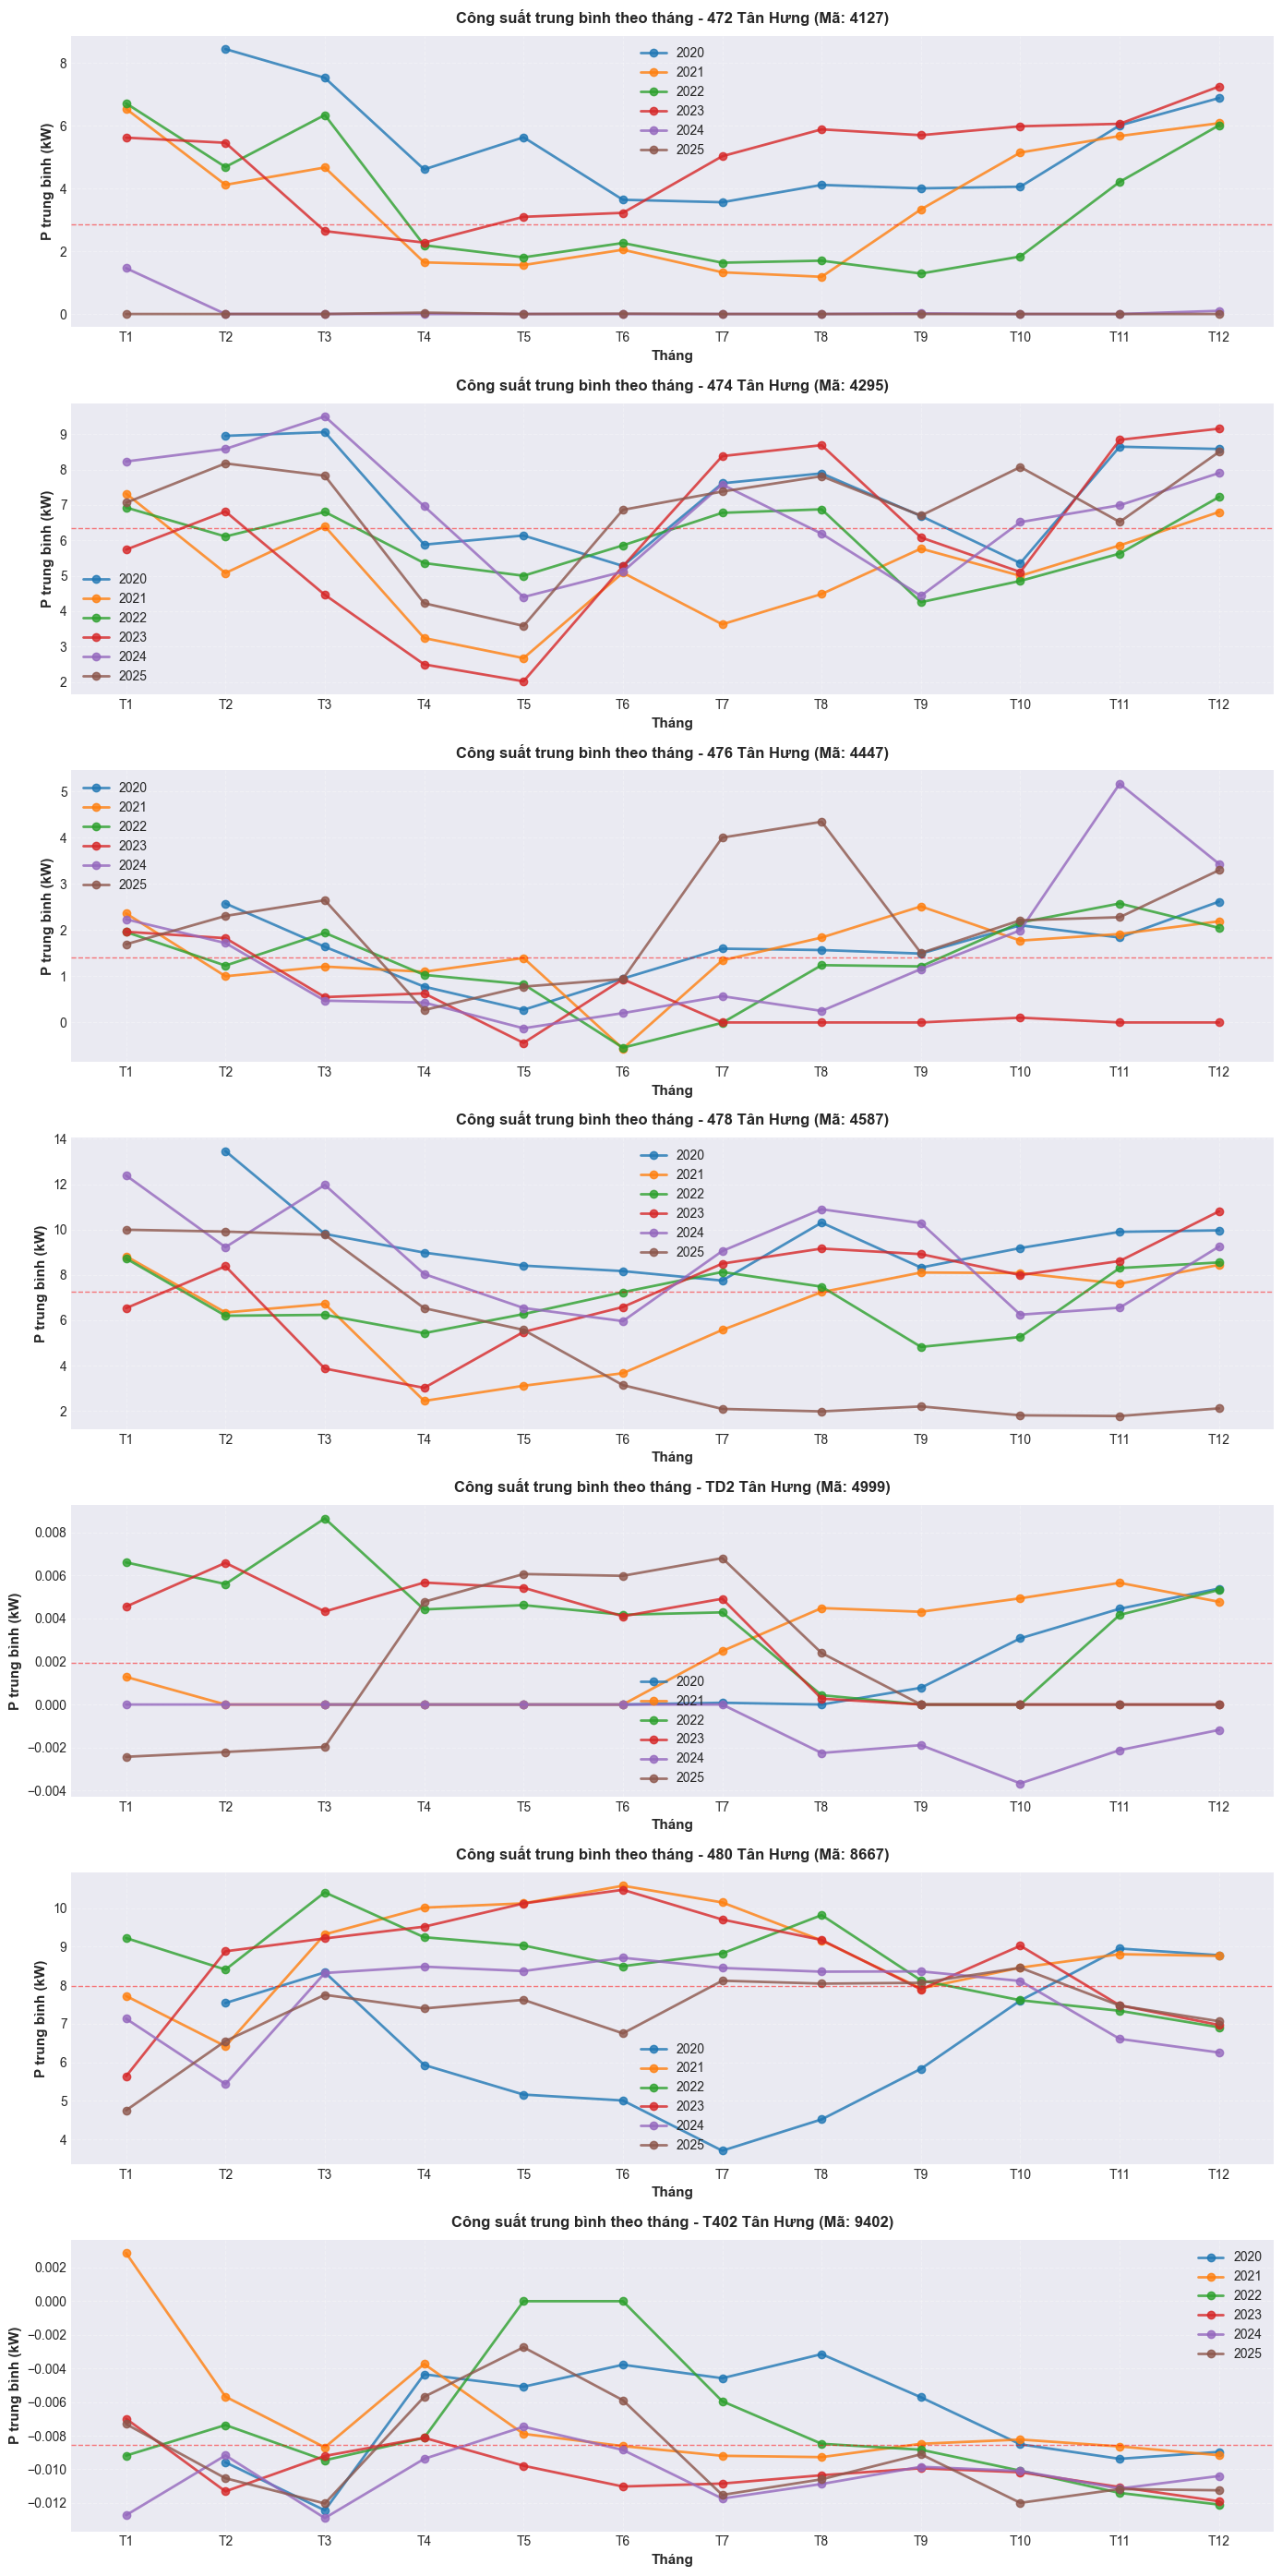


✅ Đã vẽ xong biểu đồ cho tất cả trạm!

THỐNG KÊ TỔNG HỢP:

472 Tân Hưng (Mã: 4127):
  P trung bình tổng thể: 2.85 kW
  P min: 0.00 kW
  P max: 8.44 kW
  Độ lệch chuẩn: 2.57 kW
  Tháng cao nhất: 2/2020 = 8.44 kW
  Tháng thấp nhất: 2/2024 = 0.00 kW

474 Tân Hưng (Mã: 4295):
  P trung bình tổng thể: 6.36 kW
  P min: 2.02 kW
  P max: 9.50 kW
  Độ lệch chuẩn: 1.73 kW
  Tháng cao nhất: 3/2024 = 9.50 kW
  Tháng thấp nhất: 5/2023 = 2.02 kW

476 Tân Hưng (Mã: 4447):
  P trung bình tổng thể: 1.42 kW
  P min: -0.57 kW
  P max: 5.17 kW
  Độ lệch chuẩn: 1.14 kW
  Tháng cao nhất: 11/2024 = 5.17 kW
  Tháng thấp nhất: 6/2021 = -0.57 kW

478 Tân Hưng (Mã: 4587):
  P trung bình tổng thể: 7.24 kW
  P min: 1.77 kW
  P max: 13.46 kW
  Độ lệch chuẩn: 2.71 kW
  Tháng cao nhất: 2/2020 = 13.46 kW
  Tháng thấp nhất: 11/2025 = 1.77 kW

TD2 Tân Hưng (Mã: 4999):
  P trung bình tổng thể: 0.00 kW
  P min: -0.00 kW
  P max: 0.01 kW
  Độ lệch chuẩn: 0.00 kW
  Tháng cao nhất: 3/2022 = 0.01 kW
  Tháng thấp nhất: 10/202

In [24]:
## THỐNG KÊ P TRUNG BÌNH THEO THÁNG VÀ NĂM CHO TỪNG TRẠM

print("=" * 80)
print("THỐNG KÊ P TRUNG BÌNH THEO THÁNG VÀ NĂM (THEO MaDiemDo)")
print("=" * 80)

# Thêm cột năm và tháng
df_all['year'] = df_all['TIME'].dt.year
df_all['month'] = df_all['TIME'].dt.month

# Tính P trung bình theo tháng, năm, và trạm
monthly_avg = df_all.groupby(['MaDiemDo', 'TenDiemDo', 'year', 'month'])['P_kW'].mean().reset_index()
monthly_avg.columns = ['MaDiemDo', 'TenDiemDo', 'year', 'month', 'P_avg']

# In bảng thống kê
print("\nBẢNG THỐNG KÊ P TRUNG BÌNH (kW):")
print(f"{'Trạm':<20} {'Năm':<8} {'Tháng':<8} {'P_avg (kW)':<15}")
print("-" * 60)

for station_id in sorted(monthly_avg['MaDiemDo'].unique()):
    station_data = monthly_avg[monthly_avg['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    
    print(f"\n{station_name} (Mã: {station_id}):")
    for _, row in station_data.iterrows():
        print(f"  {row['year']:<8} {row['month']:<8} {row['P_avg']:<15.2f}")

# Vẽ biểu đồ cho từng trạm
print("\n" + "=" * 80)
print("VẼ BIỂU ĐỒ P TRUNG BÌNH THEO THÁNG VÀ NĂM")
print("=" * 80)

# Lấy danh sách trạm
stations = sorted(df_all['MaDiemDo'].unique())
years = sorted(df_all['year'].unique())

# Tạo figure với nhiều subplot (1 subplot cho mỗi trạm)
fig, axes = plt.subplots(len(stations), 1, figsize=(14, 4 * len(stations)))

# Nếu chỉ có 1 trạm, axes không phải là array
if len(stations) == 1:
    axes = [axes]

# Màu sắc cho từng năm
colors = plt.cm.tab10(range(len(years)))

for idx, station_id in enumerate(stations):
    ax = axes[idx]
    
    # Lọc data của trạm này
    station_data = monthly_avg[monthly_avg['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Vẽ đường cho từng năm
    for year_idx, year in enumerate(years):
        year_data = station_data[station_data['year'] == year].sort_values('month')
        
        if len(year_data) > 0:
            ax.plot(year_data['month'], year_data['P_avg'], 
                   marker='o', linewidth=2, markersize=6,
                   label=f'{year}', color=colors[year_idx], alpha=0.8)
    
    # Định dạng biểu đồ
    ax.set_xlabel('Tháng', fontsize=11, fontweight='bold')
    ax.set_ylabel('P trung bình (kW)', fontsize=11, fontweight='bold')
    ax.set_title(f'Công suất trung bình theo tháng - {station_name} (Mã: {station_id})', 
                fontsize=12, fontweight='bold', pad=10)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12'])
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='best', fontsize=10, framealpha=0.9)
    
    # Thêm đường ngang cho giá trị trung bình tổng thể
    overall_avg = station_data['P_avg'].mean()
    ax.axhline(y=overall_avg, color='red', linestyle='--', linewidth=1, 
              alpha=0.5, label=f'TB tổng: {overall_avg:.2f} kW')

plt.tight_layout()
plt.show()

print("\n✅ Đã vẽ xong biểu đồ cho tất cả trạm!")

# Thống kê tổng hợp
print("\n" + "=" * 80)
print("THỐNG KÊ TỔNG HỢP:")
print("=" * 80)

for station_id in sorted(monthly_avg['MaDiemDo'].unique()):
    station_data = monthly_avg[monthly_avg['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    
    print(f"\n{station_name} (Mã: {station_id}):")
    print(f"  P trung bình tổng thể: {station_data['P_avg'].mean():.2f} kW")
    print(f"  P min: {station_data['P_avg'].min():.2f} kW")
    print(f"  P max: {station_data['P_avg'].max():.2f} kW")
    print(f"  Độ lệch chuẩn: {station_data['P_avg'].std():.2f} kW")
    
    # Tháng có P cao nhất và thấp nhất
    max_row = station_data.loc[station_data['P_avg'].idxmax()]
    min_row = station_data.loc[station_data['P_avg'].idxmin()]
    
    print(f"  Tháng cao nhất: {int(max_row['month'])}/{int(max_row['year'])} = {max_row['P_avg']:.2f} kW")
    print(f"  Tháng thấp nhất: {int(min_row['month'])}/{int(min_row['year'])} = {min_row['P_avg']:.2f} kW")

# Xóa cột tạm
df_all = df_all.drop(columns=['year', 'month'])

print("\n" + "=" * 80)
print("✅ Đã hoàn thành thống kê P trung bình!")
print("=" * 80)


In [25]:
## BỎ TRẠM 4999, 9402, VÀ 4127, SAU ĐÓ XUẤT FILE CSV
print("=" * 80)
print("BỎ TRẠM 4999, 9402, VÀ 4127, SAU ĐÓ XUẤT FILE CSV")
print("=" * 80)

# Thống kê trước khi bỏ
print(f"\nTRƯỚC KHI BỎ TRẠM:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số trạm: {df_all['MaDiemDo'].nunique()}")

# Thống kê trạm 4999
station_4999 = df_all[df_all['MaDiemDo'] == 4999]
if len(station_4999) > 0:
    station_name = station_4999['TenDiemDo'].iloc[0]
    has_data = station_4999['P_kW'].notna().sum()
    nan_count = station_4999['P_kW'].isna().sum()
    print(f"\nThông tin trạm 4999:")
    print(f"  Tên: {station_name}")
    print(f"  Tổng records: {len(station_4999):,}")
    print(f"  Có data: {has_data:,}")
    print(f"  Thiếu data: {nan_count:,}")

# Thống kê trạm 9402
station_9402 = df_all[df_all['MaDiemDo'] == 9402]
if len(station_9402) > 0:
    station_name = station_9402['TenDiemDo'].iloc[0]
    has_data = station_9402['P_kW'].notna().sum()
    nan_count = station_9402['P_kW'].isna().sum()
    print(f"\nThông tin trạm 9402:")
    print(f"  Tên: {station_name}")
    print(f"  Tổng records: {len(station_9402):,}")
    print(f"  Có data: {has_data:,}")
    print(f"  Thiếu data: {nan_count:,}")

# Thống kê trạm 4127
station_4127 = df_all[df_all['MaDiemDo'] == 4127]
if len(station_4127) > 0:
    station_name = station_4127['TenDiemDo'].iloc[0]
    has_data = station_4127['P_kW'].notna().sum()
    nan_count = station_4127['P_kW'].isna().sum()
    print(f"\nThông tin trạm 4127:")
    print(f"  Tên: {station_name}")
    print(f"  Tổng records: {len(station_4127):,}")
    print(f"  Có data: {has_data:,}")
    print(f"  Thiếu data: {nan_count:,}")

# Lọc bỏ trạm 4999, 9402, và 4127
df_all = df_all[~df_all['MaDiemDo'].isin([4999, 9402, 4127])].copy()
df_all = df_all.reset_index(drop=True)

print(f"\n{'='*80}")
print(f"ĐÃ XÓA TRẠM 4999, 9402, VÀ 4127")
print(f"{'='*80}")

# Thống kê sau khi bỏ
print(f"\nSAU KHI BỎ 3 TRẠM:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số records có data: {df_all['P_kW'].notna().sum():,}")
print(f"  Số records thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")
print(f"  Khoảng thời gian: {df_all['TIME'].min()} → {df_all['TIME'].max()}")
print(f"  Số trạm: {df_all['MaDiemDo'].nunique()}")

# Danh sách trạm còn lại
print(f"\nCác trạm còn lại:")
for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    has_data = station_data['P_kW'].notna().sum()
    total = len(station_data)
    print(f"  {station_name} (Mã: {station_id}): {total:,} records ({has_data:,} có data)")

# XUẤT FILE CSV
print(f"\n{'='*80}")
print(f"XUẤT FILE CSV")
print(f"{'='*80}")

# Kiểm tra thông tin trước khi xuất
print(f"\nThông tin data sẽ xuất:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số records có data: {df_all['P_kW'].notna().sum():,}")
print(f"  Số records thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")
print(f"  Khoảng thời gian: {df_all['TIME'].min()} → {df_all['TIME'].max()}")
print(f"  Số trạm: {df_all['MaDiemDo'].nunique()}")
print(f"  Số cột: {len(df_all.columns)}")

# Hiển thị các cột
print(f"\nCác cột trong file:")
for idx, col in enumerate(df_all.columns, 1):
    dtype = df_all[col].dtype
    nan_count = df_all[col].isna().sum()
    print(f"  {idx:2d}. {col:<20} ({dtype}, {nan_count:,} NaN)")

# Tên file output
output_file = 'TanHung_30min_cleaned_4stations_6years.csv'

# Xuất file
print(f"\nĐang xuất file: {output_file}")
df_all.to_csv(output_file, index=False, encoding='utf-8-sig')

# Kiểm tra file đã tạo
import os
if os.path.exists(output_file):
    file_size = os.path.getsize(output_file) / (1024 * 1024)  # MB
    print(f"\n✅ Đã xuất file thành công!")
    print(f"   Tên file: {output_file}")
    print(f"   Kích thước: {file_size:.2f} MB")
    print(f"   Vị trí: {os.path.abspath(output_file)}")
else:
    print(f"\n⚠️ Lỗi: Không tìm thấy file sau khi xuất!")

print("\n" + "=" * 80)
print("✅ Hoàn thành!")
print(f"   - Đã bỏ trạm 4999, 9402, và 4127")
print(f"   - Còn lại 4 trạm")
print(f"   - File đã xuất: {output_file}")
print("=" * 80)


BỎ TRẠM 4999, 9402, VÀ 4127, SAU ĐÓ XUẤT FILE CSV

TRƯỚC KHI BỎ TRẠM:
  Tổng số records: 723,408
  Số trạm: 7

Thông tin trạm 4999:
  Tên: TD2 Tân Hưng
  Tổng records: 103,344
  Có data: 98,376
  Thiếu data: 4,968

Thông tin trạm 9402:
  Tên: T402 Tân Hưng
  Tổng records: 103,344
  Có data: 101,890
  Thiếu data: 1,454

Thông tin trạm 4127:
  Tên: 472 Tân Hưng
  Tổng records: 103,344
  Có data: 102,187
  Thiếu data: 1,157

ĐÃ XÓA TRẠM 4999, 9402, VÀ 4127

SAU KHI BỎ 3 TRẠM:
  Tổng số records: 413,376
  Số records có data: 408,558
  Số records thiếu data (NaN): 4,818
  Khoảng thời gian: 2020-02-09 00:00:00 → 2025-12-31 23:30:00
  Số trạm: 4

Các trạm còn lại:
  474 Tân Hưng (Mã: 4295): 103,344 records (102,155 có data)
  476 Tân Hưng (Mã: 4447): 103,344 records (102,126 có data)
  478 Tân Hưng (Mã: 4587): 103,344 records (102,142 có data)
  480 Tân Hưng (Mã: 8667): 103,344 records (102,135 có data)

XUẤT FILE CSV

Thông tin data sẽ xuất:
  Tổng số records: 413,376
  Số records có data: 4

In [26]:
## THỐNG KÊ CÁC TRƯỜNG HỢP P = 0

print("=" * 80)
print("THỐNG KÊ CÁC TRƯỜNG HỢP P_kW = 0")
print("=" * 80)

# Lọc các records có P_kW = 0 (không phải NaN)
df_zero_p = df_all[(df_all['P_kW'] == 0) & (df_all['P_kW'].notna())].copy()

print(f"\nTổng quan:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số records có P_kW = 0: {len(df_zero_p):,}")
print(f"  Tỷ lệ: {len(df_zero_p) / len(df_all) * 100:.4f}%")

if len(df_zero_p) > 0:
    print(f"\n{'='*80}")
    print(f"PHÂN BỐ THEO TRẠM:")
    print(f"{'='*80}")
    
    # Thống kê theo trạm
    print(f"\n{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Số lượng':<12} {'% trong trạm':<15}")
    print("-" * 70)
    
    for idx, station_id in enumerate(sorted(df_zero_p['MaDiemDo'].unique()), 1):
        station_data = df_zero_p[df_zero_p['MaDiemDo'] == station_id]
        station_name = station_data['TenDiemDo'].iloc[0]
        
        # Tổng records của trạm này
        total_station = len(df_all[df_all['MaDiemDo'] == station_id])
        count = len(station_data)
        percent = count / total_station * 100
        
        print(f"{idx:<5} {station_name:<20} {station_id:<8} {count:<12,} {percent:<15.4f}")
    
    # Phân bố theo năm
    print(f"\n{'='*80}")
    print(f"PHÂN BỐ THEO NĂM:")
    print(f"{'='*80}")
    
    df_zero_p['year'] = df_zero_p['TIME'].dt.year
    
    print(f"\n{'Năm':<8} {'Số lượng':<12} {'% trong năm':<15}")
    print("-" * 40)
    
    for year in sorted(df_zero_p['year'].unique()):
        year_data = df_zero_p[df_zero_p['year'] == year]
        total_year = len(df_all[df_all['TIME'].dt.year == year])
        count = len(year_data)
        percent = count / total_year * 100
        
        print(f"{year:<8} {count:<12,} {percent:<15.4f}")
    
    # Phân bố theo tháng
    print(f"\n{'='*80}")
    print(f"PHÂN BỐ THEO THÁNG:")
    print(f"{'='*80}")
    
    df_zero_p['month'] = df_zero_p['TIME'].dt.month
    
    print(f"\n{'Tháng':<8} {'Số lượng':<12} {'% trong tháng':<15}")
    print("-" * 40)
    
    for month in sorted(df_zero_p['month'].unique()):
        month_data = df_zero_p[df_zero_p['month'] == month]
        total_month = len(df_all[df_all['TIME'].dt.month == month])
        count = len(month_data)
        percent = count / total_month * 100
        
        print(f"{month:<8} {count:<12,} {percent:<15.4f}")
    
    # Kiểm tra các giá trị khác khi P = 0
    print(f"\n{'='*80}")
    print(f"KIỂM TRA CÁC GIÁ TRỊ KHÁC KHI P = 0:")
    print(f"{'='*80}")
    
    print(f"\nThống kê UA, UB, UC:")
    print(f"  UA: min={df_zero_p['UA'].min():.2f}, max={df_zero_p['UA'].max():.2f}, mean={df_zero_p['UA'].mean():.2f}")
    print(f"  UB: min={df_zero_p['UB'].min():.2f}, max={df_zero_p['UB'].max():.2f}, mean={df_zero_p['UB'].mean():.2f}")
    print(f"  UC: min={df_zero_p['UC'].min():.2f}, max={df_zero_p['UC'].max():.2f}, mean={df_zero_p['UC'].mean():.2f}")
    
    print(f"\nThống kê IA, IB, IC:")
    print(f"  IA: min={df_zero_p['IA'].min():.2f}, max={df_zero_p['IA'].max():.2f}, mean={df_zero_p['IA'].mean():.2f}")
    print(f"  IB: min={df_zero_p['IB'].min():.2f}, max={df_zero_p['IB'].max():.2f}, mean={df_zero_p['IB'].mean():.2f}")
    print(f"  IC: min={df_zero_p['IC'].min():.2f}, max={df_zero_p['IC'].max():.2f}, mean={df_zero_p['IC'].mean():.2f}")
    
    print(f"\nThống kê CosF:")
    print(f"  Min: {df_zero_p['CosF'].min():.4f}")
    print(f"  Max: {df_zero_p['CosF'].max():.4f}")
    print(f"  Mean: {df_zero_p['CosF'].mean():.4f}")
    
    # Kiểm tra có bao nhiêu trường hợp I = 0
    zero_ia = (df_zero_p['IA'] == 0).sum()
    zero_ib = (df_zero_p['IB'] == 0).sum()
    zero_ic = (df_zero_p['IC'] == 0).sum()
    all_zero_i = ((df_zero_p['IA'] == 0) & (df_zero_p['IB'] == 0) & (df_zero_p['IC'] == 0)).sum()
    
    print(f"\nSố trường hợp dòng điện = 0:")
    print(f"  IA = 0: {zero_ia:,} records")
    print(f"  IB = 0: {zero_ib:,} records")
    print(f"  IC = 0: {zero_ic:,} records")
    print(f"  Cả 3 pha = 0: {all_zero_i:,} records")
    
    # Hiển thị 20 ví dụ
    print(f"\n{'='*80}")
    print(f"20 VÍ DỤ ĐẦU TIÊN:")
    print(f"{'='*80}")
    
    for idx, row in enumerate(df_zero_p.head(20).itertuples(), 1):
        print(f"\n{idx}. {row.TenDiemDo} - {row.TIME}")
        print(f"   P_kW = {row.P_kW:.4f}")
        print(f"   UA={row.UA:.2f}V, UB={row.UB:.2f}V, UC={row.UC:.2f}V")
        print(f"   IA={row.IA:.2f}A, IB={row.IB:.2f}A, IC={row.IC:.2f}A")
        print(f"   CosF={row.CosF:.4f}")
        if 'P_calculated' in df_zero_p.columns:
            print(f"   P_calculated={row.P_calculated:.4f} kW")
    
    # Phân tích gaps (khoảng trống liên tục P = 0)
    print(f"\n{'='*80}")
    print(f"PHÂN TÍCH GAPS (KHOẢNG LIÊN TỤC P = 0):")
    print(f"{'='*80}")
    
    for station_id in sorted(df_zero_p['MaDiemDo'].unique()):
        station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
        station_name = station_data['TenDiemDo'].iloc[0]
        
        # Tạo cột đánh dấu P = 0
        station_data['is_zero'] = (station_data['P_kW'] == 0) & (station_data['P_kW'].notna())
        station_data['zero_group'] = (station_data['is_zero'] != station_data['is_zero'].shift()).cumsum()
        
        # Lọc các nhóm P = 0
        zero_gaps = station_data[station_data['is_zero']].groupby('zero_group').agg({
            'TIME': ['first', 'last', 'count']
        }).reset_index(drop=True)
        
        if len(zero_gaps) > 0:
            zero_gaps.columns = ['start_time', 'end_time', 'gap_size']
            zero_gaps = zero_gaps.sort_values('gap_size', ascending=False)
            
            print(f"\n{station_name} (Mã: {station_id}):")
            print(f"  Tổng số gaps: {len(zero_gaps)}")
            print(f"  Tổng số mốc P=0: {zero_gaps['gap_size'].sum()}")
            
            # Top 5 gaps lớn nhất
            print(f"\n  Top 5 gaps lớn nhất:")
            for gap_idx, gap in enumerate(zero_gaps.head(5).itertuples(), 1):
                duration_hours = gap.gap_size * 0.5
                duration_days = duration_hours / 24
                print(f"    {gap_idx}. {gap.start_time} → {gap.end_time}")
                print(f"       Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    
    # Xóa cột tạm
    df_zero_p = df_zero_p.drop(columns=['year', 'month'], errors='ignore')
    
else:
    print("\n✅ HOÀN HẢO: Không có trường hợp nào P_kW = 0!")

print("\n" + "=" * 80)
print("✅ Đã hoàn thành thống kê P = 0!")
print("=" * 80)


THỐNG KÊ CÁC TRƯỜNG HỢP P_kW = 0

Tổng quan:
  Tổng số records: 413,376
  Số records có P_kW = 0: 34,802
  Tỷ lệ: 8.4190%

PHÂN BỐ THEO TRẠM:

STT   Tên trạm             Mã       Số lượng     % trong trạm   
----------------------------------------------------------------------
1     474 Tân Hưng         4295     844          0.8167         
2     476 Tân Hưng         4447     29,508       28.5532        
3     478 Tân Hưng         4587     1,909        1.8472         
4     480 Tân Hưng         8667     2,541        2.4588         

PHÂN BỐ THEO NĂM:

Năm      Số lượng     % trong năm    
----------------------------------------
2020     4,717        7.5131         
2021     4,293        6.1259         
2022     4,606        6.5725         
2023     11,243       16.0431        
2024     4,651        6.6186         
2025     5,292        7.5514         

PHÂN BỐ THEO THÁNG:

Tháng    Số lượng     % trong tháng  
----------------------------------------
1        1,586        5.3293     

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. ĐỌC TẤT CẢ FILE CSV 30 PHÚT

In [ ]:
# Đường dẫn đến thư mục chứa data 30p
data_path = Path('Upgit/data/Tan Hung_30p/224')

# Tìm tất cả file CSV
all_files = list(data_path.rglob('*.csv'))
print(f"Tìm thấy {len(all_files)} file CSV")

# Đọc tất cả file
print("\nĐang đọc dữ liệu...")
dfs = []

for idx, file in enumerate(all_files):
    try:
        df = pd.read_csv(file)
        df['source_file'] = file.name
        df['year'] = file.parent.name
        dfs.append(df)
        
        if (idx + 1) % 10 == 0:
            print(f"  Đã đọc {idx + 1}/{len(all_files)} files...")
    except Exception as e:
        print(f"  Lỗi đọc {file.name}: {e}")

# Gộp tất cả dataframes
df_all = pd.concat(dfs, ignore_index=True)
print(f"\nĐã gộp xong! Tổng số records: {len(df_all):,}")

Tìm thấy 71 file CSV

Đang đọc dữ liệu...
  Đã đọc 10/71 files...
  Đã đọc 20/71 files...
  Đã đọc 30/71 files...
  Đã đọc 40/71 files...
  Đã đọc 50/71 files...
  Đã đọc 60/71 files...
  Đã đọc 70/71 files...

Đã gộp xong! Tổng số records: 712,736


In [ ]:
# Parse datetime và sắp xếp
df_all['TIME'] = pd.to_datetime(df_all['TIME'])
df_all = df_all.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

print(f"Khoảng thời gian: {df_all['TIME'].min()} đến {df_all['TIME'].max()}")
print(f"Số điểm đo: {df_all['MaDiemDo'].nunique()}")
print(f"Các điểm đo: {sorted(df_all['MaDiemDo'].unique())}")

Khoảng thời gian: 2020-02-09 00:00:00 đến 2025-12-31 23:35:51
Số điểm đo: 7
Các điểm đo: [np.int64(4127), np.int64(4295), np.int64(4447), np.int64(4587), np.int64(4999), np.int64(8667), np.int64(9402)]


In [ ]:
df_all.isna().sum()

MBA                0
MAMBA              0
MaDiemDo           0
TenDiemDo          0
TIME               0
UA             13387
UB             13387
UC             13384
IA               530
IB               780
IC               815
CosF             923
P_kW            1096
Q_kVAr           979
source_file        0
year               0
dtype: int64

In [ ]:
## XỬ LÝ THEO NGUYÊN TẮC VẬT LÝ

print("=" * 80)
print("XỬ LÝ THEO NGUYÊN TẮC VẬT LÝ")
print("=" * 80)

# ============================================================================
# 1. XỬ LÝ CosF NGOÀI [-1, 1]
# ============================================================================
print("\n" + "=" * 80)
print("1. XỬ LÝ CosF NGOÀI [-1, 1]")
print("=" * 80)

# Kiểm tra CosF vi phạm
cosf_invalid = ((df_all['CosF'] < -1) | (df_all['CosF'] > 1)).sum()
print(f"\nSố records có CosF ngoài [-1, 1]: {cosf_invalid:,}")

if cosf_invalid > 0:
    # Thống kê chi tiết
    invalid_data = df_all[(df_all['CosF'] < -1) | (df_all['CosF'] > 1)]
    print(f"\nThống kê CosF vi phạm:")
    print(f"  Min: {invalid_data['CosF'].min():.4f}")
    print(f"  Max: {invalid_data['CosF'].max():.4f}")
    print(f"  Mean: {invalid_data['CosF'].mean():.4f}")
    
    # Phân bố theo trạm
    print(f"\nPhân bố theo trạm:")
    for station_id in sorted(df_all['MaDiemDo'].unique()):
        station_invalid = invalid_data[invalid_data['MaDiemDo'] == station_id]
        if len(station_invalid) > 0:
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {len(station_invalid):,} records")
    
    # Clip CosF về [-1, 1]
    df_all['CosF'] = df_all['CosF'].clip(-1, 1)
    
    print(f"\n✅ Đã clip {cosf_invalid:,} giá trị CosF về khoảng [-1, 1]")
else:
    print(f"\n✅ Tất cả CosF đều trong khoảng [-1, 1]")

# ============================================================================
# 2. KIỂM TRA MÂU THUẪN I=0 NHƯNG P>0
# ============================================================================
print("\n" + "=" * 80)
print("2. KIỂM TRA MÂU THUẪN I=0 NHƯNG P>0")
print("=" * 80)

# Kiểm tra mâu thuẫn: Tất cả 3 pha I=0 nhưng P>0
contradiction = (
    (df_all['IA'] == 0) & 
    (df_all['IB'] == 0) & 
    (df_all['IC'] == 0) & 
    (df_all['P_kW'] > 0)
).sum()

print(f"\nSố records có I=0 (cả 3 pha) nhưng P>0: {contradiction:,}")

if contradiction > 0:
    # Thống kê chi tiết
    contra_data = df_all[
        (df_all['IA'] == 0) & 
        (df_all['IB'] == 0) & 
        (df_all['IC'] == 0) & 
        (df_all['P_kW'] > 0)
    ]
    
    print(f"\nThống kê P trong các trường hợp mâu thuẫn:")
    print(f"  Min P: {contra_data['P_kW'].min():.2f} kW")
    print(f"  Max P: {contra_data['P_kW'].max():.2f} kW")
    print(f"  Mean P: {contra_data['P_kW'].mean():.2f} kW")
    
    # Phân bố theo trạm
    print(f"\nPhân bố theo trạm:")
    for station_id in sorted(df_all['MaDiemDo'].unique()):
        station_contra = contra_data[contra_data['MaDiemDo'] == station_id]
        if len(station_contra) > 0:
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {len(station_contra):,} records")
    
    # Hiển thị 10 ví dụ
    print(f"\n10 ví dụ đầu tiên:")
    print(contra_data[['TIME', 'MaDiemDo', 'TenDiemDo', 'IA', 'IB', 'IC', 'P_kW']].head(10))
    
    # Set P = 0 khi I = 0 (cả 3 pha)
    mask = (df_all['IA'] == 0) & (df_all['IB'] == 0) & (df_all['IC'] == 0) & (df_all['P_kW'] > 0)
    df_all.loc[mask, 'P_kW'] = 0
    
    print(f"\n✅ Đã set P = 0 cho {contradiction:,} records mâu thuẫn")
else:
    print(f"\n✅ Không có mâu thuẫn I=0 nhưng P>0")

# ============================================================================
# THỐNG KÊ SAU XỬ LÝ
# ============================================================================
print("\n" + "=" * 80)
print("THỐNG KÊ SAU XỬ LÝ")
print("=" * 80)

print(f"\nCosF:")
print(f"  Min: {df_all['CosF'].min():.4f}")
print(f"  Max: {df_all['CosF'].max():.4f}")
print(f"  Mean: {df_all['CosF'].mean():.4f}")

print(f"\nP_kW:")
print(f"  Min: {df_all['P_kW'].min():.2f} kW")
print(f"  Max: {df_all['P_kW'].max():.2f} kW")
print(f"  Mean: {df_all['P_kW'].mean():.2f} kW")

print("\n" + "=" * 80)
print("✅ Hoàn thành xử lý theo nguyên tắc vật lý!")
print("=" * 80)


XỬ LÝ THEO NGUYÊN TẮC VẬT LÝ

1. XỬ LÝ CosF NGOÀI [-1, 1]

Số records có CosF ngoài [-1, 1]: 81

Thống kê CosF vi phạm:
  Min: 1.1067
  Max: 97.0000
  Mean: 27.2463

Phân bố theo trạm:
  474 Tân Hưng (Mã 4295): 7 records
  476 Tân Hưng (Mã 4447): 3 records
  478 Tân Hưng (Mã 4587): 1 records
  TD2 Tân Hưng (Mã 4999): 20 records
  480 Tân Hưng (Mã 8667): 49 records
  T402 Tân Hưng (Mã 9402): 1 records

✅ Đã clip 81 giá trị CosF về khoảng [-1, 1]

2. KIỂM TRA MÂU THUẪN I=0 NHƯNG P>0

Số records có I=0 (cả 3 pha) nhưng P>0: 234

Thống kê P trong các trường hợp mâu thuẫn:
  Min P: 0.00 kW
  Max P: 1.12 kW
  Mean P: 0.28 kW

Phân bố theo trạm:
  472 Tân Hưng (Mã 4127): 17 records
  474 Tân Hưng (Mã 4295): 24 records
  476 Tân Hưng (Mã 4447): 109 records
  478 Tân Hưng (Mã 4587): 47 records
  TD2 Tân Hưng (Mã 4999): 23 records
  480 Tân Hưng (Mã 8667): 14 records

10 ví dụ đầu tiên:
                     TIME  MaDiemDo     TenDiemDo   IA   IB   IC     P_kW
11009 2020-10-12 13:00:04      4127 

In [ ]:
## TÍNH P THEO CÔNG THỨC VÀ THỐNG KÊ ĐỘ LỆCH

print("=" * 80)
print("TÍNH P THEO CÔNG THỨC: P = (UA×IA + UB×IB + UC×IC) × CosF / 1000000")
print("=" * 80)

# Kiểm tra điều kiện có đầy đủ U, I, CosF
df_all['has_U'] = df_all[['UA', 'UB', 'UC']].notna().all(axis=1)
df_all['has_I'] = df_all[['IA', 'IB', 'IC']].notna().all(axis=1)
df_all['has_CosF'] = df_all['CosF'].notna()
df_all['has_UICosF'] = df_all['has_U'] & df_all['has_I'] & df_all['has_CosF']
df_all['has_P_original'] = df_all['P_kW'].notna()

print(f"Tổng số records: {len(df_all):,}")
print(f"Có đầy đủ U, I, CosF: {df_all['has_UICosF'].sum():,}")
print(f"Có P gốc: {df_all['has_P_original'].sum():,}")
print(f"Có đầy đủ U, I, CosF VÀ có P gốc: {(df_all['has_UICosF'] & df_all['has_P_original']).sum():,}")
print(f"Có đầy đủ U, I, CosF NHƯNG KHÔNG có P gốc: {(df_all['has_UICosF'] & ~df_all['has_P_original']).sum():,}")

# Tính P theo công thức cho các dòng có đầy đủ U, I, CosF
def calculate_P(row):
    """Tính P = (UA×IA + UB×IB + UC×IC) × CosF / 1000000"""
    if row['has_UICosF']:
        sum_UI = row['UA'] * row['IA'] + row['UB'] * row['IB'] + row['UC'] * row['IC']
        P_calc = sum_UI * row['CosF'] / 1000000
        return P_calc
    else:
        return np.nan

df_all['P_calculated'] = df_all.apply(calculate_P, axis=1)

print(f"\nĐã tính P cho: {df_all['P_calculated'].notna().sum():,} records")

# Tính độ lệch cho các dòng có cả P gốc và P tính toán
df_all['P_diff'] = np.nan
mask_both = df_all['has_UICosF'] & df_all['has_P_original']
df_all.loc[mask_both, 'P_diff'] = abs(df_all.loc[mask_both, 'P_calculated'] - df_all.loc[mask_both, 'P_kW'])

print(f"Số records có thể so sánh (có cả P gốc và P tính): {mask_both.sum():,}")

# Thống kê độ lệch (sắp xếp giảm dần)
print("\n" + "=" * 80)
print("THỐNG KÊ ĐỘ LỆCH (|P_calculated - P_original|) - CHIỀU GIẢM DẦN:")
print("=" * 80)

if mask_both.sum() > 0:
    df_compare = df_all[mask_both].copy()
    df_compare_sorted = df_compare.sort_values('P_diff', ascending=False)
    
    print(f"\nThống kê độ lệch:")
    print(f"  Min:    {df_compare['P_diff'].min():.4f} kW")
    print(f"  Max:    {df_compare['P_diff'].max():.4f} kW")
    print(f"  Mean:   {df_compare['P_diff'].mean():.4f} kW")
    print(f"  Median: {df_compare['P_diff'].median():.4f} kW")
    print(f"  Std:    {df_compare['P_diff'].std():.4f} kW")
    
    # Phân bố độ lệch (LOẠI TRỪ - từ lớn xuống nhỏ)
    print("\nPhân bố độ lệch (LOẠI TRỪ - mỗi mẫu chỉ thuộc 1 nhóm):")

    count_ge_5 = (df_compare['P_diff'] >= 5.0).sum()
    count_4_to_5 = ((df_compare['P_diff'] >= 4.0) & (df_compare['P_diff'] < 5.0)).sum()
    count_3_to_4 = ((df_compare['P_diff'] >= 3.0) & (df_compare['P_diff'] < 4.0)).sum()
    count_2_to_3 = ((df_compare['P_diff'] >= 2.0) & (df_compare['P_diff'] < 3.0)).sum()
    count_1_to_2 = ((df_compare['P_diff'] >= 1.0) & (df_compare['P_diff'] < 2.0)).sum()
    count_05_to_1 = ((df_compare['P_diff'] >= 0.5) & (df_compare['P_diff'] < 1.0)).sum()
    count_01_to_05 = ((df_compare['P_diff'] >= 0.1) & (df_compare['P_diff'] < 0.5)).sum()
    count_lt_01 = (df_compare['P_diff'] < 0.1).sum()

    total = len(df_compare)

    print(f"  >= 5.0 kW:        {count_ge_5:,} records ({count_ge_5 / total * 100:.2f}%)")
    print(f"  [4.0, 5.0) kW:    {count_4_to_5:,} records ({count_4_to_5 / total * 100:.2f}%)")
    print(f"  [3.0, 4.0) kW:    {count_3_to_4:,} records ({count_3_to_4 / total * 100:.2f}%)")
    print(f"  [2.0, 3.0) kW:    {count_2_to_3:,} records ({count_2_to_3 / total * 100:.2f}%)")
    print(f"  [1.0, 2.0) kW:    {count_1_to_2:,} records ({count_1_to_2 / total * 100:.2f}%)")
    print(f"  [0.5, 1.0) kW:    {count_05_to_1:,} records ({count_05_to_1 / total * 100:.2f}%)")
    print(f"  [0.1, 0.5) kW:    {count_01_to_05:,} records ({count_01_to_05 / total * 100:.2f}%)")
    print(f"  < 0.1 kW:         {count_lt_01:,} records ({count_lt_01 / total * 100:.2f}%)")
    print(f"  Tổng:             {total:,} records")

    
    # 20 trường hợp lệch NHIỀU NHẤT
    print("\n" + "=" * 80)
    print("20 TRƯỜNG HỢP LỆCH NHIỀU NHẤT:")
    print("=" * 80)
    
    for idx, row in enumerate(df_compare_sorted.head(20).itertuples(), 1):
        print(f"\n{idx}. {row.TenDiemDo} - {row.TIME}")
        print(f"   P_gốc:  {row.P_kW:.4f} kW")
        print(f"   P_tính: {row.P_calculated:.4f} kW")
        print(f"   Lệch:   {row.P_diff:.4f} kW ({row.P_diff / row.P_kW * 100:.2f}%)")
        print(f"   UA={row.UA:.2f}V, UB={row.UB:.2f}V, UC={row.UC:.2f}V")
        print(f"   IA={row.IA:.2f}A, IB={row.IB:.2f}A, IC={row.IC:.2f}A")
        print(f"   CosF={row.CosF:.4f}")

else:
    print("\n⚠️ Không có records nào để so sánh!")

# Thống kê các dòng có U, I, CosF nhưng KHÔNG có P gốc
print("\n" + "=" * 80)
print("THỐNG KÊ CÁC DÒNG CÓ U, I, CosF NHƯNG KHÔNG CÓ P GỐC:")
print("=" * 80)

mask_no_P = df_all['has_UICosF'] & ~df_all['has_P_original']
print(f"Số records: {mask_no_P.sum():,}")

if mask_no_P.sum() > 0:
    df_no_P = df_all[mask_no_P].copy()
    
    print(f"\nThống kê P_calculated cho các dòng này:")
    print(f"  Min:    {df_no_P['P_calculated'].min():.4f} kW")
    print(f"  Max:    {df_no_P['P_calculated'].max():.4f} kW")
    print(f"  Mean:   {df_no_P['P_calculated'].mean():.4f} kW")
    print(f"  Median: {df_no_P['P_calculated'].median():.4f} kW")
    
    # Phân bố theo trạm
    print("\nPhân bố theo trạm:")
    for station_id in sorted(df_no_P['MaDiemDo'].unique()):
        station_data = df_no_P[df_no_P['MaDiemDo'] == station_id]
        station_name = station_data['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {len(station_data):,} records")
    
    # 10 ví dụ
    print("\n10 ví dụ:")
    for idx, row in enumerate(df_no_P.head(10).itertuples(), 1):
        print(f"\n{idx}. {row.TenDiemDo} - {row.TIME}")
        print(f"   P_tính: {row.P_calculated:.4f} kW")
        print(f"   UA={row.UA:.2f}V, UB={row.UB:.2f}V, UC={row.UC:.2f}V")
        print(f"   IA={row.IA:.2f}A, IB={row.IB:.2f}A, IC={row.IC:.2f}A")
        print(f"   CosF={row.CosF:.4f}")

# Xóa các cột tạm
df_all = df_all.drop(columns=['has_U', 'has_I', 'has_CosF', 'has_UICosF', 'has_P_original'])

print("\n✅ Đã hoàn thành tính P và thống kê độ lệch!")
print("   - P_calculated: P tính theo công thức")
print("   - P_diff: Độ lệch |P_calculated - P_kW|")


TÍNH P THEO CÔNG THỨC: P = (UA×IA + UB×IB + UC×IC) × CosF / 1000000
Tổng số records: 712,736
Có đầy đủ U, I, CosF: 699,319
Có P gốc: 711,640
Có đầy đủ U, I, CosF VÀ có P gốc: 699,319
Có đầy đủ U, I, CosF NHƯNG KHÔNG có P gốc: 0

Đã tính P cho: 699,319 records
Số records có thể so sánh (có cả P gốc và P tính): 699,319

THỐNG KÊ ĐỘ LỆCH (|P_calculated - P_original|) - CHIỀU GIẢM DẦN:

Thống kê độ lệch:
  Min:    0.0000 kW
  Max:    81.5765 kW
  Mean:   0.3010 kW
  Median: 0.0171 kW
  Std:    1.3938 kW

Phân bố độ lệch (LOẠI TRỪ - mỗi mẫu chỉ thuộc 1 nhóm):
  >= 5.0 kW:        13,854 records (1.98%)
  [4.0, 5.0) kW:    4,289 records (0.61%)
  [3.0, 4.0) kW:    5,485 records (0.78%)
  [2.0, 3.0) kW:    5,503 records (0.79%)
  [1.0, 2.0) kW:    5,259 records (0.75%)
  [0.5, 1.0) kW:    4,991 records (0.71%)
  [0.1, 0.5) kW:    70,209 records (10.04%)
  < 0.1 kW:         589,729 records (84.33%)
  Tổng:             699,319 records

20 TRƯỜNG HỢP LỆCH NHIỀU NHẤT:

1. 472 Tân Hưng - 2020-06-08

KIỂM TRA MẪU CÓ PHÚT NGOÀI MỐC 00 VÀ 30

Tổng số mẫu trong df_all: 712,736
Số mẫu có phút trong [15-29.9] hoặc [45-59.9]: 946

⚠️ CẢNH BÁO: Tìm thấy 946 mẫu có phút không đúng mốc 00 hoặc 30!

Phân bố theo phút:
minute
15    42
16    21
17    38
18    37
19    41
20    19
21    33
22    26
23    27
24    22
25    44
26    59
27    44
28    41
29    37
45    37
46    30
47    27
48    32
49    22
50    28
51    19
52    15
53    18
54    19
55    26
56    23
57    31
58    39
59    49
Name: count, dtype: int64

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 81 mẫu
  474 Tân Hưng (Mã: 4295): 111 mẫu
  476 Tân Hưng (Mã: 4447): 135 mẫu
  478 Tân Hưng (Mã: 4587): 167 mẫu
  TD2 Tân Hưng (Mã: 4999): 108 mẫu
  480 Tân Hưng (Mã: 8667): 170 mẫu
  T402 Tân Hưng (Mã: 9402): 174 mẫu

10 mẫu đầu tiên có phút không hợp lệ:
                     TIME  MaDiemDo     TenDiemDo     P_kW  minute
12098 2020-11-04 06:59:34      4127  472 Tân Hưng  4.57762      59
12105 2020-11-04 09:59:33      4127  472 Tân Hư

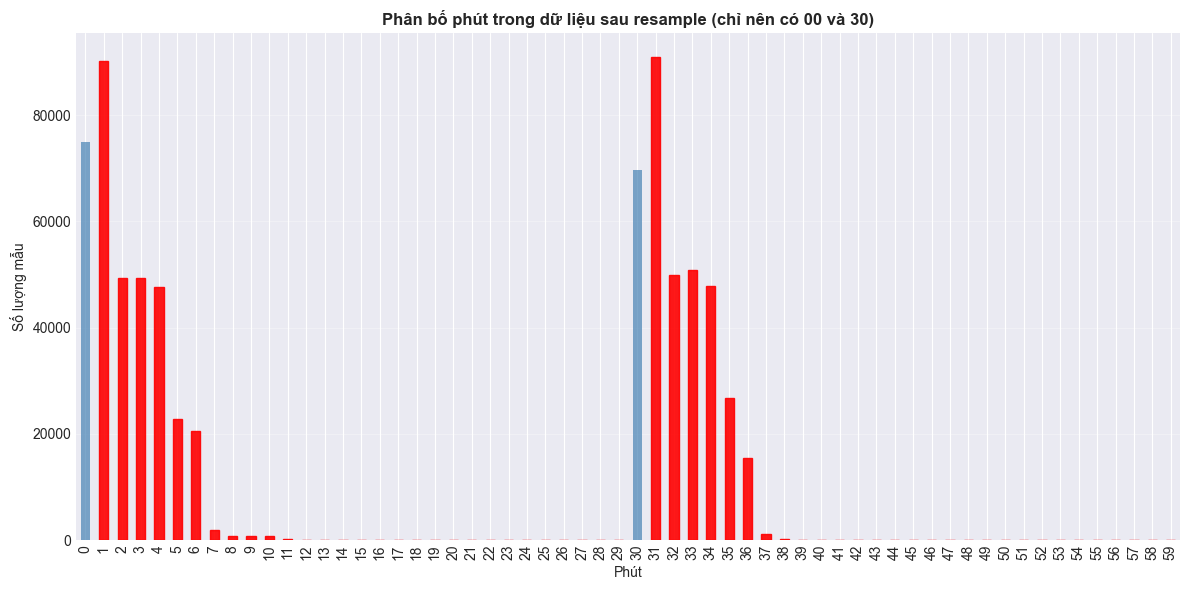

In [ ]:
## KIỂM TRA MẪU CÓ PHÚT TRONG KHOẢNG 15-29.9 VÀ 45-59.9

print("=" * 80)
print("KIỂM TRA MẪU CÓ PHÚT NGOÀI MỐC 00 VÀ 30")
print("=" * 80)

# Lấy phút từ timestamp
df_all['minute'] = df_all['TIME'].dt.minute

# Tìm các mẫu có phút trong khoảng 15-29 hoặc 45-59
invalid_minutes = df_all[
    ((df_all['minute'] >= 15) & (df_all['minute'] < 30)) |
    ((df_all['minute'] >= 45) & (df_all['minute'] < 60))
]

print(f"\nTổng số mẫu trong df_all: {len(df_all):,}")
print(f"Số mẫu có phút trong [15-29.9] hoặc [45-59.9]: {len(invalid_minutes):,}")

if len(invalid_minutes) > 0:
    print(f"\n⚠️ CẢNH BÁO: Tìm thấy {len(invalid_minutes):,} mẫu có phút không đúng mốc 00 hoặc 30!")
    
    # Thống kê theo phút
    print("\nPhân bố theo phút:")
    minute_counts = invalid_minutes['minute'].value_counts().sort_index()
    print(minute_counts)
    
    # Thống kê theo trạm
    print("\nPhân bố theo trạm:")
    station_counts = invalid_minutes.groupby('MaDiemDo').size()
    for station_id, count in station_counts.items():
        station_name = invalid_minutes[invalid_minutes['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} mẫu")
    
    # Hiển thị 10 mẫu đầu tiên
    print("\n10 mẫu đầu tiên có phút không hợp lệ:")
    print(invalid_minutes[['TIME', 'MaDiemDo', 'TenDiemDo', 'P_kW', 'minute']].head(10))
    
else:
    print("\n✅ HOÀN HẢO: Tất cả mẫu đều có phút = 00 hoặc 30!")
    print("   Resample đã hoạt động chính xác.")

# Kiểm tra phân bố phút hợp lệ
print("\n" + "=" * 80)
print("PHÂN BỐ PHÚT HỢP LỆ (CHỈ NÊN CÓ 00 VÀ 30)")
print("=" * 80)
minute_distribution = df_all['minute'].value_counts().sort_index()
print(minute_distribution)

# Vẽ biểu đồ phân bố phút
fig, ax = plt.subplots(figsize=(12, 6))
minute_distribution.plot(kind='bar', ax=ax, color='steelblue', alpha=0.7)
ax.set_xlabel('Phút')
ax.set_ylabel('Số lượng mẫu')
ax.set_title('Phân bố phút trong dữ liệu sau resample (chỉ nên có 00 và 30)', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

# Đánh dấu vùng không hợp lệ
for i, (minute, count) in enumerate(minute_distribution.items()):
    if minute not in [0, 30]:
        ax.get_children()[i].set_color('red')
        ax.get_children()[i].set_alpha(0.9)

plt.tight_layout()
plt.show()


# Xóa cột minute tạm thời
df_all = df_all.drop(columns=['minute'])


In [ ]:
## KIỂM TRA GIỜ CÓ NHIỀU HƠN 2 MẪU (DATA RAW)

print("=" * 80)
print("KIỂM TRA GIỜ CÓ NHIỀU HƠN 2 MẪU DATA")
print("=" * 80)

# Tạo cột giờ tạm thời (không thay đổi df_all)
df_temp = df_all.copy()
df_temp['hour'] = df_temp['TIME'].dt.floor('h')

# Đếm số mẫu trong mỗi giờ cho từng trạm
hour_counts = df_temp.groupby(['MaDiemDo', 'hour']).size().reset_index(name='count')

# Lọc các giờ có > 2 mẫu
duplicate_hours = hour_counts[hour_counts['count'] > 2]

print(f"\nTổng số giờ kiểm tra: {len(hour_counts):,}")
print(f"Số giờ có > 2 mẫu: {len(duplicate_hours):,}")

if len(duplicate_hours) > 0:
    print(f"\n⚠️ CẢNH BÁO: Tìm thấy {len(duplicate_hours):,} giờ có nhiều hơn 2 mẫu!")
    
    # Thống kê theo trạm
    print("\nPhân bố theo trạm:")
    station_dup_counts = duplicate_hours.groupby('MaDiemDo').size()
    for station_id, count in station_dup_counts.items():
        station_name = df_temp[df_temp['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} giờ bị trùng")
    
    # Thống kê số mẫu trùng
    print("\nPhân bố số mẫu trùng:")
    count_distribution = duplicate_hours['count'].value_counts().sort_index()
    for num_samples, freq in count_distribution.items():
        print(f"  {num_samples} mẫu/giờ: {freq:,} giờ")
    
    # Xem chi tiết 5 ví dụ đầu tiên
    print("\n" + "=" * 80)
    print("CHI TIẾT 5000 VÍ DỤ ĐẦU TIÊN")
    print("=" * 80)
    
    for i in range(min(5000, len(duplicate_hours))):
        example = duplicate_hours.iloc[i]
        station_name = df_temp[df_temp['MaDiemDo'] == example['MaDiemDo']]['TenDiemDo'].iloc[0]
        
        print(f"\n{i+1}. Giờ: {example['hour']} - {station_name} - {example['count']} mẫu")
        
        example_data = df_temp[(df_temp['MaDiemDo'] == example['MaDiemDo']) & 
                               (df_temp['hour'] == example['hour'])]
        
        # In chi tiết từng mẫu
        for idx, row in example_data.iterrows():
            time_str = row['TIME'].strftime('%Y-%m-%d %H:%M:%S')
            minute = row['TIME'].minute
            second = row['TIME'].second
            print(f"   - {time_str} (phút {minute:02d}, giây {second:02d}) → P_kW = {row['P_kW']:.2f}")
    
else:
    print("\n✅ HOÀN HẢO: Tất cả các giờ đều có tối đa 2 mẫu (00 và 30 phút)!")




KIỂM TRA GIỜ CÓ NHIỀU HƠN 2 MẪU DATA

Tổng số giờ kiểm tra: 359,591
Số giờ có > 2 mẫu: 189

⚠️ CẢNH BÁO: Tìm thấy 189 giờ có nhiều hơn 2 mẫu!

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 13 giờ bị trùng
  474 Tân Hưng (Mã: 4295): 24 giờ bị trùng
  476 Tân Hưng (Mã: 4447): 37 giờ bị trùng
  478 Tân Hưng (Mã: 4587): 38 giờ bị trùng
  TD2 Tân Hưng (Mã: 4999): 10 giờ bị trùng
  480 Tân Hưng (Mã: 8667): 32 giờ bị trùng
  T402 Tân Hưng (Mã: 9402): 35 giờ bị trùng

Phân bố số mẫu trùng:
  3 mẫu/giờ: 184 giờ
  4 mẫu/giờ: 5 giờ

CHI TIẾT 5000 VÍ DỤ ĐẦU TIÊN

1. Giờ: 2020-11-04 06:00:00 - 472 Tân Hưng - 3 mẫu
   - 2020-11-04 06:00:04 (phút 00, giây 04) → P_kW = 4.49
   - 2020-11-04 06:30:05 (phút 30, giây 05) → P_kW = 4.61
   - 2020-11-04 06:59:34 (phút 59, giây 34) → P_kW = 4.58

2. Giờ: 2020-11-04 09:00:00 - 472 Tân Hưng - 3 mẫu
   - 2020-11-04 09:00:04 (phút 00, giây 04) → P_kW = 3.47
   - 2020-11-04 09:30:03 (phút 30, giây 03) → P_kW = 3.62
   - 2020-11-04 09:59:33 (phút 59, giây 33) → P_k

In [ ]:
## XỬ LÝ GIỜ CÓ > 2 MẪU: CHỈ GIỮ 2 MẪU GẦN 00 VÀ 30 NHẤT

print("=" * 80)
print("XỬ LÝ GIỜ CÓ > 2 MẪU: CHỈ GIỮ 2 MẪU GẦN MỐC 00 VÀ 30 NHẤT")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Tính khoảng cách đến mốc 00 và 30
def distance_to_nearest_mark(minute, second):
    """Tính khoảng cách (phút) đến mốc 00 hoặc 30 gần nhất"""
    # Khoảng cách đến 00:00
    dist_to_00 = minute + second / 60.0
    
    # Khoảng cách đến 30:00
    if minute < 30:
        dist_to_30 = abs(30 - minute - second / 60.0)
    else:
        dist_to_30 = minute - 30 + second / 60.0
    
    # Trả về mốc gần nhất và khoảng cách
    if dist_to_00 < dist_to_30:
        return 0, dist_to_00  # Gần mốc 00
    else:
        return 30, dist_to_30  # Gần mốc 30

df_all['nearest_mark'], df_all['distance'] = zip(*df_all.apply(
    lambda row: distance_to_nearest_mark(row['minute'], row['second']), axis=1
))

# Tìm các giờ có > 2 mẫu
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
duplicate_hours = hour_counts[hour_counts > 2]

print(f"Số giờ có > 2 mẫu: {len(duplicate_hours)}")

# Xử lý từng giờ bị trùng
rows_to_keep = []

for (station_id, hour_val), count in duplicate_hours.items():
    hour_data = df_all[(df_all['MaDiemDo'] == station_id) & (df_all['hour'] == hour_val)]
    
    # Lấy mẫu gần mốc 00 nhất
    samples_near_00 = hour_data[hour_data['nearest_mark'] == 0]
    if len(samples_near_00) > 0:
        best_00 = samples_near_00.nsmallest(1, 'distance').index[0]
        rows_to_keep.append(best_00)
    
    # Lấy mẫu gần mốc 30 nhất
    samples_near_30 = hour_data[hour_data['nearest_mark'] == 30]
    if len(samples_near_30) > 0:
        best_30 = samples_near_30.nsmallest(1, 'distance').index[0]
        rows_to_keep.append(best_30)

# Tạo mask: giữ tất cả giờ không bị trùng + giờ trùng đã chọn
normal_hours_mask = ~df_all.set_index(['MaDiemDo', 'hour']).index.isin(duplicate_hours.index)
normal_hours_indices = df_all[normal_hours_mask].index

all_keep_indices = list(normal_hours_indices) + rows_to_keep

# Lọc DataFrame
df_cleaned = df_all.loc[all_keep_indices].copy()
df_cleaned = df_cleaned.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

# Xóa các cột tạm
df_cleaned = df_cleaned.drop(columns=['hour', 'minute', 'second', 'nearest_mark', 'distance'])
df_all = df_all.drop(columns=['hour', 'minute', 'second', 'nearest_mark', 'distance'])

print(f"\nTrước xử lý: {len(df_all):,} records")
print(f"Sau xử lý:   {len(df_cleaned):,} records")
print(f"Đã xóa:      {len(df_all) - len(df_cleaned):,} records")

# Cập nhật df_all
df_all = df_cleaned.copy()

print("\n✅ Đã xử lý xong! Mỗi giờ chỉ còn tối đa 2 mẫu (gần 00 và 30 nhất)")




XỬ LÝ GIỜ CÓ > 2 MẪU: CHỈ GIỮ 2 MẪU GẦN MỐC 00 VÀ 30 NHẤT
Số giờ có > 2 mẫu: 189

Trước xử lý: 712,736 records
Sau xử lý:   712,540 records
Đã xóa:      196 records

✅ Đã xử lý xong! Mỗi giờ chỉ còn tối đa 2 mẫu (gần 00 và 30 nhất)


In [ ]:
# SAU BƯỚC 4 (XỬ LÝ GIỜ CÓ > 2 MẪU)
# Thêm dòng này để xác nhận
print(f"\n✅ df_all hiện tại đã được xử lý: {len(df_all):,} records")
print(f"   Đây là data SẠCH sau khi xử lý giờ có > 2 mẫu")

# BƯỚC 5 sẽ dùng df_all đã xử lý này



✅ df_all hiện tại đã được xử lý: 712,540 records
   Đây là data SẠCH sau khi xử lý giờ có > 2 mẫu


In [ ]:
## KIỂM TRA GIỜ CÓ 2 MẪU NHƯNG CÁCH NHAU < 30 PHÚT

print("=" * 80)
print("KIỂM TRA GIỜ CÓ 2 MẪU NHƯNG CÁCH NHAU < 1800 GIÂY (30 PHÚT)")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')

# Tìm các giờ có đúng 2 mẫu
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_2_samples = hour_counts[hour_counts == 2]

print(f"Tổng số giờ có đúng 2 mẫu: {len(hours_with_2_samples):,}")

# Lọc chỉ lấy các giờ có 2 mẫu
df_2samples = df_all[df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_2_samples.index)].copy()

# Tính khoảng cách bằng vectorization (ĐƠN VỊ: GIÂY)
df_2samples = df_2samples.sort_values(['MaDiemDo', 'hour', 'TIME'])
df_2samples['row_num'] = df_2samples.groupby(['MaDiemDo', 'hour']).cumcount() + 1
df_2samples['time_diff_seconds'] = df_2samples.groupby(['MaDiemDo', 'hour'])['TIME'].diff().dt.total_seconds()

# Tách mẫu 1 và mẫu 2
df_sample1 = df_2samples[df_2samples['row_num'] == 1][['MaDiemDo', 'TenDiemDo', 'hour', 'TIME', 'P_kW']].rename(columns={'TIME': 'time1', 'P_kW': 'P_kW_1'})
df_sample2 = df_2samples[df_2samples['row_num'] == 2][['MaDiemDo', 'hour', 'TIME', 'P_kW', 'time_diff_seconds']].rename(columns={'TIME': 'time2', 'P_kW': 'P_kW_2'})

# Merge 2 mẫu
df_merged = df_sample1.merge(df_sample2, on=['MaDiemDo', 'hour'])

# Lọc < 1800s
df_invalid_full = df_merged[df_merged['time_diff_seconds'] < 1800].copy()

print(f"Số giờ có 2 mẫu cách nhau < 1800 giây: {len(df_invalid_full)}")

if len(df_invalid_full) > 0:
    print(f"\n⚠️ CẢNH BÁO: Tìm thấy {len(df_invalid_full)} giờ có 2 mẫu cách nhau < 1800 giây!")
    
    # Thống kê theo trạm
    print("\nPhân bố theo trạm:")
    station_counts = df_invalid_full.groupby('MaDiemDo').size()
    for station_id, count in station_counts.items():
        station_name = df_invalid_full[df_invalid_full['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} giờ")
    
    # Thống kê khoảng cách
    print("\nPhân bố khoảng cách:")
    print(f"  Min: {df_invalid_full['time_diff_seconds'].min():.0f} giây ({df_invalid_full['time_diff_seconds'].min()/60:.2f} phút)")
    print(f"  Max: {df_invalid_full['time_diff_seconds'].max():.0f} giây ({df_invalid_full['time_diff_seconds'].max()/60:.2f} phút)")
    print(f"  Mean: {df_invalid_full['time_diff_seconds'].mean():.0f} giây ({df_invalid_full['time_diff_seconds'].mean()/60:.2f} phút)")
    print(f"  Median: {df_invalid_full['time_diff_seconds'].median():.0f} giây ({df_invalid_full['time_diff_seconds'].median()/60:.2f} phút)")
    
    # Thống kê phân bố theo từng phút (KHÔNG ĐẾM LẠI) + 2 VÍ DỤ
    print("\n" + "=" * 80)
    print("PHÂN BỐ SỐ GIỜ THEO KHOẢNG CÁCH (PHÚT) - KHÔNG ĐẾM LẠI:")
    print("=" * 80)
    
    counted_indices = set()
    for minute in range(1, 31):
        # Lọc các giờ có khoảng cách < minute * 60 giây
        mask = df_invalid_full['time_diff_seconds'] < minute * 60
        current_indices = set(df_invalid_full[mask].index)
        
        # Chỉ đếm các giờ MỚI (chưa xuất hiện ở điều kiện trước)
        new_indices = current_indices - counted_indices
        new_count = len(new_indices)
        
        print(f"\n< {minute:2d} phút ({minute * 60:4d}s): {new_count:,} giờ MỚI")
        
        # In 2 ví dụ của phân bố này
        if new_count > 0:
            new_data = df_invalid_full.loc[list(new_indices)].sort_values('time_diff_seconds').head(2)
            for idx, row in enumerate(new_data.itertuples(), 1):
                print(f"  VD{idx}: {row.TenDiemDo} | {row.hour.strftime('%Y-%m-%d %H:00')} | "
                      f"{row.time1.strftime('%H:%M:%S')} → {row.time2.strftime('%H:%M:%S')} | "
                      f"Δ={row.time_diff_seconds:.0f}s ({row.time_diff_seconds/60:.2f}p) | "
                      f"P1={row.P_kW_1:.2f} P2={row.P_kW_2:.2f}")
        
        # Cập nhật danh sách đã đếm
        counted_indices.update(new_indices)
    
else:
    print("\n✅ HOÀN HẢO: Tất cả giờ có 2 mẫu đều cách nhau >= 1800 giây (30 phút)!")

# Xóa cột hour tạm thời
df_all = df_all.drop(columns=['hour'])


KIỂM TRA GIỜ CÓ 2 MẪU NHƯNG CÁCH NHAU < 1800 GIÂY (30 PHÚT)
Tổng số giờ có đúng 2 mẫu: 352,949
Số giờ có 2 mẫu cách nhau < 1800 giây: 145315

⚠️ CẢNH BÁO: Tìm thấy 145315 giờ có 2 mẫu cách nhau < 1800 giây!

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 16,569 giờ
  474 Tân Hưng (Mã: 4295): 19,736 giờ
  476 Tân Hưng (Mã: 4447): 21,540 giờ
  478 Tân Hưng (Mã: 4587): 21,789 giờ
  TD2 Tân Hưng (Mã: 4999): 16,727 giờ
  480 Tân Hưng (Mã: 8667): 24,873 giờ
  T402 Tân Hưng (Mã: 9402): 24,081 giờ

Phân bố khoảng cách:
  Min: 1 giây (0.02 phút)
  Max: 1799 giây (29.98 phút)
  Mean: 1778 giây (29.63 phút)
  Median: 1798 giây (29.97 phút)

PHÂN BỐ SỐ GIỜ THEO KHOẢNG CÁCH (PHÚT) - KHÔNG ĐẾM LẠI:

<  1 phút (  60s): 12 giờ MỚI
  VD1: T402 Tân Hưng | 2023-01-30 15:00 | 15:29:59 → 15:30:00 | Δ=1s (0.02p) | P1=-0.01 P2=0.00
  VD2: 478 Tân Hưng | 2021-11-29 18:00 | 18:29:56 → 18:30:00 | Δ=4s (0.07p) | P1=11.92 P2=11.20

<  2 phút ( 120s): 14 giờ MỚI
  VD1: 474 Tân Hưng | 2021-04-11 07:00 | 07:29:00 → 0

In [ ]:
## XỬ LÝ GIỜ CÓ 2 MẪU CÁCH NHAU < 15 PHÚT: CHỈ GIỮ 1 MẪU GẦN MỐC NHẤT

print("=" * 80)
print("XỬ LÝ GIỜ CÓ 2 MẪU CÁCH NHAU < 900 GIÂY (15 PHÚT)")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')

# Tìm các giờ có đúng 2 mẫu
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_2_samples = hour_counts[hour_counts == 2]

print(f"Tổng số giờ có đúng 2 mẫu: {len(hours_with_2_samples):,}")

# Lọc chỉ lấy các giờ có 2 mẫu
df_2samples = df_all[df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_2_samples.index)].copy()

# Tính khoảng cách bằng vectorization (ĐƠN VỊ: GIÂY)
df_2samples = df_2samples.sort_values(['MaDiemDo', 'hour', 'TIME'])
df_2samples['row_num'] = df_2samples.groupby(['MaDiemDo', 'hour']).cumcount() + 1
df_2samples['time_diff_seconds'] = df_2samples.groupby(['MaDiemDo', 'hour'])['TIME'].diff().dt.total_seconds()

# Tách mẫu 1 và mẫu 2
df_sample1 = df_2samples[df_2samples['row_num'] == 1][['MaDiemDo', 'TenDiemDo', 'hour', 'TIME', 'P_kW']].rename(columns={'TIME': 'time1', 'P_kW': 'P_kW_1'})
df_sample2 = df_2samples[df_2samples['row_num'] == 2][['MaDiemDo', 'hour', 'TIME', 'P_kW', 'time_diff_seconds']].rename(columns={'TIME': 'time2', 'P_kW': 'P_kW_2'})

# Merge 2 mẫu
df_merged = df_sample1.merge(df_sample2, on=['MaDiemDo', 'hour'])

# Lọc < 900s (15 phút)
df_invalid_15min = df_merged[df_merged['time_diff_seconds'] < 900].copy()

print(f"Số giờ có 2 mẫu cách nhau < 900 giây: {len(df_invalid_15min)}")

if len(df_invalid_15min) > 0:
    print(f"\n⚠️ Tìm thấy {len(df_invalid_15min)} giờ có 2 mẫu cách nhau < 15 phút!")
    print("   → Sẽ chỉ giữ 1 mẫu gần mốc 00 hoặc 30 nhất")
    
    # Thống kê trước xử lý
    print("\nPhân bố theo trạm:")
    station_counts = df_invalid_15min.groupby('MaDiemDo').size()
    for station_id, count in station_counts.items():
        station_name = df_invalid_15min[df_invalid_15min['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
        print(f"  {station_name} (Mã: {station_id}): {count:,} giờ")
    
    # Tính khoảng cách đến mốc 00 và 30 cho cả 2 mẫu
    def calc_distance_to_marks(time):
        """Tính khoảng cách (giây) đến mốc 00:00 hoặc 30:00 gần nhất"""
        minute = time.minute
        second = time.second
        
        # Khoảng cách đến 00:00 (tính bằng giây)
        dist_to_00 = minute * 60 + second
        
        # Khoảng cách đến 30:00
        if minute < 30:
            dist_to_30 = abs(30 * 60 - (minute * 60 + second))
        else:
            dist_to_30 = (minute - 30) * 60 + second
        
        # Trả về khoảng cách nhỏ nhất
        return min(dist_to_00, dist_to_30)
    
    df_invalid_15min['dist1'] = df_invalid_15min['time1'].apply(calc_distance_to_marks)
    df_invalid_15min['dist2'] = df_invalid_15min['time2'].apply(calc_distance_to_marks)
    
    # Xác định mẫu nào gần mốc hơn
    rows_to_remove = []
    
    for idx, row in df_invalid_15min.iterrows():
        # Nếu mẫu 1 gần mốc hơn → xóa mẫu 2
        if row['dist1'] <= row['dist2']:
            # Tìm index của mẫu 2 trong df_all
            mask = (df_all['MaDiemDo'] == row['MaDiemDo']) & \
                   (df_all['hour'] == row['hour']) & \
                   (df_all['TIME'] == row['time2'])
            rows_to_remove.extend(df_all[mask].index.tolist())
        else:
            # Tìm index của mẫu 1 trong df_all
            mask = (df_all['MaDiemDo'] == row['MaDiemDo']) & \
                   (df_all['hour'] == row['hour']) & \
                   (df_all['TIME'] == row['time1'])
            rows_to_remove.extend(df_all[mask].index.tolist())
    
    # Hiển thị 5 ví dụ trước khi xóa
    print("\n" + "=" * 80)
    print("5 VÍ DỤ TRƯỚC KHI XỬ LÝ:")
    print("=" * 80)
    
    for idx, row in enumerate(df_invalid_15min.head(5).itertuples(), 1):
        keep_sample = 1 if row.dist1 <= row.dist2 else 2
        print(f"\n{idx}. {row.TenDiemDo} - Giờ: {row.hour.strftime('%Y-%m-%d %H:00')}")
        print(f"   Mẫu 1: {row.time1.strftime('%H:%M:%S')} | Cách mốc: {row.dist1:.0f}s | P_kW = {row.P_kW_1:.2f}")
        print(f"   Mẫu 2: {row.time2.strftime('%H:%M:%S')} | Cách mốc: {row.dist2:.0f}s | P_kW = {row.P_kW_2:.2f}")
        print(f"   Khoảng cách: {row.time_diff_seconds:.0f}s ({row.time_diff_seconds/60:.2f}p)")
        print(f"   → GIỮ MẪU {keep_sample} (gần mốc hơn)")
    
    # Xóa các mẫu xa mốc
    print(f"\n{'='*80}")
    print(f"Trước xử lý: {len(df_all):,} records")
    df_all = df_all.drop(index=rows_to_remove).reset_index(drop=True)
    print(f"Sau xử lý:   {len(df_all):,} records")
    print(f"Đã xóa:      {len(rows_to_remove):,} records")
    print(f"\n✅ Đã xử lý xong! Các giờ có 2 mẫu < 15p đã chỉ còn 1 mẫu gần mốc nhất")
    
else:
    print("\n✅ HOÀN HẢO: Không có giờ nào có 2 mẫu cách nhau < 15 phút!")

# Xóa cột hour tạm thời
df_all = df_all.drop(columns=['hour'])


XỬ LÝ GIỜ CÓ 2 MẪU CÁCH NHAU < 900 GIÂY (15 PHÚT)
Tổng số giờ có đúng 2 mẫu: 352,949
Số giờ có 2 mẫu cách nhau < 900 giây: 327

⚠️ Tìm thấy 327 giờ có 2 mẫu cách nhau < 15 phút!
   → Sẽ chỉ giữ 1 mẫu gần mốc 00 hoặc 30 nhất

Phân bố theo trạm:
  472 Tân Hưng (Mã: 4127): 32 giờ
  474 Tân Hưng (Mã: 4295): 45 giờ
  476 Tân Hưng (Mã: 4447): 43 giờ
  478 Tân Hưng (Mã: 4587): 58 giờ
  TD2 Tân Hưng (Mã: 4999): 32 giờ
  480 Tân Hưng (Mã: 8667): 61 giờ
  T402 Tân Hưng (Mã: 9402): 56 giờ

5 VÍ DỤ TRƯỚC KHI XỬ LÝ:

1. 472 Tân Hưng - Giờ: 2021-01-24 15:00
   Mẫu 1: 15:00:05 | Cách mốc: 5s | P_kW = 6.21
   Mẫu 2: 15:11:08 | Cách mốc: 668s | P_kW = 6.26
   Khoảng cách: 663s (11.05p)
   → GIỮ MẪU 1 (gần mốc hơn)

2. 472 Tân Hưng - Giờ: 2021-01-24 21:00
   Mẫu 1: 21:00:04 | Cách mốc: 4s | P_kW = 9.98
   Mẫu 2: 21:11:14 | Cách mốc: 674s | P_kW = 9.84
   Khoảng cách: 670s (11.17p)
   → GIỮ MẪU 1 (gần mốc hơn)

3. 472 Tân Hưng - Giờ: 2021-04-11 07:00
   Mẫu 1: 07:23:01 | Cách mốc: 419s | P_kW = 0.00
   M

In [ ]:
## KIỂM TRA GIỜ CÓ 2 MẪU CÙNG HƯỚNG VỀ 1 MỐC

print("=" * 80)
print("KIỂM TRA GIỜ CÓ 2 MẪU CÙNG HƯỚNG VỀ 1 MỐC")
print("=" * 80)

# Tạo cột date và hour
df_all['date'] = df_all['TIME'].dt.date
df_all['hour'] = df_all['TIME'].dt.hour
df_all['minute'] = df_all['TIME'].dt.minute

# Tính khoảng cách đến mốc 00 và 30
def distance_to_target(minute):
    """Tính khoảng cách đến mốc 00 hoặc 30 gần nhất"""
    dist_to_00 = abs(minute - 0)
    dist_to_30 = abs(minute - 30)
    return min(dist_to_00, dist_to_30)

def nearest_target(minute):
    """Xác định mốc gần nhất (00 hoặc 30)"""
    dist_to_00 = abs(minute - 0)
    dist_to_30 = abs(minute - 30)
    return 0 if dist_to_00 <= dist_to_30 else 30

df_all['distance_to_target'] = df_all['minute'].apply(distance_to_target)
df_all['nearest_target'] = df_all['minute'].apply(nearest_target)

# Nhóm theo MaDiemDo, date, hour
grouped = df_all.groupby(['MaDiemDo', 'date', 'hour'])

# Lọc các giờ có đúng 2 mẫu
hours_with_2_samples = grouped.filter(lambda x: len(x) == 2)

if len(hours_with_2_samples) > 0:
    # Kiểm tra các giờ có 2 mẫu cùng hướng về 1 mốc
    same_target_groups = []
    
    for (station_id, date, hour), group in hours_with_2_samples.groupby(['MaDiemDo', 'date', 'hour']):
        if len(group) == 2:
            targets = group['nearest_target'].values
            # Kiểm tra cả 2 mẫu cùng hướng về 1 mốc
            if targets[0] == targets[1]:
                same_target_groups.append({
                    'MaDiemDo': station_id,
                    'TenDiemDo': group['TenDiemDo'].iloc[0],
                    'date': date,
                    'hour': hour,
                    'target': targets[0],
                    'minute_1': group['minute'].iloc[0],
                    'minute_2': group['minute'].iloc[1],
                    'time_1': group['TIME'].iloc[0],
                    'time_2': group['TIME'].iloc[1],
                    'distance_1': group['distance_to_target'].iloc[0],
                    'distance_2': group['distance_to_target'].iloc[1]
                })
    
    if len(same_target_groups) > 0:
        df_same_target = pd.DataFrame(same_target_groups)
        
        print(f"\n⚠️ Tìm thấy {len(df_same_target):,} giờ có 2 mẫu cùng hướng về 1 mốc!")
        
        # Thống kê tổng quan
        print(f"\nPhân bố theo mốc:")
        print(f"  Cả 2 gần mốc 00: {(df_same_target['target'] == 0).sum():,} giờ")
        print(f"  Cả 2 gần mốc 30: {(df_same_target['target'] == 30).sum():,} giờ")
        
        # Thống kê theo trạm
        print(f"\n{'='*80}")
        print(f"THỐNG KÊ THEO TRẠM:")
        print(f"{'='*80}")
        
        print(f"\n{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'Gần 00':<10} {'Gần 30':<10}")
        print("-" * 70)
        
        for idx, station_id in enumerate(sorted(df_same_target['MaDiemDo'].unique()), 1):
            station_data = df_same_target[df_same_target['MaDiemDo'] == station_id]
            station_name = station_data['TenDiemDo'].iloc[0]
            
            total = len(station_data)
            near_00 = (station_data['target'] == 0).sum()
            near_30 = (station_data['target'] == 30).sum()
            
            print(f"{idx:<5} {station_name:<20} {station_id:<8} {total:<10,} {near_00:<10,} {near_30:<10,}")
        
        # Hiển thị 20 ví dụ
        print(f"\n{'='*80}")
        print(f"20 VÍ DỤ ĐẦU TIÊN:")
        print(f"{'='*80}")
        
        for idx, row in enumerate(df_same_target.head(20).itertuples(), 1):
            print(f"\n{idx}. {row.TenDiemDo} - {row.date} {row.hour:02d}:xx")
            print(f"   Cả 2 mẫu đều gần mốc: {row.target:02d} phút")
            print(f"   Mẫu 1: {row.time_1} (phút {row.minute_1}, cách mốc {row.distance_1} phút)")
            print(f"   Mẫu 2: {row.time_2} (phút {row.minute_2}, cách mốc {row.distance_2} phút)")
        
        # Thống kê khoảng cách
        print(f"\n{'='*80}")
        print(f"THỐNG KÊ KHOẢNG CÁCH ĐÉN MỐC:")
        print(f"{'='*80}")
        
        all_distances = pd.concat([
            df_same_target[['distance_1']].rename(columns={'distance_1': 'distance'}),
            df_same_target[['distance_2']].rename(columns={'distance_2': 'distance'})
        ])
        
        print(f"\nKhoảng cách đến mốc (phút):")
        print(f"  Min: {all_distances['distance'].min():.0f}")
        print(f"  Max: {all_distances['distance'].max():.0f}")
        print(f"  Mean: {all_distances['distance'].mean():.2f}")
        print(f"  Median: {all_distances['distance'].median():.0f}")
        
        # Phân bố khoảng cách
        print(f"\nPhân bố khoảng cách:")
        for dist in sorted(all_distances['distance'].unique()):
            count = (all_distances['distance'] == dist).sum()
            print(f"  {dist:.0f} phút: {count:,} mẫu")
        
    else:
        print(f"\n✅ HOÀN HẢO: Không có giờ nào có 2 mẫu cùng hướng về 1 mốc!")
        print(f"   Tất cả các giờ có 2 mẫu đều có 1 mẫu gần 00 và 1 mẫu gần 30")
else:
    print(f"\n⚠️ Không tìm thấy giờ nào có đúng 2 mẫu!")

# Xóa các cột tạm
df_all = df_all.drop(columns=['date', 'hour', 'minute', 'distance_to_target', 'nearest_target'])

print("\n" + "=" * 80)
print("✅ Hoàn thành kiểm tra!")
print("=" * 80)


KIỂM TRA GIỜ CÓ 2 MẪU CÙNG HƯỚNG VỀ 1 MỐC

⚠️ Tìm thấy 84 giờ có 2 mẫu cùng hướng về 1 mốc!

Phân bố theo mốc:
  Cả 2 gần mốc 00: 0 giờ
  Cả 2 gần mốc 30: 84 giờ

THỐNG KÊ THEO TRẠM:

STT   Tên trạm             Mã       Tổng       Gần 00     Gần 30    
----------------------------------------------------------------------
1     472 Tân Hưng         4127     9          0          9         
2     474 Tân Hưng         4295     8          0          8         
3     476 Tân Hưng         4447     11         0          11        
4     478 Tân Hưng         4587     10         0          10        
5     TD2 Tân Hưng         4999     14         0          14        
6     480 Tân Hưng         8667     14         0          14        
7     T402 Tân Hưng        9402     18         0          18        

20 VÍ DỤ ĐẦU TIÊN:

1. 472 Tân Hưng - 2020-11-04 20:xx
   Cả 2 mẫu đều gần mốc: 30 phút
   Mẫu 1: 2020-11-04 20:30:03 (phút 30, cách mốc 0 phút)
   Mẫu 2: 2020-11-04 20:59:33 (phút 59, cách mố

In [ ]:
## XỬ LÝ GIỜ CÓ 2 MẪU: GÁN VỀ MỐC GẦN NHẤT VÀ CHỈ GIỮ 1 MẪU/MỐC (VECTORIZED)

print("=" * 80)
print("XỬ LÝ GIỜ CÓ 2 MẪU: GÁN VỀ MỐC GẦN NHẤT (VECTORIZED)")
print("=" * 80)

# Tạo cột giờ và phút (vectorized)
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Tính khoảng cách đến mốc 00 và 30 (vectorized)
total_seconds = df_all['minute'] * 60 + df_all['second']
df_all['dist_to_00'] = total_seconds
df_all['dist_to_30'] = (30 * 60 - total_seconds).abs()

# Xác định mốc gần nhất (vectorized)
df_all['nearest_mark'] = (df_all['dist_to_00'] > df_all['dist_to_30']).astype(int) * 30

# Đếm số mẫu trong mỗi giờ
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_2_samples = hour_counts[hour_counts == 2]

print(f"Tổng số giờ: {len(hour_counts):,}")
print(f"Số giờ có 2 mẫu: {len(hours_with_2_samples):,}")

if len(hours_with_2_samples) > 0:
    print(f"\n⚠️ Tìm thấy {len(hours_with_2_samples):,} giờ có 2 mẫu!")
    
    # Lọc các giờ có 2 mẫu
    mask_2samples = df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_2_samples.index)
    df_2samples = df_all[mask_2samples].copy()
    
    # Phân tích trước khi xử lý
    print(f"\n{'='*80}")
    print(f"PHÂN TÍCH TRƯỚC KHI XỬ LÝ:")
    print(f"{'='*80}")
    
    mark_00_count = (df_2samples['nearest_mark'] == 0).sum()
    mark_30_count = (df_2samples['nearest_mark'] == 30).sum()
    
    print(f"\nPhân bố mẫu theo mốc gần nhất:")
    print(f"  Gần mốc 00: {mark_00_count:,} mẫu")
    print(f"  Gần mốc 30: {mark_30_count:,} mẫu")
    
    # XỬ LÝ: Với mỗi giờ, chỉ giữ 1 mẫu gần nhất cho mỗi mốc (vectorized)
    print(f"\n{'='*80}")
    print(f"XỬ LÝ: CHỈ GIỮ 1 MẪU GẦN NHẤT CHO MỖI MỐC")
    print(f"{'='*80}")
    
    # Tạo cột khoảng cách tương ứng với mốc gần nhất
    df_2samples['dist_to_nearest'] = df_2samples.apply(
        lambda row: row['dist_to_00'] if row['nearest_mark'] == 0 else row['dist_to_30'], axis=1
    )
    
    # Với mỗi nhóm (MaDiemDo, hour, nearest_mark), chỉ giữ mẫu có khoảng cách nhỏ nhất
    idx_to_keep = df_2samples.groupby(['MaDiemDo', 'hour', 'nearest_mark'])['dist_to_nearest'].idxmin()
    
    # Tạo mask để xóa các mẫu không giữ
    mask_to_remove = mask_2samples & ~df_all.index.isin(idx_to_keep)
    
    print(f"\nSố mẫu trước xử lý: {len(df_all):,}")
    print(f"Số mẫu sẽ xóa: {mask_to_remove.sum():,}")
    print(f"Số mẫu sẽ giữ: {len(idx_to_keep):,}")
    
    # Thống kê mẫu bị xóa theo trạm
    df_removed = df_all[mask_to_remove]
    if len(df_removed) > 0:
        print(f"\nPhân bố mẫu bị xóa theo trạm:")
        removed_by_station = df_removed.groupby('MaDiemDo').size()
        for station_id, count in removed_by_station.items():
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {count:,} mẫu")
        
        # Hiển thị 10 ví dụ mẫu bị xóa
        print(f"\n10 ví dụ mẫu bị xóa:")
        for idx, row in enumerate(df_removed.head(10).itertuples(), 1):
            mark_str = f"{row.nearest_mark:02d}:00"
            dist = row.dist_to_00 if row.nearest_mark == 0 else row.dist_to_30
            print(f"  {idx}. {row.TenDiemDo} - {row.TIME} → Mốc {mark_str} (cách {dist:.0f}s)")
    
    # Xóa các mẫu không giữ
    df_all = df_all[~mask_to_remove].copy()
    df_all = df_all.reset_index(drop=True)
    
    print(f"\n✅ Đã xóa {mask_to_remove.sum():,} mẫu")
    print(f"Số mẫu sau xử lý: {len(df_all):,}")

else:
    print(f"\n✅ Không có giờ nào có 2 mẫu!")

# Xóa các cột tạm
df_all = df_all.drop(columns=['hour', 'minute', 'second', 'dist_to_00', 'dist_to_30', 'nearest_mark'])

print("\n" + "=" * 80)
print("✅ Hoàn thành xử lý!")
print("=" * 80)


XỬ LÝ GIỜ CÓ 2 MẪU: GÁN VỀ MỐC GẦN NHẤT (VECTORIZED)
Tổng số giờ: 359,591
Số giờ có 2 mẫu: 352,622

⚠️ Tìm thấy 352,622 giờ có 2 mẫu!

PHÂN TÍCH TRƯỚC KHI XỬ LÝ:

Phân bố mẫu theo mốc gần nhất:
  Gần mốc 00: 352,520 mẫu
  Gần mốc 30: 352,724 mẫu

XỬ LÝ: CHỈ GIỮ 1 MẪU GẦN NHẤT CHO MỖI MỐC

Số mẫu trước xử lý: 712,213
Số mẫu sẽ xóa: 102
Số mẫu sẽ giữ: 705,142

Phân bố mẫu bị xóa theo trạm:
  472 Tân Hưng (Mã 4127): 10 mẫu
  474 Tân Hưng (Mã 4295): 9 mẫu
  476 Tân Hưng (Mã 4447): 14 mẫu
  478 Tân Hưng (Mã 4587): 12 mẫu
  TD2 Tân Hưng (Mã 4999): 16 mẫu
  480 Tân Hưng (Mã 8667): 20 mẫu
  T402 Tân Hưng (Mã 9402): 21 mẫu

10 ví dụ mẫu bị xóa:
  1. 472 Tân Hưng - 2020-11-04 20:59:33 → Mốc 30:00 (cách 1773s)
  2. 472 Tân Hưng - 2021-03-13 17:46:14 → Mốc 30:00 (cách 974s)
  3. 472 Tân Hưng - 2021-11-07 23:16:14 → Mốc 30:00 (cách 826s)
  4. 472 Tân Hưng - 2021-11-30 00:59:52 → Mốc 30:00 (cách 1792s)
  5. 472 Tân Hưng - 2021-12-01 00:45:57 → Mốc 30:00 (cách 957s)
  6. 472 Tân Hưng - 2021-12-01 10:

In [ ]:
## XỬ LÝ GIỜ CHỈ CÓ 1 MẪU: LÀM TRÒN NẾU ≤ 15 PHÚT, XÓA NẾU > 15 PHÚT

print("=" * 80)
print("XỬ LÝ GIỜ CHỈ CÓ 1 MẪU: LÀM TRÒN NẾU ≤ 15 PHÚT")
print("=" * 80)

MAX_DISTANCE = 15 * 60  # 15 phút = 900 giây

# Tạo cột giờ (vectorized)
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Đếm số mẫu trong mỗi giờ
hour_counts = df_all.groupby(['MaDiemDo', 'hour']).size()
hours_with_1_sample = hour_counts[hour_counts == 1]

print(f"Tổng số giờ: {len(hour_counts):,}")
print(f"Số giờ có 1 mẫu: {len(hours_with_1_sample):,}")
print(f"Số giờ có 2 mẫu: {(hour_counts == 2).sum():,}")
print(f"Ngưỡng khoảng cách tối đa: {MAX_DISTANCE}s ({MAX_DISTANCE/60:.0f} phút)")

if len(hours_with_1_sample) > 0:
    print(f"\n⚠️ Tìm thấy {len(hours_with_1_sample):,} giờ chỉ có 1 mẫu!")
    
    # Lọc các giờ có 1 mẫu
    mask_1sample = df_all.set_index(['MaDiemDo', 'hour']).index.isin(hours_with_1_sample.index)
    df_1sample = df_all[mask_1sample].copy()
    
    # Tính khoảng cách đến mốc gần nhất (vectorized)
    total_seconds = df_1sample['minute'] * 60 + df_1sample['second']
    
    # Tính khoảng cách đến cả 2 mốc
    dist_to_00 = total_seconds
    dist_to_30 = (30 * 60 - total_seconds).abs()
    
    # Chọn mốc gần nhất và khoảng cách tương ứng
    df_1sample['nearest_mark'] = (dist_to_00 > dist_to_30).astype(int) * 30
    df_1sample['distance'] = np.where(df_1sample['nearest_mark'] == 0, dist_to_00, dist_to_30)
    
    # Phân loại: giữ (làm tròn) hoặc xóa
    df_1sample['action'] = np.where(
        df_1sample['distance'] <= MAX_DISTANCE,
        'GIỮ (làm tròn)',
        'XÓA (xa mốc quá)'
    )
    
    keep_count = (df_1sample['action'] == 'GIỮ (làm tròn)').sum()
    remove_count = (df_1sample['action'] == 'XÓA (xa mốc quá)').sum()
    
    # Thống kê trước khi xử lý
    print(f"\n{'='*80}")
    print(f"PHÂN LOẠI:")
    print(f"{'='*80}")
    print(f"  Giữ (làm tròn): {keep_count:,} mẫu")
    print(f"  Xóa (xa mốc quá): {remove_count:,} mẫu")
    
    print("\nThống kê khoảng cách:")
    print(f"  Min: {df_1sample['distance'].min():.0f}s ({df_1sample['distance'].min()/60:.2f} phút)")
    print(f"  Max: {df_1sample['distance'].max():.0f}s ({df_1sample['distance'].max()/60:.2f} phút)")
    print(f"  Mean: {df_1sample['distance'].mean():.0f}s ({df_1sample['distance'].mean()/60:.2f} phút)")
    print(f"  Median: {df_1sample['distance'].median():.0f}s ({df_1sample['distance'].median()/60:.2f} phút)")
    
    print("\nPhân bố khoảng cách:")
    print(f"  < 5 phút: {(df_1sample['distance'] < 300).sum():,} giờ")
    print(f"  5-10 phút: {((df_1sample['distance'] >= 300) & (df_1sample['distance'] < 600)).sum():,} giờ")
    print(f"  10-15 phút: {((df_1sample['distance'] >= 600) & (df_1sample['distance'] < 900)).sum():,} giờ")
    print(f"  > 15 phút: {(df_1sample['distance'] >= 900).sum():,} giờ")
    
    # XỬ LÝ MẪU SẼ XÓA
    if remove_count > 0:
        print(f"\n{'='*80}")
        print(f"XỬ LÝ: XÓA MẪU XA MỐC QUÁ {MAX_DISTANCE/60:.0f} PHÚT")
        print(f"{'='*80}")
        
        df_to_remove = df_1sample[df_1sample['action'] == 'XÓA (xa mốc quá)']
        
        # Thống kê theo trạm
        print(f"\nPhân bố mẫu sẽ xóa theo trạm:")
        removed_by_station = df_to_remove.groupby('MaDiemDo').size()
        for station_id, count in removed_by_station.items():
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {count:,} mẫu")
        
        # Hiển thị 10 ví dụ
        print(f"\n10 ví dụ mẫu sẽ xóa:")
        df_to_remove_sorted = df_to_remove.sort_values('distance', ascending=False)
        for idx, row in enumerate(df_to_remove_sorted.head(10).itertuples(), 1):
            mark_str = f"{row.nearest_mark:02d}:00"
            print(f"  {idx}. {row.TenDiemDo} - {row.TIME} → Mốc {mark_str} (cách {row.distance:.0f}s = {row.distance/60:.2f} phút)")
        
        # Xóa các mẫu xa mốc quá
        mask_to_remove = mask_1sample & df_all.index.isin(df_to_remove.index)
        df_all = df_all[~mask_to_remove].copy()
        df_all = df_all.reset_index(drop=True)
        
        print(f"\n✅ Đã xóa {remove_count:,} mẫu xa mốc quá {MAX_DISTANCE/60:.0f} phút")
    
    # XỬ LÝ MẪU SẼ GIỮ (LÀM TRÒN)
    if keep_count > 0:
        print(f"\n{'='*80}")
        print(f"XỬ LÝ: LÀM TRÒN MẪU GẦN MỐC (≤ {MAX_DISTANCE/60:.0f} PHÚT)")
        print(f"{'='*80}")
        
        df_to_keep = df_1sample[df_1sample['action'] == 'GIỮ (làm tròn)'].copy()
        
        # Tính TIME mới (vectorized)
        df_to_keep['TIME_new'] = df_to_keep['hour'] + pd.to_timedelta(df_to_keep['nearest_mark'], unit='m')
        
        # Cập nhật TIME trong df_all
        for idx, time_new in df_to_keep['TIME_new'].items():
            if idx in df_all.index:
                df_all.loc[idx, 'TIME'] = time_new
        
        print(f"\n✅ Đã làm tròn {keep_count:,} mẫu về mốc gần nhất")
        
        # Thống kê theo trạm
        print(f"\nSố mẫu đã làm tròn theo trạm:")
        kept_by_station = df_to_keep.groupby('MaDiemDo').size()
        for station_id, count in kept_by_station.items():
            station_name = df_all[df_all['MaDiemDo'] == station_id]['TenDiemDo'].iloc[0]
            print(f"  {station_name} (Mã {station_id}): {count:,} mẫu")
        
        # Hiển thị 10 ví dụ
        print(f"\n10 ví dụ sau khi làm tròn:")
        df_to_keep_sorted = df_to_keep.sort_values('distance', ascending=False)
        for idx, row in enumerate(df_to_keep_sorted.head(10).itertuples(), 1):
            time_old = row.TIME
            time_new = row.TIME_new
            mark_str = f"{row.nearest_mark:02d}:00"
            print(f"  {idx}. {row.TenDiemDo}")
            print(f"      Trước: {time_old} (cách mốc {row.distance:.0f}s)")
            print(f"      Sau:   {time_new} (mốc {mark_str})")

else:
    print("\n✅ HOÀN HẢO: Tất cả các giờ đều có 2 mẫu!")

# Xóa cột tạm
df_all = df_all.drop(columns=['hour', 'minute', 'second'])

print("\n" + "=" * 80)
print("✅ Hoàn thành xử lý!")
print(f"   - Đã làm tròn: {keep_count:,} mẫu")
print(f"   - Đã xóa: {remove_count:,} mẫu")
print(f"   - Số mẫu còn lại: {len(df_all):,}")
print("=" * 80)


XỬ LÝ GIỜ CHỈ CÓ 1 MẪU: LÀM TRÒN NẾU ≤ 15 PHÚT
Tổng số giờ: 359,591
Số giờ có 1 mẫu: 7,071
Số giờ có 2 mẫu: 352,520
Ngưỡng khoảng cách tối đa: 900s (15 phút)

⚠️ Tìm thấy 7,071 giờ chỉ có 1 mẫu!

PHÂN LOẠI:
  Giữ (làm tròn): 7,070 mẫu
  Xóa (xa mốc quá): 1 mẫu

Thống kê khoảng cách:
  Min: 0s (0.00 phút)
  Max: 1426s (23.77 phút)
  Mean: 32s (0.54 phút)
  Median: 0s (0.00 phút)

Phân bố khoảng cách:
  < 5 phút: 6,876 giờ
  5-10 phút: 146 giờ
  10-15 phút: 48 giờ
  > 15 phút: 1 giờ

XỬ LÝ: XÓA MẪU XA MỐC QUÁ 15 PHÚT

Phân bố mẫu sẽ xóa theo trạm:
  T402 Tân Hưng (Mã 9402): 1 mẫu

10 ví dụ mẫu sẽ xóa:
  1. T402 Tân Hưng - 2021-01-27 17:53:46 → Mốc 30:00 (cách 1426s = 23.77 phút)

✅ Đã xóa 1 mẫu xa mốc quá 15 phút

XỬ LÝ: LÀM TRÒN MẪU GẦN MỐC (≤ 15 PHÚT)

✅ Đã làm tròn 7,070 mẫu về mốc gần nhất

Số mẫu đã làm tròn theo trạm:
  472 Tân Hưng (Mã 4127): 974 mẫu
  474 Tân Hưng (Mã 4295): 1,002 mẫu
  476 Tân Hưng (Mã 4447): 1,011 mẫu
  478 Tân Hưng (Mã 4587): 1,037 mẫu
  TD2 Tân Hưng (Mã 4999)

In [ ]:
## KIỂM TRA TÍNH HỢP LÝ CỦA TIMELINE

print("=" * 80)
print("KIỂM TRA TÍNH HỢP LÝ: TIMELINE PHẢI TĂNG DẦN")
print("=" * 80)

# Kiểm tra cho từng trạm
all_valid = True

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    print(f"\n{station_name} (Mã: {station_id}):")
    print(f"  Số records: {len(station_data):,}")
    
    # Kiểm tra TIME có tăng dần không
    time_diff = station_data['TIME'].diff()
    
    # Loại bỏ NaT đầu tiên
    time_diff = time_diff.dropna()
    
    # Kiểm tra có giá trị âm hoặc 0 không
    negative_diffs = time_diff[time_diff <= pd.Timedelta(0)]
    
    if len(negative_diffs) > 0:
        print(f"  ⚠️ CẢNH BÁO: Tìm thấy {len(negative_diffs)} vị trí TIME KHÔNG tăng dần!")
        all_valid = False
        
        # Hiển thị 5 ví dụ đầu tiên
        print(f"  5 ví dụ đầu tiên:")
        for idx in negative_diffs.head(5).index:
            prev_idx = idx - 1
            if prev_idx >= 0:
                prev_time = station_data.loc[prev_idx, 'TIME']
                curr_time = station_data.loc[idx, 'TIME']
                print(f"    Index {prev_idx}: {prev_time} → Index {idx}: {curr_time}")
    else:
        print(f"  ✅ HOÀN HẢO: TIME tăng dần đều")
    
    # Kiểm tra có timestamp trùng không
    duplicates = station_data[station_data.duplicated(subset=['TIME'], keep=False)]
    
    if len(duplicates) > 0:
        print(f"  ⚠️ CẢNH BÁO: Tìm thấy {len(duplicates)} timestamp BỊ TRÙNG!")
        all_valid = False
        
        # Hiển thị các timestamp trùng
        dup_times = duplicates['TIME'].value_counts()
        print(f"  Các timestamp trùng:")
        for time, count in dup_times.head(5).items():
            print(f"    {time}: {count} lần")
    else:
        print(f"  ✅ HOÀN HẢO: Không có timestamp trùng")


print("\n" + "=" * 80)
if all_valid:
    print("✅ KẾT LUẬN: TẤT CẢ TRẠM ĐỀU HỢP LÝ!")
    print("   - Timeline tăng dần đều")
    print("   - Không có timestamp trùng")
    print("   - Logic đúng: 00:00 luôn trước 00:30")
else:
    print("⚠️ KẾT LUẬN: CÓ VẤN ĐỀ CẦN XỬ LÝ!")
    print("   Xem chi tiết ở trên để biết trạm nào có vấn đề")
print("=" * 80)


KIỂM TRA TÍNH HỢP LÝ: TIMELINE PHẢI TĂNG DẦN

472 Tân Hưng (Mã: 4127):
  Số records: 102,284
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

474 Tân Hưng (Mã: 4295):
  Số records: 102,240
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

476 Tân Hưng (Mã: 4447):
  Số records: 102,233
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

478 Tân Hưng (Mã: 4587):
  Số records: 102,221
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

TD2 Tân Hưng (Mã: 4999):
  Số records: 98,802
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

480 Tân Hưng (Mã: 8667):
  Số records: 102,214
  ✅ HOÀN HẢO: TIME tăng dần đều
  ✅ HOÀN HẢO: Không có timestamp trùng

T402 Tân Hưng (Mã: 9402):
  Số records: 102,116
  ⚠️ CẢNH BÁO: Tìm thấy 96 vị trí TIME KHÔNG tăng dần!
  5 ví dụ đầu tiên:
    Index 625956: 2021-01-27 18:34:08 → Index 625957: 2021-01-27 18:30:00
    Index 625987: 2021-01-28 10:34:07 → Inde

In [ ]:
## RESAMPLE DATA VỀ 30 PHÚT (VECTORIZED)

print("=" * 80)
print("RESAMPLE DATA VỀ 30 PHÚT")
print("=" * 80)

# Tạo cột giờ
df_all['hour'] = df_all['TIME'].dt.floor('h')
df_all['minute'] = df_all['TIME'].dt.minute
df_all['second'] = df_all['TIME'].dt.second

# Đếm số mẫu trong mỗi giờ
df_all['hour_count'] = df_all.groupby(['MaDiemDo', 'hour'])['TIME'].transform('count')

print(f"Tổng số records trước resample: {len(df_all):,}")
print(f"Số giờ có 1 mẫu: {(df_all.groupby(['MaDiemDo', 'hour']).size() == 1).sum():,}")
print(f"Số giờ có 2 mẫu: {(df_all.groupby(['MaDiemDo', 'hour']).size() == 2).sum():,}")

print("\nLogic đưa về mốc:")
print("  [00, 15) phút → 00:00")
print("  [15, 30) phút → NaN (xóa)")
print("  [30, 45) phút → 00:30")
print("  [45, 60) phút → NaN (xóa)")

# Tạo cột row_num để xác định mẫu 1 hay mẫu 2 trong giờ
df_all['row_num'] = df_all.groupby(['MaDiemDo', 'hour']).cumcount() + 1

# Xử lý resample bằng vectorization
def resample_time(row):
    """Resample timestamp theo logic"""
    if row['hour_count'] == 2:
        # Có 2 mẫu: mẫu 1 → 00:00, mẫu 2 → 00:30
        if row['row_num'] == 1:
            return row['hour'].replace(minute=0, second=0, microsecond=0)
        else:
            return row['hour'].replace(minute=30, second=0, microsecond=0)
    else:
        # Có 1 mẫu: áp dụng logic
        minute = row['minute']
        if minute < 15:
            return row['hour'].replace(minute=0, second=0, microsecond=0)
        elif minute < 30:
            return None  # Xóa
        elif minute < 45:
            return row['hour'].replace(minute=30, second=0, microsecond=0)
        else:
            return None  # Xóa

# Apply resample
df_all['TIME_resampled'] = df_all.apply(resample_time, axis=1)

# Thống kê trước khi xóa
print("\n" + "=" * 80)
print("THỐNG KÊ THEO TRƯỜNG HỢP:")
print("=" * 80)

case_stats = {
    '[00, 15) → 00:00': ((df_all['minute'] < 15) & (df_all['hour_count'] == 1)).sum(),
    '[15, 30) → NaN': ((df_all['minute'] >= 15) & (df_all['minute'] < 30) & (df_all['hour_count'] == 1)).sum(),
    '[30, 45) → 00:30': ((df_all['minute'] >= 30) & (df_all['minute'] < 45) & (df_all['hour_count'] == 1)).sum(),
    '[45, 60) → NaN': ((df_all['minute'] >= 45) & (df_all['hour_count'] == 1)).sum(),
    'Giờ có 2 mẫu': (df_all['hour_count'] == 2).sum()
}

for case, count in case_stats.items():
    print(f"  {case}: {count:,} records")

# Xóa các records có TIME_resampled = None
removed_count = df_all['TIME_resampled'].isna().sum()
df_resampled = df_all[df_all['TIME_resampled'].notna()].copy()

# Cập nhật TIME
df_resampled['TIME'] = df_resampled['TIME_resampled']

# Xóa các cột tạm
df_resampled = df_resampled.drop(columns=['hour', 'minute', 'second', 'hour_count', 'row_num', 'TIME_resampled'])

# Sắp xếp
df_resampled = df_resampled.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

print(f"\nSau resample: {len(df_resampled):,} records")
print(f"Đã xóa: {removed_count:,} records (phút trong [15,30) hoặc [45,60))")

# Kiểm tra kết quả
print("\n" + "=" * 80)
print("KIỂM TRA KẾT QUẢ RESAMPLE:")
print("=" * 80)

# Kiểm tra phút
minute_dist = df_resampled['TIME'].dt.minute.value_counts().sort_index()
print("\nPhân bố phút sau resample:")
for minute, count in minute_dist.items():
    print(f"  Phút {minute:02d}: {count:,} records")

# Kiểm tra giây
second_dist = df_resampled['TIME'].dt.second.value_counts().sort_index()
print("\nPhân bố giây sau resample:")
for second, count in second_dist.items():
    print(f"  Giây {second:02d}: {count:,} records")

if len(minute_dist) == 2 and set(minute_dist.index) == {0, 30}:
    print("\n✅ HOÀN HẢO: Chỉ có phút 00 và 30")
else:
    print("\n⚠️ CẢNH BÁO: Vẫn còn phút khác 00 và 30!")

if len(second_dist) == 1 and 0 in second_dist.index:
    print("✅ HOÀN HẢO: Tất cả giây đều = 00")
else:
    print("⚠️ CẢNH BÁO: Vẫn còn giây khác 00!")

# Cập nhật df_all
df_all = df_resampled.copy()

print("\n✅ Đã hoàn thành resample!")


RESAMPLE DATA VỀ 30 PHÚT
Tổng số records trước resample: 712,110
Số giờ có 1 mẫu: 7,070
Số giờ có 2 mẫu: 352,520

Logic đưa về mốc:
  [00, 15) phút → 00:00
  [15, 30) phút → NaN (xóa)
  [30, 45) phút → 00:30
  [45, 60) phút → NaN (xóa)

THỐNG KÊ THEO TRƯỜNG HỢP:
  [00, 15) → 00:00: 6,362 records
  [15, 30) → NaN: 0 records
  [30, 45) → 00:30: 705 records
  [45, 60) → NaN: 3 records
  Giờ có 2 mẫu: 705,040 records

Sau resample: 712,107 records
Đã xóa: 3 records (phút trong [15,30) hoặc [45,60))

KIỂM TRA KẾT QUẢ RESAMPLE:

Phân bố phút sau resample:
  Phút 00: 358,882 records
  Phút 30: 353,225 records

Phân bố giây sau resample:
  Giây 00: 712,107 records

✅ HOÀN HẢO: Chỉ có phút 00 và 30
✅ HOÀN HẢO: Tất cả giây đều = 00

✅ Đã hoàn thành resample!


In [ ]:
df_all.isna().sum()

MBA                 0
MAMBA               0
MaDiemDo            0
TenDiemDo           0
TIME                0
UA              13387
UB              13387
UC              13384
IA                530
IB                780
IC                815
CosF              923
P_kW             1096
Q_kVAr            979
source_file         0
year                0
P_calculated    13417
P_diff          13417
dtype: int64

In [ ]:
## REINDEX: TẠO TIMELINE LIÊN TỤC 30 PHÚT (RIÊNG BIỆT CHO TỪNG TRẠM)

print("=" * 80)
print("REINDEX: TẠO TIMELINE LIÊN TỤC 30 PHÚT")
print("=" * 80)

# Tìm khoảng thời gian min/max CHUNG cho tất cả trạm
time_min = df_all['TIME'].min()
time_max = df_all['TIME'].max()

print(f"Khoảng thời gian chung: {time_min} đến {time_max}")

# Tạo timeline đầy đủ 30 phút
full_timeline = pd.date_range(start=time_min, end=time_max, freq='30min')
print(f"Số mốc thời gian 30p trong khoảng này: {len(full_timeline):,}")

print("\nLogic reindex:")
print("  - Reindex RIÊNG BIỆT cho từng trạm (MaDiemDo)")
print("  - Mỗi trạm có timeline đầy đủ 30 phút từ min đến max")
print("  - Nếu trạm thiếu mốc nào → tạo NaN cho mốc đó")
print("  - KHÔNG lấy data từ trạm khác để fill")
print("  - Fill: MBA, MAMBA, MaDiemDo, TenDiemDo (thông tin trạm)")
print("  - NaN: UA, UB, UC, IA, IB, IC, CosF, P_kW, Q_kVAr (dữ liệu đo)")

# Reindex cho từng trạm
reindexed_dfs = []

for station_id in sorted(df_all['MaDiemDo'].unique()):
    # Lọc RIÊNG data của trạm này
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    
    # Lấy thông tin trạm
    station_info = {
        'MBA': station_data['MBA'].iloc[0],
        'MAMBA': station_data['MAMBA'].iloc[0],
        'MaDiemDo': station_data['MaDiemDo'].iloc[0],
        'TenDiemDo': station_data['TenDiemDo'].iloc[0]
    }
    
    # Set TIME làm index
    station_data = station_data.set_index('TIME')
    
    # Reindex RIÊNG cho trạm này với timeline đầy đủ
    # Các mốc thiếu sẽ tự động có NaN
    station_reindexed = station_data.reindex(full_timeline)
    
    # Fill thông tin trạm (cố định cho trạm này)
    for col, value in station_info.items():
        station_reindexed[col] = value
    
    # Đếm số NaN
    missing_count = station_reindexed['P_kW'].isna().sum()
    print(f"  {station_info['TenDiemDo']} (Mã: {station_id}): {missing_count:,} mốc thiếu data")
    
    # Reset index
    station_reindexed = station_reindexed.reset_index().rename(columns={'index': 'TIME'})
    reindexed_dfs.append(station_reindexed)

# Gộp tất cả trạm
df_all = pd.concat(reindexed_dfs, ignore_index=True)
df_all = df_all.sort_values(['MaDiemDo', 'TIME']).reset_index(drop=True)

print(f"\nSau reindex: {len(df_all):,} records")
print(f"Số records có data: {df_all['P_kW'].notna().sum():,}")
print(f"Số records thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")

# Kiểm tra các cột
print("\n" + "=" * 80)
print("KIỂM TRA CÁC CỘT SAU REINDEX:")
print("=" * 80)

print("\nCác cột thông tin trạm (không có NaN):")
for col in ['MBA', 'MAMBA', 'MaDiemDo', 'TenDiemDo']:
    nan_count = df_all[col].isna().sum()
    print(f"  {col}: {nan_count:,} NaN")

print("\nCác cột dữ liệu đo (có NaN khi thiếu data):")
for col in ['UA', 'UB', 'UC', 'IA', 'IB', 'IC', 'CosF', 'P_kW', 'Q_kVAr']:
    nan_count = df_all[col].isna().sum()
    print(f"  {col}: {nan_count:,} NaN")

# Kiểm tra timeline liên tục
print("\n" + "=" * 80)
print("KIỂM TRA TIMELINE LIÊN TỤC:")
print("=" * 80)

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Tính khoảng cách giữa các mốc
    time_diff = station_data['TIME'].diff().dt.total_seconds() / 60
    time_diff = time_diff.dropna()
    
    # Kiểm tra tất cả đều = 30 phút
    all_30min = (time_diff == 30).all()
    
    if all_30min:
        print(f"  {station_name}: ✅ Timeline liên tục 30 phút")
    else:
        print(f"  {station_name}: ⚠️ Có khoảng cách khác 30 phút")

print("\n✅ Đã hoàn thành reindex!")
print("   - Mỗi trạm có timeline đầy đủ 30 phút (độc lập)")
print("   - Thông tin trạm đã được fill")
print("   - Dữ liệu đo = NaN khi thiếu")
print("   - df_all đã được cập nhật")


REINDEX: TẠO TIMELINE LIÊN TỤC 30 PHÚT
Khoảng thời gian chung: 2020-02-09 00:00:00 đến 2025-12-31 23:30:00
Số mốc thời gian 30p trong khoảng này: 103,344

Logic reindex:
  - Reindex RIÊNG BIỆT cho từng trạm (MaDiemDo)
  - Mỗi trạm có timeline đầy đủ 30 phút từ min đến max
  - Nếu trạm thiếu mốc nào → tạo NaN cho mốc đó
  - KHÔNG lấy data từ trạm khác để fill
  - Fill: MBA, MAMBA, MaDiemDo, TenDiemDo (thông tin trạm)
  - NaN: UA, UB, UC, IA, IB, IC, CosF, P_kW, Q_kVAr (dữ liệu đo)
  472 Tân Hưng (Mã: 4127): 1,157 mốc thiếu data
  474 Tân Hưng (Mã: 4295): 1,189 mốc thiếu data
  476 Tân Hưng (Mã: 4447): 1,218 mốc thiếu data
  478 Tân Hưng (Mã: 4587): 1,202 mốc thiếu data
  TD2 Tân Hưng (Mã: 4999): 4,968 mốc thiếu data
  480 Tân Hưng (Mã: 8667): 1,209 mốc thiếu data
  T402 Tân Hưng (Mã: 9402): 1,454 mốc thiếu data

Sau reindex: 723,408 records
Số records có data: 711,011
Số records thiếu data (NaN): 12,397

KIỂM TRA CÁC CỘT SAU REINDEX:

Các cột thông tin trạm (không có NaN):
  MBA: 0 NaN


In [ ]:
## PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

print("=" * 80)
print("PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)")
print("=" * 80)

# Thống kê tổng quan
total_records = len(df_all)
total_with_data = df_all['P_kW'].notna().sum()
total_nan = df_all['P_kW'].isna().sum()

print(f"\nTổng quan:")
print(f"  Tổng số records: {total_records:,}")
print(f"  Có data: {total_with_data:,} ({total_with_data/total_records*100:.2f}%)")
print(f"  Thiếu data (NaN): {total_nan:,} ({total_nan/total_records*100:.2f}%)")

# Phân tích theo từng trạm
print("\n" + "=" * 80)
print("PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):")
print("=" * 80)

station_gap_info = []

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Đếm NaN
    total_station = len(station_data)
    nan_count = station_data['P_kW'].isna().sum()
    
    # Tìm các khoảng trống liên tục (gaps)
    station_data['is_nan'] = station_data['P_kW'].isna()
    station_data['gap_group'] = (station_data['is_nan'] != station_data['is_nan'].shift()).cumsum()
    
    # Lọc chỉ lấy các nhóm NaN
    gaps = station_data[station_data['is_nan']].groupby('gap_group').agg({
        'TIME': ['first', 'last', 'count']
    }).reset_index(drop=True)
    
    if len(gaps) > 0:
        gaps.columns = ['start_time', 'end_time', 'gap_size']
        num_gaps = len(gaps)
    else:
        num_gaps = 0
        gaps = pd.DataFrame(columns=['start_time', 'end_time', 'gap_size'])
    
    station_gap_info.append({
        'station_id': station_id,
        'station_name': station_name,
        'total_records': total_station,
        'nan_count': nan_count,
        'num_gaps': num_gaps,
        'gaps': gaps
    })

# Sắp xếp theo số gaps giảm dần
station_gap_info.sort(key=lambda x: x['nan_count'], reverse=True)

# In thống kê tổng hợp
print("\nTHỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):")
print(f"{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'NaN':<10} {'% NaN':<10} {'Số gaps':<10}")
print("-" * 80)

for idx, info in enumerate(station_gap_info, 1):
    percent_nan = info['nan_count'] / info['total_records'] * 100
    print(f"{idx:<5} {info['station_name']:<20} {info['station_id']:<8} "
          f"{info['total_records']:<10,} {info['nan_count']:<10,} "
          f"{percent_nan:<10.2f} {info['num_gaps']:<10}")

# In chi tiết gaps cho từng trạm
print("\n" + "=" * 80)
print("CHI TIẾT GAPS CHO TỪNG TRẠM:")
print("=" * 80)

for idx, info in enumerate(station_gap_info, 1):
    print(f"\n{idx}. {info['station_name']} (Mã: {info['station_id']})")
    print(f"   Tổng records: {info['total_records']:,}")
    print(f"   Thiếu data: {info['nan_count']:,} records ({info['nan_count']/info['total_records']*100:.2f}%)")
    print(f"   Số gaps: {info['num_gaps']}")
    
    if info['num_gaps'] > 0:
        gaps_df = info['gaps']
        
        # Thống kê kích thước gaps
        print(f"\n   Thống kê kích thước gaps:")
        print(f"     Min: {gaps_df['gap_size'].min()} mốc ({gaps_df['gap_size'].min() * 0.5:.1f} giờ)")
        print(f"     Max: {gaps_df['gap_size'].max()} mốc ({gaps_df['gap_size'].max() * 0.5:.1f} giờ)")
        print(f"     Mean: {gaps_df['gap_size'].mean():.1f} mốc ({gaps_df['gap_size'].mean() * 0.5:.1f} giờ)")
        print(f"     Median: {gaps_df['gap_size'].median():.0f} mốc ({gaps_df['gap_size'].median() * 0.5:.1f} giờ)")
        
        # Sắp xếp gaps theo kích thước giảm dần
        gaps_sorted = gaps_df.sort_values('gap_size', ascending=False)
        
        # Hiển thị top 10 gaps lớn nhất
        print(f"\n   Top 10 gaps LỚN NHẤT (sắp xếp theo kích thước giảm dần):")
        for gap_idx, gap in enumerate(gaps_sorted.head(20).itertuples(), 1):
            duration_hours = gap.gap_size * 0.5
            duration_days = duration_hours / 24
            
            print(f"     Gap {gap_idx}: {gap.start_time} → {gap.end_time}")
            print(f"              Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    else:
        print(f"   ✅ Không có gaps - dữ liệu đầy đủ!")

print("\n" + "=" * 80)
print("✅ Đã hoàn thành phân tích gaps!")
print("=" * 80)


PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

Tổng quan:
  Tổng số records: 723,408
  Có data: 711,011 (98.29%)
  Thiếu data (NaN): 12,397 (1.71%)

PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):

THỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):
STT   Tên trạm             Mã       Tổng       NaN        % NaN      Số gaps   
--------------------------------------------------------------------------------
1     TD2 Tân Hưng         4999     103,344    4,968      4.81       1049      
2     T402 Tân Hưng        9402     103,344    1,454      1.41       1002      
3     476 Tân Hưng         4447     103,344    1,218      1.18       1085      
4     480 Tân Hưng         8667     103,344    1,209      1.17       1081      
5     478 Tân Hưng         4587     103,344    1,202      1.16       1089      
6     474 Tân Hưng         4295     103,344    1,189      1.15       1058      
7     472 Tân Hưng         4127     103,344    1,157      1.12       1030      

CHI TIẾT GAPS CHO TỪ

In [ ]:
## PHÂN TÍCH GAPS THEO TỪNG NĂM

print("=" * 80)
print("PHÂN TÍCH GAPS THEO TỪNG NĂM")
print("=" * 80)

# Thêm cột năm
df_all['year'] = df_all['TIME'].dt.year

# Lấy danh sách các năm
years = sorted(df_all['year'].unique())
print(f"\nCác năm có dữ liệu: {years}")

# Phân tích cho từng năm
for year in years:
    print("\n" + "=" * 80)
    print(f"NĂM {year}")
    print("=" * 80)
    
    # Lọc data của năm này
    df_year = df_all[df_all['year'] == year].copy()
    
    # Thống kê tổng quan
    total_records_year = len(df_year)
    total_with_data_year = df_year['P_kW'].notna().sum()
    total_nan_year = df_year['P_kW'].isna().sum()
    
    print(f"\nTổng quan năm {year}:")
    print(f"  Tổng số records: {total_records_year:,}")
    print(f"  Có data: {total_with_data_year:,} ({total_with_data_year/total_records_year*100:.2f}%)")
    print(f"  Thiếu data (NaN): {total_nan_year:,} ({total_nan_year/total_records_year*100:.2f}%)")
    
    # Phân tích theo từng trạm trong năm này
    station_year_info = []
    
    for station_id in sorted(df_year['MaDiemDo'].unique()):
        station_data = df_year[df_year['MaDiemDo'] == station_id].copy()
        station_name = station_data['TenDiemDo'].iloc[0]
        
        # Đếm NaN
        total_station = len(station_data)
        nan_count = station_data['P_kW'].isna().sum()
        
        # Tìm các khoảng trống liên tục (gaps)
        station_data['is_nan'] = station_data['P_kW'].isna()
        station_data['gap_group'] = (station_data['is_nan'] != station_data['is_nan'].shift()).cumsum()
        
        # Lọc chỉ lấy các nhóm NaN
        gaps = station_data[station_data['is_nan']].groupby('gap_group').agg({
            'TIME': ['first', 'last', 'count']
        }).reset_index(drop=True)
        
        if len(gaps) > 0:
            gaps.columns = ['start_time', 'end_time', 'gap_size']
            num_gaps = len(gaps)
        else:
            num_gaps = 0
            gaps = pd.DataFrame(columns=['start_time', 'end_time', 'gap_size'])
        
        station_year_info.append({
            'station_id': station_id,
            'station_name': station_name,
            'total_records': total_station,
            'nan_count': nan_count,
            'num_gaps': num_gaps,
            'gaps': gaps
        })
    
    # Sắp xếp theo số NaN giảm dần
    station_year_info.sort(key=lambda x: x['nan_count'], reverse=True)
    
    # In bảng thống kê
    print(f"\nTHỐNG KÊ THEO TRẠM (năm {year}):")
    print(f"{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'NaN':<10} {'% NaN':<10} {'Số gaps':<10}")
    print("-" * 80)
    
    total_gaps_year = 0
    for idx, info in enumerate(station_year_info, 1):
        percent_nan = info['nan_count'] / info['total_records'] * 100 if info['total_records'] > 0 else 0
        print(f"{idx:<5} {info['station_name']:<20} {info['station_id']:<8} "
              f"{info['total_records']:<10,} {info['nan_count']:<10,} "
              f"{percent_nan:<10.2f} {info['num_gaps']:<10}")
        total_gaps_year += info['num_gaps']
    
    print("-" * 80)
    print(f"{'TỔNG':<34} {total_records_year:<10,} {total_nan_year:<10,} "
          f"{total_nan_year/total_records_year*100:<10.2f} {total_gaps_year:<10}")
    
    # Chi tiết top 5 gaps lớn nhất của năm
    print(f"\nTOP 5 GAPS LỚN NHẤT NĂM {year}:")
    
    # Gộp tất cả gaps của năm
    all_gaps_year = []
    for info in station_year_info:
        if info['num_gaps'] > 0:
            gaps_df = info['gaps'].copy()
            gaps_df['station_name'] = info['station_name']
            gaps_df['station_id'] = info['station_id']
            all_gaps_year.append(gaps_df)
    
    if len(all_gaps_year) > 0:
        all_gaps_df = pd.concat(all_gaps_year, ignore_index=True)
        all_gaps_df = all_gaps_df.sort_values('gap_size', ascending=False)
        
        for gap_idx, gap in enumerate(all_gaps_df.head(5).itertuples(), 1):
            duration_hours = gap.gap_size * 0.5
            duration_days = duration_hours / 24
            print(f"\n  {gap_idx}. {gap.station_name} (Mã: {gap.station_id})")
            print(f"     Thời gian: {gap.start_time} → {gap.end_time}")
            print(f"     Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    else:
        print(f"  ✅ Không có gaps nào trong năm {year}!")

# Xóa cột year tạm thời
df_all = df_all.drop(columns=['year'])

print("\n" + "=" * 80)
print("✅ Đã hoàn thành phân tích gaps theo năm!")
print("=" * 80)


PHÂN TÍCH GAPS THEO TỪNG NĂM

Các năm có dữ liệu: [np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]

NĂM 2020

Tổng quan năm 2020:
  Tổng số records: 109,872
  Có data: 100,358 (91.34%)
  Thiếu data (NaN): 9,514 (8.66%)

THỐNG KÊ THEO TRẠM (năm 2020):
STT   Tên trạm             Mã       Tổng       NaN        % NaN      Số gaps   
--------------------------------------------------------------------------------
1     TD2 Tân Hưng         4999     15,696     4,035      25.71      797       
2     T402 Tân Hưng        9402     15,696     995        6.34       758       
3     480 Tân Hưng         8667     15,696     906        5.77       853       
4     478 Tân Hưng         4587     15,696     899        5.73       852       
5     476 Tân Hưng         4447     15,696     896        5.71       851       
6     474 Tân Hưng         4295     15,696     892        5.68       847       
7     472 Tân Hưng         4127     15,696     891        5.

In [ ]:
# ## BỎ NĂM 2020 VÀ THỐNG KÊ LẠI

# print("=" * 80)
# print("BỎ NĂM 2020 VÀ THỐNG KÊ LẠI DATA")
# print("=" * 80)

# # Thêm cột năm
# df_all['year'] = df_all['TIME'].dt.year

# # Thống kê trước khi bỏ
# print(f"\nTRƯỚC KHI BỎ NĂM 2020:")
# print(f"  Tổng số records: {len(df_all):,}")
# print(f"  Có data: {df_all['P_kW'].notna().sum():,}")
# print(f"  Thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")

# # Thống kê theo năm
# print(f"\nPhân bố theo năm:")
# year_counts = df_all.groupby('year').size()
# for year, count in year_counts.items():
#     has_data = df_all[df_all['year'] == year]['P_kW'].notna().sum()
#     print(f"  Năm {year}: {count:,} records ({has_data:,} có data)")

# # Lọc bỏ năm 2020
# records_2020 = len(df_all[df_all['year'] == 2020])
# df_all = df_all[df_all['year'] != 2020].copy()

# print(f"\n{'='*80}")
# print(f"ĐÃ XÓA NĂM 2020: {records_2020:,} records")
# print(f"{'='*80}")

# # Thống kê sau khi bỏ
# print(f"\nSAU KHI BỎ NĂM 2020:")
# print(f"  Tổng số records: {len(df_all):,}")
# print(f"  Có data: {df_all['P_kW'].notna().sum():,}")
# print(f"  Thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")

# # Thống kê theo năm còn lại
# print(f"\nPhân bố theo năm còn lại:")
# year_counts = df_all.groupby('year').size()
# for year, count in year_counts.items():
#     has_data = df_all[df_all['year'] == year]['P_kW'].notna().sum()
#     nan_count = df_all[df_all['year'] == year]['P_kW'].isna().sum()
#     print(f"  Năm {year}: {count:,} records ({has_data:,} có data, {nan_count:,} NaN)")

# # Thống kê theo trạm
# print(f"\n{'='*80}")
# print(f"THỐNG KÊ THEO TRẠM (SAU KHI BỎ NĂM 2020):")
# print(f"{'='*80}")

# for station_id in sorted(df_all['MaDiemDo'].unique()):
#     station_data = df_all[df_all['MaDiemDo'] == station_id]
#     station_name = station_data['TenDiemDo'].iloc[0]
    
#     total = len(station_data)
#     has_data = station_data['P_kW'].notna().sum()
#     nan_count = station_data['P_kW'].isna().sum()
    
#     print(f"\n{station_name} (Mã: {station_id}):")
#     print(f"  Tổng records: {total:,}")
#     print(f"  Có data: {has_data:,} ({has_data/total*100:.2f}%)")
#     print(f"  Thiếu data: {nan_count:,} ({nan_count/total*100:.2f}%)")
#     print(f"  Khoảng thời gian: {station_data['TIME'].min()} → {station_data['TIME'].max()}")

# # Kiểm tra timeline liên tục
# print(f"\n{'='*80}")
# print(f"KIỂM TRA TIMELINE LIÊN TỤC (SAU KHI BỎ NĂM 2020):")
# print(f"{'='*80}")

# for station_id in sorted(df_all['MaDiemDo'].unique()):
#     station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
#     station_name = station_data['TenDiemDo'].iloc[0]
    
#     # Tính khoảng cách giữa các mốc
#     time_diff = station_data['TIME'].diff().dt.total_seconds() / 60
#     time_diff = time_diff.dropna()
    
#     # Kiểm tra tất cả đều = 30 phút
#     all_30min = (time_diff == 30).all()
    
#     if all_30min:
#         print(f"  {station_name}: ✅ Timeline liên tục 30 phút")
#     else:
#         # Tìm các khoảng cách khác 30 phút
#         non_30min = time_diff[time_diff != 30]
#         print(f"  {station_name}: ⚠️ Có {len(non_30min)} khoảng cách khác 30 phút")
#         print(f"     Min: {non_30min.min():.0f} phút, Max: {non_30min.max():.0f} phút")

# # Xóa cột year
# df_all = df_all.drop(columns=['year'])

# # Reset index
# df_all = df_all.reset_index(drop=True)

# print(f"\n{'='*80}")
# print(f"✅ Đã hoàn thành bỏ năm 2020 và thống kê lại!")
# print(f"   - Tổng records còn lại: {len(df_all):,}")
# print(f"   - Khoảng thời gian: {df_all['TIME'].min()} → {df_all['TIME'].max()}")
# print(f"{'='*80}")


In [ ]:
## PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

print("=" * 80)
print("PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)")
print("=" * 80)

# Thống kê tổng quan
total_records = len(df_all)
total_with_data = df_all['P_kW'].notna().sum()
total_nan = df_all['P_kW'].isna().sum()

print(f"\nTổng quan:")
print(f"  Tổng số records: {total_records:,}")
print(f"  Có data: {total_with_data:,} ({total_with_data/total_records*100:.2f}%)")
print(f"  Thiếu data (NaN): {total_nan:,} ({total_nan/total_records*100:.2f}%)")

# Phân tích theo từng trạm
print("\n" + "=" * 80)
print("PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):")
print("=" * 80)

station_gap_info = []

for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id].copy()
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Đếm NaN
    total_station = len(station_data)
    nan_count = station_data['P_kW'].isna().sum()
    
    # Tìm các khoảng trống liên tục (gaps)
    station_data['is_nan'] = station_data['P_kW'].isna()
    station_data['gap_group'] = (station_data['is_nan'] != station_data['is_nan'].shift()).cumsum()
    
    # Lọc chỉ lấy các nhóm NaN
    gaps = station_data[station_data['is_nan']].groupby('gap_group').agg({
        'TIME': ['first', 'last', 'count']
    }).reset_index(drop=True)
    
    if len(gaps) > 0:
        gaps.columns = ['start_time', 'end_time', 'gap_size']
        num_gaps = len(gaps)
    else:
        num_gaps = 0
        gaps = pd.DataFrame(columns=['start_time', 'end_time', 'gap_size'])
    
    station_gap_info.append({
        'station_id': station_id,
        'station_name': station_name,
        'total_records': total_station,
        'nan_count': nan_count,
        'num_gaps': num_gaps,
        'gaps': gaps
    })

# Sắp xếp theo số gaps giảm dần
station_gap_info.sort(key=lambda x: x['nan_count'], reverse=True)

# In thống kê tổng hợp
print("\nTHỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):")
print(f"{'STT':<5} {'Tên trạm':<20} {'Mã':<8} {'Tổng':<10} {'NaN':<10} {'% NaN':<10} {'Số gaps':<10}")
print("-" * 80)

for idx, info in enumerate(station_gap_info, 1):
    percent_nan = info['nan_count'] / info['total_records'] * 100
    print(f"{idx:<5} {info['station_name']:<20} {info['station_id']:<8} "
          f"{info['total_records']:<10,} {info['nan_count']:<10,} "
          f"{percent_nan:<10.2f} {info['num_gaps']:<10}")

# In chi tiết gaps cho từng trạm
print("\n" + "=" * 80)
print("CHI TIẾT GAPS CHO TỪNG TRẠM:")
print("=" * 80)

for idx, info in enumerate(station_gap_info, 1):
    print(f"\n{idx}. {info['station_name']} (Mã: {info['station_id']})")
    print(f"   Tổng records: {info['total_records']:,}")
    print(f"   Thiếu data: {info['nan_count']:,} records ({info['nan_count']/info['total_records']*100:.2f}%)")
    print(f"   Số gaps: {info['num_gaps']}")
    
    if info['num_gaps'] > 0:
        gaps_df = info['gaps']
        
        # Thống kê kích thước gaps
        print(f"\n   Thống kê kích thước gaps:")
        print(f"     Min: {gaps_df['gap_size'].min()} mốc ({gaps_df['gap_size'].min() * 0.5:.1f} giờ)")
        print(f"     Max: {gaps_df['gap_size'].max()} mốc ({gaps_df['gap_size'].max() * 0.5:.1f} giờ)")
        print(f"     Mean: {gaps_df['gap_size'].mean():.1f} mốc ({gaps_df['gap_size'].mean() * 0.5:.1f} giờ)")
        print(f"     Median: {gaps_df['gap_size'].median():.0f} mốc ({gaps_df['gap_size'].median() * 0.5:.1f} giờ)")
        
        # Sắp xếp gaps theo kích thước giảm dần
        gaps_sorted = gaps_df.sort_values('gap_size', ascending=False)
        
        # Hiển thị top 10 gaps lớn nhất
        print(f"\n   Top 10 gaps LỚN NHẤT (sắp xếp theo kích thước giảm dần):")
        for gap_idx, gap in enumerate(gaps_sorted.head(20).itertuples(), 1):
            duration_hours = gap.gap_size * 0.5
            duration_days = duration_hours / 24
            
            print(f"     Gap {gap_idx}: {gap.start_time} → {gap.end_time}")
            print(f"              Kích thước: {gap.gap_size} mốc = {duration_hours:.1f} giờ = {duration_days:.2f} ngày")
    else:
        print(f"   ✅ Không có gaps - dữ liệu đầy đủ!")

print("\n" + "=" * 80)
print("✅ Đã hoàn thành phân tích gaps!")
print("=" * 80)


PHÂN TÍCH CHI TIẾT GAPS SAU REINDEX (30 PHÚT)

Tổng quan:
  Tổng số records: 723,408
  Có data: 711,011 (98.29%)
  Thiếu data (NaN): 12,397 (1.71%)

PHÂN TÍCH THEO TỪNG TRẠM (SẮP XẾP THEO SỐ GAPS GIẢM DẦN):

THỐNG KÊ TỔNG HỢP (sắp xếp theo số NaN giảm dần):
STT   Tên trạm             Mã       Tổng       NaN        % NaN      Số gaps   
--------------------------------------------------------------------------------
1     TD2 Tân Hưng         4999     103,344    4,968      4.81       1049      
2     T402 Tân Hưng        9402     103,344    1,454      1.41       1002      
3     476 Tân Hưng         4447     103,344    1,218      1.18       1085      
4     480 Tân Hưng         8667     103,344    1,209      1.17       1081      
5     478 Tân Hưng         4587     103,344    1,202      1.16       1089      
6     474 Tân Hưng         4295     103,344    1,189      1.15       1058      
7     472 Tân Hưng         4127     103,344    1,157      1.12       1030      

CHI TIẾT GAPS CHO TỪ

THỐNG KÊ P TRUNG BÌNH THEO THÁNG VÀ NĂM (THEO MaDiemDo)

BẢNG THỐNG KÊ P TRUNG BÌNH (kW):
Trạm                 Năm      Tháng    P_avg (kW)     
------------------------------------------------------------

472 Tân Hưng (Mã: 4127):
  2020     2        8.44           
  2020     3        7.52           
  2020     4        4.61           
  2020     5        5.63           
  2020     6        3.64           
  2020     7        3.56           
  2020     8        4.11           
  2020     9        4.00           
  2020     10       4.06           
  2020     11       6.01           
  2020     12       6.88           
  2021     1        6.54           
  2021     2        4.12           
  2021     3        4.67           
  2021     4        1.65           
  2021     5        1.56           
  2021     6        2.05           
  2021     7        1.33           
  2021     8        1.19           
  2021     9        3.33           
  2021     10       5.14           
  2021     1

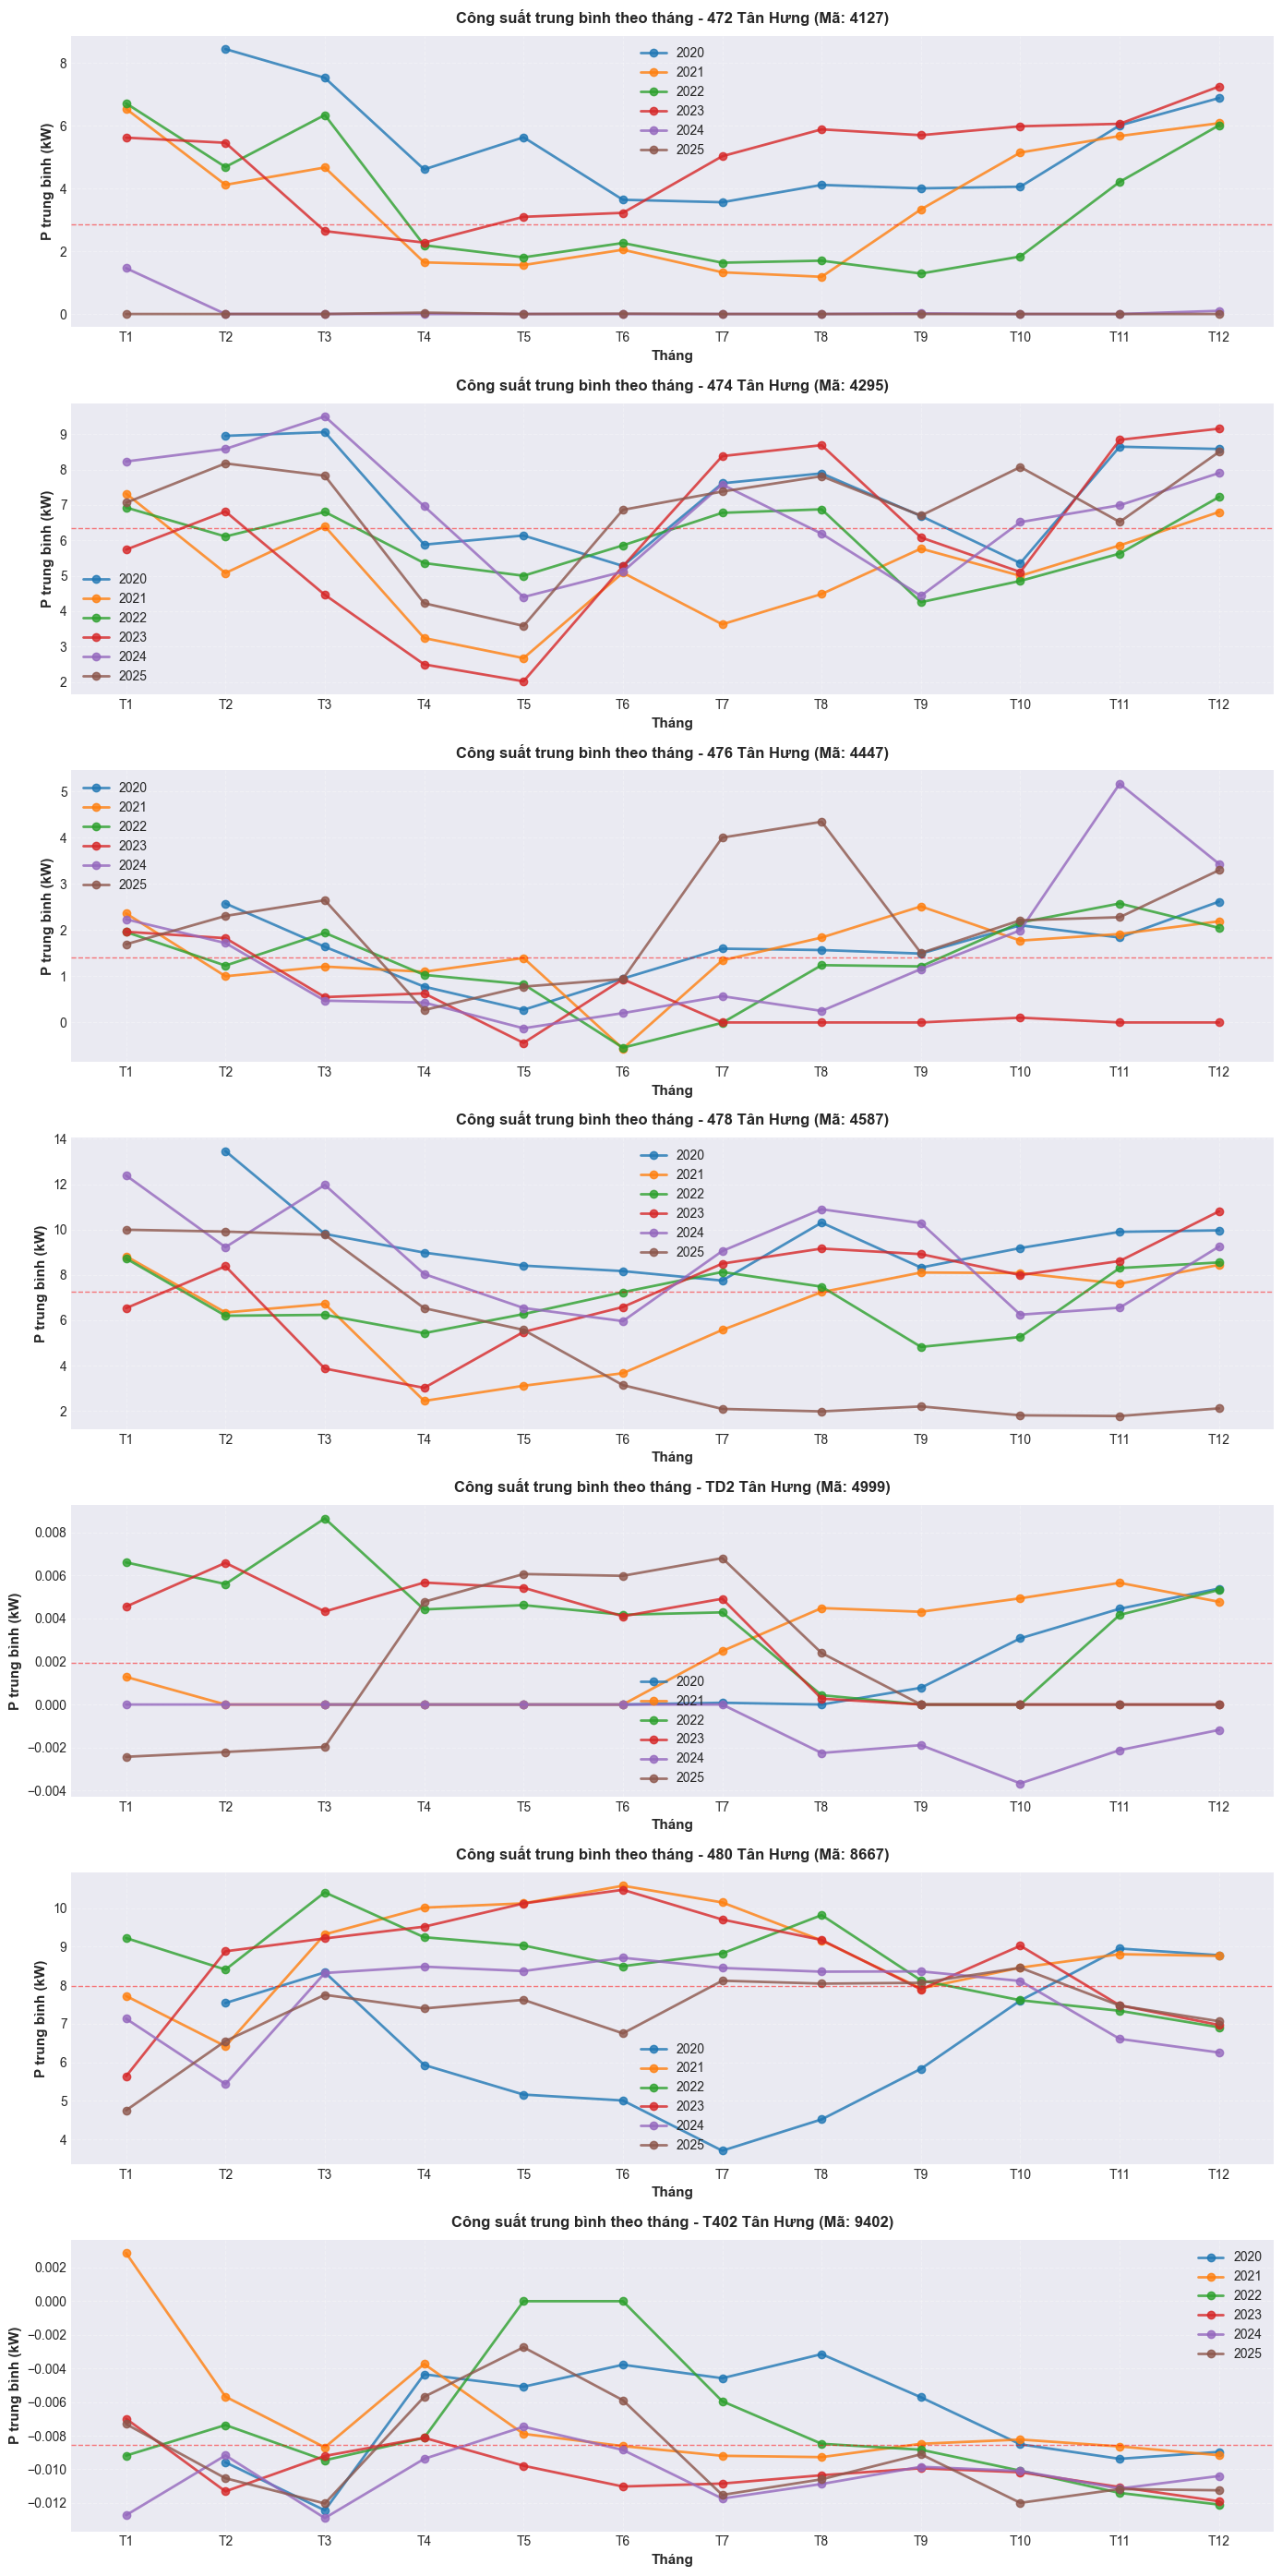


✅ Đã vẽ xong biểu đồ cho tất cả trạm!

THỐNG KÊ TỔNG HỢP:

472 Tân Hưng (Mã: 4127):
  P trung bình tổng thể: 2.85 kW
  P min: 0.00 kW
  P max: 8.44 kW
  Độ lệch chuẩn: 2.57 kW
  Tháng cao nhất: 2/2020 = 8.44 kW
  Tháng thấp nhất: 2/2024 = 0.00 kW

474 Tân Hưng (Mã: 4295):
  P trung bình tổng thể: 6.36 kW
  P min: 2.02 kW
  P max: 9.50 kW
  Độ lệch chuẩn: 1.73 kW
  Tháng cao nhất: 3/2024 = 9.50 kW
  Tháng thấp nhất: 5/2023 = 2.02 kW

476 Tân Hưng (Mã: 4447):
  P trung bình tổng thể: 1.42 kW
  P min: -0.57 kW
  P max: 5.17 kW
  Độ lệch chuẩn: 1.14 kW
  Tháng cao nhất: 11/2024 = 5.17 kW
  Tháng thấp nhất: 6/2021 = -0.57 kW

478 Tân Hưng (Mã: 4587):
  P trung bình tổng thể: 7.24 kW
  P min: 1.77 kW
  P max: 13.46 kW
  Độ lệch chuẩn: 2.71 kW
  Tháng cao nhất: 2/2020 = 13.46 kW
  Tháng thấp nhất: 11/2025 = 1.77 kW

TD2 Tân Hưng (Mã: 4999):
  P trung bình tổng thể: 0.00 kW
  P min: -0.00 kW
  P max: 0.01 kW
  Độ lệch chuẩn: 0.00 kW
  Tháng cao nhất: 3/2022 = 0.01 kW
  Tháng thấp nhất: 10/202

In [ ]:
## THỐNG KÊ P TRUNG BÌNH THEO THÁNG VÀ NĂM CHO TỪNG TRẠM

print("=" * 80)
print("THỐNG KÊ P TRUNG BÌNH THEO THÁNG VÀ NĂM (THEO MaDiemDo)")
print("=" * 80)

# Thêm cột năm và tháng
df_all['year'] = df_all['TIME'].dt.year
df_all['month'] = df_all['TIME'].dt.month

# Tính P trung bình theo tháng, năm, và trạm
monthly_avg = df_all.groupby(['MaDiemDo', 'TenDiemDo', 'year', 'month'])['P_kW'].mean().reset_index()
monthly_avg.columns = ['MaDiemDo', 'TenDiemDo', 'year', 'month', 'P_avg']

# In bảng thống kê
print("\nBẢNG THỐNG KÊ P TRUNG BÌNH (kW):")
print(f"{'Trạm':<20} {'Năm':<8} {'Tháng':<8} {'P_avg (kW)':<15}")
print("-" * 60)

for station_id in sorted(monthly_avg['MaDiemDo'].unique()):
    station_data = monthly_avg[monthly_avg['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    
    print(f"\n{station_name} (Mã: {station_id}):")
    for _, row in station_data.iterrows():
        print(f"  {row['year']:<8} {row['month']:<8} {row['P_avg']:<15.2f}")

# Vẽ biểu đồ cho từng trạm
print("\n" + "=" * 80)
print("VẼ BIỂU ĐỒ P TRUNG BÌNH THEO THÁNG VÀ NĂM")
print("=" * 80)

# Lấy danh sách trạm
stations = sorted(df_all['MaDiemDo'].unique())
years = sorted(df_all['year'].unique())

# Tạo figure với nhiều subplot (1 subplot cho mỗi trạm)
fig, axes = plt.subplots(len(stations), 1, figsize=(14, 4 * len(stations)))

# Nếu chỉ có 1 trạm, axes không phải là array
if len(stations) == 1:
    axes = [axes]

# Màu sắc cho từng năm
colors = plt.cm.tab10(range(len(years)))

for idx, station_id in enumerate(stations):
    ax = axes[idx]
    
    # Lọc data của trạm này
    station_data = monthly_avg[monthly_avg['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    
    # Vẽ đường cho từng năm
    for year_idx, year in enumerate(years):
        year_data = station_data[station_data['year'] == year].sort_values('month')
        
        if len(year_data) > 0:
            ax.plot(year_data['month'], year_data['P_avg'], 
                   marker='o', linewidth=2, markersize=6,
                   label=f'{year}', color=colors[year_idx], alpha=0.8)
    
    # Định dạng biểu đồ
    ax.set_xlabel('Tháng', fontsize=11, fontweight='bold')
    ax.set_ylabel('P trung bình (kW)', fontsize=11, fontweight='bold')
    ax.set_title(f'Công suất trung bình theo tháng - {station_name} (Mã: {station_id})', 
                fontsize=12, fontweight='bold', pad=10)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'T8', 'T9', 'T10', 'T11', 'T12'])
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='best', fontsize=10, framealpha=0.9)
    
    # Thêm đường ngang cho giá trị trung bình tổng thể
    overall_avg = station_data['P_avg'].mean()
    ax.axhline(y=overall_avg, color='red', linestyle='--', linewidth=1, 
              alpha=0.5, label=f'TB tổng: {overall_avg:.2f} kW')

plt.tight_layout()
plt.show()

print("\n✅ Đã vẽ xong biểu đồ cho tất cả trạm!")

# Thống kê tổng hợp
print("\n" + "=" * 80)
print("THỐNG KÊ TỔNG HỢP:")
print("=" * 80)

for station_id in sorted(monthly_avg['MaDiemDo'].unique()):
    station_data = monthly_avg[monthly_avg['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    
    print(f"\n{station_name} (Mã: {station_id}):")
    print(f"  P trung bình tổng thể: {station_data['P_avg'].mean():.2f} kW")
    print(f"  P min: {station_data['P_avg'].min():.2f} kW")
    print(f"  P max: {station_data['P_avg'].max():.2f} kW")
    print(f"  Độ lệch chuẩn: {station_data['P_avg'].std():.2f} kW")
    
    # Tháng có P cao nhất và thấp nhất
    max_row = station_data.loc[station_data['P_avg'].idxmax()]
    min_row = station_data.loc[station_data['P_avg'].idxmin()]
    
    print(f"  Tháng cao nhất: {int(max_row['month'])}/{int(max_row['year'])} = {max_row['P_avg']:.2f} kW")
    print(f"  Tháng thấp nhất: {int(min_row['month'])}/{int(min_row['year'])} = {min_row['P_avg']:.2f} kW")

# Xóa cột tạm
df_all = df_all.drop(columns=['year', 'month'])

print("\n" + "=" * 80)
print("✅ Đã hoàn thành thống kê P trung bình!")
print("=" * 80)


In [ ]:
## BỎ TRẠM 4999, 9402, VÀ 4127, SAU ĐÓ XUẤT FILE CSV
print("=" * 80)
print("BỎ TRẠM 4999, 9402, VÀ 4127, SAU ĐÓ XUẤT FILE CSV")
print("=" * 80)

# Thống kê trước khi bỏ
print(f"\nTRƯỚC KHI BỎ TRẠM:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số trạm: {df_all['MaDiemDo'].nunique()}")

# Thống kê trạm 4999
station_4999 = df_all[df_all['MaDiemDo'] == 4999]
if len(station_4999) > 0:
    station_name = station_4999['TenDiemDo'].iloc[0]
    has_data = station_4999['P_kW'].notna().sum()
    nan_count = station_4999['P_kW'].isna().sum()
    print(f"\nThông tin trạm 4999:")
    print(f"  Tên: {station_name}")
    print(f"  Tổng records: {len(station_4999):,}")
    print(f"  Có data: {has_data:,}")
    print(f"  Thiếu data: {nan_count:,}")

# Thống kê trạm 9402
station_9402 = df_all[df_all['MaDiemDo'] == 9402]
if len(station_9402) > 0:
    station_name = station_9402['TenDiemDo'].iloc[0]
    has_data = station_9402['P_kW'].notna().sum()
    nan_count = station_9402['P_kW'].isna().sum()
    print(f"\nThông tin trạm 9402:")
    print(f"  Tên: {station_name}")
    print(f"  Tổng records: {len(station_9402):,}")
    print(f"  Có data: {has_data:,}")
    print(f"  Thiếu data: {nan_count:,}")

# Thống kê trạm 4127
station_4127 = df_all[df_all['MaDiemDo'] == 4127]
if len(station_4127) > 0:
    station_name = station_4127['TenDiemDo'].iloc[0]
    has_data = station_4127['P_kW'].notna().sum()
    nan_count = station_4127['P_kW'].isna().sum()
    print(f"\nThông tin trạm 4127:")
    print(f"  Tên: {station_name}")
    print(f"  Tổng records: {len(station_4127):,}")
    print(f"  Có data: {has_data:,}")
    print(f"  Thiếu data: {nan_count:,}")

# Lọc bỏ trạm 4999, 9402, và 4127
df_all = df_all[~df_all['MaDiemDo'].isin([4999, 9402, 4127])].copy()
df_all = df_all.reset_index(drop=True)

print(f"\n{'='*80}")
print(f"ĐÃ XÓA TRẠM 4999, 9402, VÀ 4127")
print(f"{'='*80}")

# Thống kê sau khi bỏ
print(f"\nSAU KHI BỎ 3 TRẠM:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số records có data: {df_all['P_kW'].notna().sum():,}")
print(f"  Số records thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")
print(f"  Khoảng thời gian: {df_all['TIME'].min()} → {df_all['TIME'].max()}")
print(f"  Số trạm: {df_all['MaDiemDo'].nunique()}")

# Danh sách trạm còn lại
print(f"\nCác trạm còn lại:")
for station_id in sorted(df_all['MaDiemDo'].unique()):
    station_data = df_all[df_all['MaDiemDo'] == station_id]
    station_name = station_data['TenDiemDo'].iloc[0]
    has_data = station_data['P_kW'].notna().sum()
    total = len(station_data)
    print(f"  {station_name} (Mã: {station_id}): {total:,} records ({has_data:,} có data)")

# XUẤT FILE CSV
print(f"\n{'='*80}")
print(f"XUẤT FILE CSV")
print(f"{'='*80}")

# Kiểm tra thông tin trước khi xuất
print(f"\nThông tin data sẽ xuất:")
print(f"  Tổng số records: {len(df_all):,}")
print(f"  Số records có data: {df_all['P_kW'].notna().sum():,}")
print(f"  Số records thiếu data (NaN): {df_all['P_kW'].isna().sum():,}")
print(f"  Khoảng thời gian: {df_all['TIME'].min()} → {df_all['TIME'].max()}")
print(f"  Số trạm: {df_all['MaDiemDo'].nunique()}")
print(f"  Số cột: {len(df_all.columns)}")

# Hiển thị các cột
print(f"\nCác cột trong file:")
for idx, col in enumerate(df_all.columns, 1):
    dtype = df_all[col].dtype
    nan_count = df_all[col].isna().sum()
    print(f"  {idx:2d}. {col:<20} ({dtype}, {nan_count:,} NaN)")

# Tên file output
output_file = 'TanHung_30min_cleaned_4stations_6years.csv'

# Xuất file
print(f"\nĐang xuất file: {output_file}")
df_all.to_csv(output_file, index=False, encoding='utf-8-sig')

# Kiểm tra file đã tạo
import os
if os.path.exists(output_file):
    file_size = os.path.getsize(output_file) / (1024 * 1024)  # MB
    print(f"\n✅ Đã xuất file thành công!")
    print(f"   Tên file: {output_file}")
    print(f"   Kích thước: {file_size:.2f} MB")
    print(f"   Vị trí: {os.path.abspath(output_file)}")
else:
    print(f"\n⚠️ Lỗi: Không tìm thấy file sau khi xuất!")

print("\n" + "=" * 80)
print("✅ Hoàn thành!")
print(f"   - Đã bỏ trạm 4999, 9402, và 4127")
print(f"   - Còn lại 4 trạm")
print(f"   - File đã xuất: {output_file}")
print("=" * 80)


BỎ TRẠM 4999, 9402, VÀ 4127, SAU ĐÓ XUẤT FILE CSV

TRƯỚC KHI BỎ TRẠM:
  Tổng số records: 723,408
  Số trạm: 7

Thông tin trạm 4999:
  Tên: TD2 Tân Hưng
  Tổng records: 103,344
  Có data: 98,376
  Thiếu data: 4,968

Thông tin trạm 9402:
  Tên: T402 Tân Hưng
  Tổng records: 103,344
  Có data: 101,890
  Thiếu data: 1,454

Thông tin trạm 4127:
  Tên: 472 Tân Hưng
  Tổng records: 103,344
  Có data: 102,187
  Thiếu data: 1,157

ĐÃ XÓA TRẠM 4999, 9402, VÀ 4127

SAU KHI BỎ 3 TRẠM:
  Tổng số records: 413,376
  Số records có data: 408,558
  Số records thiếu data (NaN): 4,818
  Khoảng thời gian: 2020-02-09 00:00:00 → 2025-12-31 23:30:00
  Số trạm: 4

Các trạm còn lại:
  474 Tân Hưng (Mã: 4295): 103,344 records (102,155 có data)
  476 Tân Hưng (Mã: 4447): 103,344 records (102,126 có data)
  478 Tân Hưng (Mã: 4587): 103,344 records (102,142 có data)
  480 Tân Hưng (Mã: 8667): 103,344 records (102,135 có data)

XUẤT FILE CSV

Thông tin data sẽ xuất:
  Tổng số records: 413,376
  Số records có data: 4